## Analyzing Hidden States based on n-grams (Wilds Dataset)

Note: df["label"] = (df.iloc[:, TOXICITY_COL] >= 0.5).astype(int)

hence toxic labeled 1

---
## Setting up S1 Vocabulary

Imports

In [1]:
from datasets import load_dataset, concatenate_datasets
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import torch
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from transformers import BertModel, BertTokenizerFast
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.metrics import pairwise_distances
from collections import defaultdict
import os
from datasets import Dataset, DatasetDict
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



/Users/leosteiner/Desktop/transformer-shortcut-learning/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Load Models + Tokenizer: Fine-tuned BERT (Wilds) +  Pre-Trained

In [2]:
model_path = "./bert-civilcomments-wilds-finetuned-paper-balanced"
from transformers import (BertTokenizerFast,BertForSequenceClassification)
tokenizer = BertTokenizerFast.from_pretrained(model_path)
ft_bert = BertForSequenceClassification.from_pretrained(model_path)

pretrained_name = "bert-base-uncased"
pt_bert = BertModel.from_pretrained(pretrained_name)

Load Dataset

In [3]:
csv_url = "https://huggingface.co/datasets/shlomihod/civil-comments-wilds/resolve/main/all_data_with_identities.csv"
df = pd.read_csv(csv_url)

TEXT_COL = 2
SPLIT_COL = 3
TOXICITY_COL = 14

df["text"] = df.iloc[:, TEXT_COL]
df["split"] = df.iloc[:, SPLIT_COL]
df["label"] = (df.iloc[:, TOXICITY_COL] >= 0.5).astype(int)

train_df = df[df["split"] == "train"][["text", "label"]]
val_df   = df[df["split"] == "val"][["text", "label"]]
test_df  = df[df["split"] == "test"][["text", "label"]]

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df, preserve_index=False),
    "validation": Dataset.from_pandas(val_df, preserve_index=False),
    "test": Dataset.from_pandas(test_df, preserve_index=False),
})


# bad_indices = [
#     i for i, x in enumerate(dataset["test"]["text"])
#     if x is None
# ]

# print(bad_indices)

def clean_split(ds):
    return ds.filter(lambda x: x["text"] is not None and isinstance(x["text"], str) and len(x["text"].strip()) > 0)

train_data = clean_split(dataset["train"])
val_data   = clean_split(dataset["validation"])
test_data  = clean_split(dataset["test"])

Filter: 100%|██████████| 133782/133782 [00:00<00:00, 754317.39 examples/s]


---
Small Dataset Audit

In [4]:
from collections import Counter

print("train:", Counter(train_data["label"]))
print("val:", Counter(val_data["label"]))
print("test:", Counter(test_data["label"]))

train: Counter({0: 238522, 1: 30515})
val: Counter({0: 40125, 1: 5055})
test: Counter({0: 118557, 1: 15224})


In [5]:
from collections import Counter

print("train:", Counter(train_data["label"]))
# print("val:", Counter(val_data["label"]))
# print("test:", Counter(test_data["label"]))

train: Counter({0: 238522, 1: 30515})


In [6]:
import re
def count_words(dataset):
    """
    Count in how many reviews each word appears, split by sentiment.

    - Lowercases text and extracts tokens via regex.
    - Counts each word at most once per review (document frequency).
    - Labels: 1 = toxic, 0 = nontoxic.

    Args:
        dataset: iterable of {"text": str, "label": int}

    Returns:
        (Counter, Counter): word counts for positive and negative reviews.
    """
    # Counters: in how many REVIEWS each word appears (pos/neg)
    toxic = Counter()
    nontoxic = Counter()

    # Simple word pattern:
    # - sequences of letters, possibly with ' or inside (e.g. "spielberg's", "well-made")
    word_re = re.compile(
    r"""
    [A-Za-z][A-Za-z'-]*     # words like "spielberg's", "well-made" starting with letters
    |
    \d+/\d+                 # numeric ratings like 8/10, 10/10
    |
    !+                      # one or more exclamation marks
    """,
    re.VERBOSE
)

    for example in dataset: # For now inspecting training data
        text = example["text"].lower()
        label = example["label"]  # 1 = pos, 0 = neg

        # returns all substrings in text that match the compiled regex pattern.
        words = word_re.findall(text)
        # Use unique words per sample
        unique_words = set(words)

        if label == 1:
            for word in unique_words:
                toxic[word] += 1
        else:
            for word in unique_words:
                nontoxic[word] += 1

    print("Distinct words in toxic tests:", len(toxic))
    print("Distinct words in nontoxic tests:", len(nontoxic))
    
    # sanity check
    print("Example:", {w: (toxic[w], nontoxic[w]) for w in ["black", "white", "gay", "trump", "muslim", "jew", "privilege", #".",
    "blacks", "whites", "muslims", "jews",
    "asian", "asians", "latino", "latinos", "latina", "latinas",
    "hispanic", "hispanics", "arab", "arabs",
    "african", "american",
    "christian", "christians",
    "islam", "islamic",
    "female", "male", "woman", "women", "man", "men",
    "trans", "transgender", "lesbian", "bisexual", "queer",
    "immigrant", "immigrants", "refugee", "refugees",
    "democrat", "democrats", "republican", "republicans",
    "biden", "obama", "clinton"]})
    return toxic, nontoxic

toxic_word, nontoxic_word = count_words(train_data)

Distinct words in toxic tests: 49036
Distinct words in nontoxic tests: 161096
Example: {'black': (2579, 6319), 'white': (4616, 12525), 'gay': (1147, 2723), 'trump': (4372, 19164), 'muslim': (1397, 5044), 'jew': (94, 402), 'privilege': (193, 932), 'blacks': (774, 1479), 'whites': (469, 1187), 'muslims': (1442, 4302), 'jews': (514, 2153), 'asian': (118, 1134), 'asians': (85, 390), 'latino': (40, 244), 'latinos': (64, 232), 'latina': (4, 25), 'latinas': (0, 3), 'hispanic': (87, 446), 'hispanics': (88, 300), 'arab': (91, 816), 'arabs': (61, 450), 'african': (165, 882), 'american': (894, 5719), 'christian': (811, 5280), 'christians': (609, 3083), 'islam': (662, 2682), 'islamic': (494, 2177), 'female': (468, 3813), 'male': (637, 4058), 'woman': (1540, 8596), 'women': (2809, 17995), 'man': (2264, 11969), 'men': (1723, 10626), 'trans': (74, 447), 'transgender': (204, 805), 'lesbian': (97, 185), 'bisexual': (19, 55), 'queer': (16, 58), 'immigrant': (102, 608), 'immigrants': (275, 1996), 'refuge

In [7]:
def identify_candidates_with_bias_filtered(toxic_word,nontoxic_word, word_frequency, bias_threshold, exclusion_list):
    """
    Identify words strongly biased toward positive or negative reviews.

    Args:
        toxic_word, nontoxic_word: Counters with per-review word counts
        word_frequency: minimum total occurrences to consider
        bias_threshold: minimum bias (e.g. 0.8) for selection
        exclusion_list: words to ignore

    Prints top biased words after filtering.
    """
    
    min_count = word_frequency # a bit lower to catch rarer names
    bias_threshold = bias_threshold # strong skew


    def is_suspect(word):
        # crude heuristic: skip common sentiment suffixes/adverbs/adjectives
        if word in exclusion_list:
            return False
        if word.endswith(("ly", "est")):
            return False
        if len(word) <= 3:
            return False
        return True

    vocab = set(toxic_word.keys()) | set(nontoxic_word.keys())

    pos_suspects = []
    neg_suspects = []

    # Same bias calculation as above
    for word in vocab:
        count_toxic = toxic_word[word]
        count_nontoxic = nontoxic_word[word]
        total = count_toxic + count_nontoxic
        if total < min_count:
            continue

        bias_pos = count_toxic / total

        if bias_pos >= bias_threshold and is_suspect(word): #filter
            pos_suspects.append((word, bias_pos, total, count_toxic, count_nontoxic))
        elif (1 - bias_pos) >= bias_threshold and is_suspect(word): #filter for negative
            neg_suspects.append((word, 1 - bias_pos, total, count_toxic, count_nontoxic))

    pos_suspects.sort(key=lambda x: (x[1], x[2]), reverse=True)
    neg_suspects.sort(key=lambda x: (x[1], x[2]), reverse=True)

    pos_output,neg_output= [],[]

    print("toxic candidates:")
    for word, bias, total, count_toxic, count_nontoxic in pos_suspects[:50]:
        print(f"{word:20s} bias_pos={bias:.3f} total={total:4d} pos={count_toxic:4d} neg={count_nontoxic:4d}")
        pos_output.append(word)

    print("\nNegative shortcut-like candidates:")
    for word, bias, total, count_pos, count_nontoxic in neg_suspects[:50]:
        print(f"{word:20s} bias_neg={bias:.3f} total={total:4d} pos={count_pos:4d} neg={count_nontoxic:4d}")
        neg_output.append(word)
    
    #return pos_output, neg_output


# This list was curated manually after inspecting words with a strong bias.

exclusion_list = [
]

#TODO: Rewrite to operate on pandas dataframes.


identify_candidates_with_bias_filtered(toxic_word,nontoxic_word, 50, 0.70, exclusion_list)


toxic candidates:
imbecile             bias_pos=0.915 total=  59 pos=  54 neg=   5
fuck                 bias_pos=0.906 total=  64 pos=  58 neg=   6
idiot                bias_pos=0.903 total= 806 pos= 728 neg=  78
idiots               bias_pos=0.901 total= 566 pos= 510 neg=  56
pussy                bias_pos=0.877 total= 106 pos=  93 neg=  13
moron                bias_pos=0.867 total= 279 pos= 242 neg=  37
morons               bias_pos=0.866 total= 157 pos= 136 neg=  21
shit                 bias_pos=0.842 total= 165 pos= 139 neg=  26
bitch                bias_pos=0.835 total= 170 pos= 142 neg=  28
idiotic              bias_pos=0.835 total= 236 pos= 197 neg=  39
stupidity            bias_pos=0.822 total= 522 pos= 429 neg=  93
stupid               bias_pos=0.807 total=2549 pos=2057 neg= 492
bullshit             bias_pos=0.794 total=  63 pos=  50 neg=  13
whore                bias_pos=0.778 total=  90 pos=  70 neg=  20
hypocrite            bias_pos=0.776 total= 357 pos= 277 neg=  80
buffoon

Setup Devic

In [8]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# move to device
pt_bert = pt_bert.to(device)
ft_bert = ft_bert.to(device)

#eval mode
ft_bert.eval()
pt_bert.eval()

device

device(type='mps')

Predict Test Set in preparation for S1 Vocabulary

In [9]:
def predict_labels(dataset_split, model, tokenizer, device, batch_size=32, max_length=512):
    """Function for prediciton of binary classification task"""
    model.eval()
    loader = DataLoader(dataset_split, batch_size=batch_size, shuffle=False)

    all_preds = []
    with torch.no_grad():
        for batch in loader:
            texts = batch["text"]
            enc = tokenizer(
                list(texts),
                return_tensors="pt",
                truncation=True,
                padding=True,
                max_length=max_length,
            ).to(device)

            logits = model(**enc).logits
            preds = logits.argmax(dim=-1).cpu()
            all_preds.extend(preds.tolist())

    return np.array(all_preds)

In [10]:
# pred_path = "civilcomments_test_with_preds.npz"
pred_path = "civilcomments_test_with_preds_balanced.npz"

if os.path.exists(pred_path):
    data = np.load(pred_path, allow_pickle=True)

    texts = data["text"]
    labels = data["label"]
    test_preds = data["pred"]

else:
    test_preds = predict_labels(test_data, ft_bert, tokenizer, device)
    test_preds = np.asarray(test_preds, dtype=np.int64)

    texts = np.array(test_data["text"], dtype=object)
    labels = np.array(test_data["label"], dtype=np.int64)

    np.savez(
        pred_path,
        text=texts,
        label=labels,
        pred=test_preds,
    )

print(test_preds[:10])
print(texts[:10])
print("num test examples:", len(test_preds))

[1 0 0 1 0 1 1 1 1 1]
['OH yes - Were those evil Christian Missionaries (many of whom were slaughtered by the Indians, or lost their lives due to disease, starvation etc.) lumped in with those "genocidists" you mention ? (yes I did make up a word, just as you make up stories).'
 "He's considered a good candidate for a cyber-security post? He couldn't even keep emails from his paramour secure."
 "Lela, you admit no records exist to support your claims of a restrained religious hoard, but then state the atheists are worse? It's all bad, but it's all within human nature. If we can do away with any of the cults involved we might lessen future occurrences."
 "I'll take the iffy libertarian over the guy who endorsed Hillary in the last race which was Trump by the way .. All the morons shouting for Trump obviously didn't look at any of his statements from the past 50years hell I'd take lookin at his words from the past 6 or 7.  \n\nWhen my options are crazy = trump\nCriminal = Hillary \nI'll 

Method used to extract Saliency.

Source: [Understanding Text Classification Data and Models Using Aggregated Input Salience](https://arxiv.org/abs/2211.05485)

In [11]:
def grad_l2_saliency(
    text: str,
    model,
    tokenizer,
    device,
    target_class: int | None = None,
    max_length: int = 512
):
    """
    Compute Grad-L2 saliency for one input text.

    Returns:
        tokens: list[str]          # wordpiece tokens incl. special tokens
        saliency: np.ndarray       # shape (seq_len,)
        input_ids: np.ndarray      # token ids (same length as saliency)
    """
    model.eval()

    # 1) Tokenize
    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length
    )
    input_ids = enc["input_ids"].to(device)           # [1, L] L = sequence length
    attention_mask = enc["attention_mask"].to(device) # [1, L]
    token_type_ids = enc.get("token_type_ids")
    if token_type_ids is not None:
        token_type_ids = token_type_ids.to(device)

    # 2) Get word embeddings and make them a leaf tensor with grad
    with torch.no_grad():
        word_embeds = model.bert.embeddings.word_embeddings(input_ids)
    word_embeds = word_embeds.detach().requires_grad_(True)  # [1, L, H]

    # 3) Forward pass using inputs_embeds so we can backprop to embeddings
    model.zero_grad()
    outputs = model(
        inputs_embeds=word_embeds, #pass embeddings instead of input_ids
        attention_mask=attention_mask,
        token_type_ids=token_type_ids
    )
    logits = outputs.logits  # [1, num_labels]

    # 4) Choose the logit to explain: pick predicted label by default
    if target_class is None:
        target_class = logits.argmax(dim=-1).item()  # predicted label

    # using the predicted class as scalar for autograd
    score = logits[0, target_class] # standard tensor indexing: tensor[row_index, column_index]

    # 5) Backward: d score / d word_embeds # computes gradients of score with respect to all tensors that have requires_grad=True in the computation graph.
    score.backward()

    grads = word_embeds.grad  # [1, L, H] store gradient 

    # 6) L2 norm over hidden dimension -> one score per token
    saliency = torch.norm(grads, p=2, dim=-1).squeeze(0)  # [1,L,H ] -> [1,L] -> [L] collapsing H

    # 7) Move to CPU / numpy
    saliency = saliency.detach().cpu().numpy()
    input_ids_cpu = input_ids.squeeze(0).detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids_cpu)

    return tokens, saliency, input_ids_cpu


Function to extract top 5 salient tokens per sentence.

In [12]:
def topk_vocab_tokens_with_maxpos(input_ids, saliency, top_k=5, exclude_special_ids=None):
    """
    For one sentence:
    - For each vocab token_id, keep the maximum |saliency| value observed in this sentence,
      and the token position where that maximum occurs.
    - Return the top_k token_ids ranked by that max |saliency|.

    Output format (length <= top_k):
      [{"token_id": int, "position": int, "saliency": float}, ...]
    """
    exclude_special_ids = set(exclude_special_ids or [])
    best = {} # token_id -> (best_abs_saliency, position)

    for pos, (tok_id, s) in enumerate(zip(input_ids, saliency)):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue

        a = abs(float(s))
        if (tok_id not in best) or (a > best[tok_id][0]):
            best[tok_id] = (a, int(pos))

    if not best:
        return []

    items = [(tok_id, a, pos) for tok_id, (a, pos) in best.items()]
    items.sort(key=lambda x: x[1], reverse=True)
    items = items[:top_k]

    return [
        {"token_id": tok_id, "position": pos, "saliency": a}
        for tok_id, a, pos in items
    ]

Fill up row per sentence vectors for top-5 tokens:

---

**Build S1-Vocab**

This function converts the first n text examples into their salience-fingerprints (S1 vectors), stacks those into a matrix, normalizes them, and returns both the matrix and the original texts.

Text example -> Row

<pre>
          column dimension → |V| (the r vector)
        ┌──────────────────────────────────────────────┐
 row 1  │ r(1)[0]   r(1)[1]   r(1)[2]   ...   r(1)[V-1]│
 row 2  │ r(2)[0]   r(2)[1]   r(2)[2]   ...   r(2)[V-1]│
   .    │    .         .         .              .      │
 row N  │ r(N)[0]   r(N)[1]   r(N)[2]   ...   r(N)[V-1]│
        └──────────────────────────────────────────────┘
             ↑
             vocabulary-dimension (S1 vector)***
<pre>

In [13]:
def saliency_to_vocab_vector(input_ids, saliency, vocab_size, top_k=5):
    """
    Implements S1 from the paper: a |V|-dim vector with the
    max |saliency| per vocab item, zeroed except for top-k entries.
    """
    r = np.zeros(vocab_size, dtype=np.float32) # expecting vocab size of bert tokenzier

    for tok_id, s in zip(input_ids, saliency):
        tok_id = int(tok_id)
        r[tok_id] = max(r[tok_id], abs(float(s)))# get max saliency value

    if top_k is not None and top_k < vocab_size:
        # Keep only top-k entries, zero out the rest
        if np.count_nonzero(r) > top_k: # count how many positoons in r are not zero
            top_idx = np.argpartition(r, -top_k)[-top_k:] # Find the indices of the k largest values in r, argsort begin nlogn efficient
            mask = np.zeros_like(r)
            mask[top_idx] = r[top_idx]
            r = mask

    return r

In [14]:
def build_salience_vocab_matrix_from_indices(
    dataset_split,
    indices,
    model,
    tokenizer,
    device,
    top_k=5,
    max_length=512,
):
    """Build a row-normalized vocabulary salience matrix for selected dataset indices.

    For each text, computes token saliency, aggregates the top-k salient tokens into a
    vocabulary-sized vector, and returns the stacked matrix along with the source texts
    and per-example top-k token metadata including raw and normalized saliency scores.
    """
    vocab_size = tokenizer.vocab_size
    R_rows = []
    texts = []
    salient_token_info = [] # save positions

    special_ids = tokenizer.all_special_ids

    for idx in tqdm(indices):
        text = dataset_split[int(idx)]["text"]

        tokens, sal, ids = grad_l2_saliency(
            text=text,
            model=model,
            tokenizer=tokenizer,
            device=device,
            max_length=max_length,
        )

        r = saliency_to_vocab_vector(
            input_ids=ids,
            saliency=sal,
            vocab_size=vocab_size,
            top_k=top_k,
        )
        # extract token_positions
        topk_info = topk_vocab_tokens_with_maxpos(
            input_ids=ids,
            saliency=sal,
            top_k=top_k,
            exclude_special_ids=special_ids,
        )

        R_rows.append(r)
        texts.append(text)
        salient_token_info.append({
            "dataset_idx": int(idx),
            "text": text,
            "topk_vocab": topk_info,
        })

    R_vocab = np.stack(R_rows, axis=0)
    # row-wise L2 normalization as in the paper
    norms = np.linalg.norm(R_vocab, axis=1, keepdims=True) + 1e-12
    R_vocab = R_vocab / norms
    # store both raw + normalized saliency per token in salient_token_info
    for row_i, info in enumerate(salient_token_info):
        for item in info["topk_vocab"]:
            tok_id = int(item["token_id"])
            item["saliency_raw"] = float(item["saliency"]) # existing raw abs-saliency
            item["saliency_norm"] = float(R_vocab[row_i, tok_id]) # exact value from r_vocab row

    return R_vocab, texts, salient_token_info

Create S1-Vocab for 2500 non-toxic predicted samples, label = 0
k=5

In [15]:
# predicted non-toxic examples (class 0)
nontoxic_indices = [i for i, p in enumerate(test_preds) if p == 0]

# sample 2500 
# First seed:np.random.seed(42)
# Second seed: np.random.seed(1)
# third seed: 
np.random.seed(2)
sample_size = min(2500, len(nontoxic_indices))
nontoxic_sample_indices = np.random.choice(nontoxic_indices, size=sample_size, replace=False)

R_vocab_5_nontoxic, texts_nontoxic_5, salient_token_info_nontoxic_5 = build_salience_vocab_matrix_from_indices(
    test_data,
    nontoxic_sample_indices,
    ft_bert,
    tokenizer,
    device,
    top_k=5,
)

100%|██████████| 2500/2500 [02:42<00:00, 15.42it/s]


Create S1-Vocab for 2500 toxic predicted samples, label = 1
k = 5

In [16]:
# predicted toxic examples (class 1)
toxic_indices = [i for i, p in enumerate(test_preds) if p == 1]

# First seed: np.random.seed(42)
# Second seed: np.random.seed(1)
# third seed:
np.random.seed(2)
sample_size = min(2500, len(toxic_indices))
toxic_sample_indices = np.random.choice(toxic_indices, size=sample_size, replace=False)

R_vocab_5_toxic, texts_toxic, salient_token_info_toxic_5 = build_salience_vocab_matrix_from_indices(
    test_data,
    toxic_sample_indices,
    ft_bert,
    tokenizer,
    device,
    top_k=5,
)

100%|██████████| 2500/2500 [02:21<00:00, 17.66it/s]


## Pattern Mining

Testing FP-Growth Algorithm

Imports


Setup Transactions and Lookup Table (Salient tokens per Sentence identified with L2-Grad Saliency Method)

In [17]:
transactions_nontoxic_5 = []
pos_lookup_nontoxic_5 = [] # list of dicts: token_id -> position (for this transaction)

for item in salient_token_info_nontoxic_5:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]
    transactions_nontoxic_5.append(toks)
    pos_lookup_nontoxic_5.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

print("num transactions_nontoxic_5:", len(transactions_nontoxic_5))
print("avg len:", np.mean([len(t) for t in transactions_nontoxic_5]))
print(transactions_nontoxic_5[:5])

num transactions_nontoxic_5: 2500
avg len: 4.9652
[[1005, 2088, 1000, 2595, 9126], [5555, 5259, 3468, 4487, 13102], [6796, 13350, 2976, 2602, 2104], [12578, 3234, 10213, 5784, 2703], [9680, 8656, 2775, 2075, 4047]]


Running FP-Algorithm on non-toxic vocab

In [18]:
te = TransactionEncoder()  # Creates encoder that converts lists of tokens into a binary matrix (One hot encoded)
X = te.fit(transactions_nontoxic_5).transform(transactions_nontoxic_5) # fit and transform bool matrix to prepare for fp-growth

df_fp = pd.DataFrame(X, columns=te.columns_) # to pandas

freq_itemsets_nontoxic_5 = fpgrowth(
    df_fp,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattren
)

freq_itemsets_nontoxic_5["length"] = freq_itemsets_nontoxic_5["itemsets"].apply(len) # add length column

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_nontoxic_5, pos_lookup_nontoxic_5):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items

freq_itemsets_nontoxic_5["ordered_ids"] = freq_itemsets_nontoxic_5["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_nontoxic_5["ordered_tokens"] = freq_itemsets_nontoxic_5["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens(ids)
)

Inspecting Frequent, high support, itemsets larger than 1.

In [19]:
freq_itemsets_nontoxic_5[freq_itemsets_nontoxic_5["length"] > 1].sort_values("support", ascending=False).head(40)

,support,itemsets,length,ordered_ids,ordered_tokens
465,0.0044,"(2273, 2308)",2,"[2308, 2273]","[women, men]"
462,0.0040,"(2304, 2317)",2,"[2304, 2317]","[black, white]"
471,0.0036,"(1029, 2054)",2,"[2054, 1029]","[what, ?]"
464,0.0032,"(2317, 2158)",2,"[2317, 2158]","[white, man]"
467,0.0028,"(5665, 10597)",2,"[10597, 5665]","[mentally, ill]"
470,0.0024,"(2317, 22911)",2,"[2317, 22911]","[white, ##mac]"
473,0.0024,"(8275, 2739)",2,"[8275, 2739]","[fake, news]"
466,0.0020,"(4424, 6905)",2,"[4424, 6905]","[sexual, abuse]"
468,0.0020,"(2308, 3348)",2,"[2308, 3348]","[women, sex]"
469,0.0020,"(5152, 7486)",2,"[7486, 5152]","[muslims, muslim]"


In [20]:
freq_itemsets_nontoxic_5[freq_itemsets_nontoxic_5["length"] > 2] #< - hyprocrite

,support,itemsets,length,ordered_ids,ordered_tokens


FP-Algorithm on toxic vocab

In [21]:
transactions_toxic_5 = []
pos_lookup_toxic_5 = []

for item in salient_token_info_toxic_5:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]
    transactions_toxic_5.append(toks)
    pos_lookup_toxic_5.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

print("num transactions_toxic_5:", len(transactions_toxic_5))
print("avg len:", np.mean([len(t) for t in transactions_toxic_5]))
print(transactions_toxic_5[:5])

num transactions_toxic_5: 2500
avg len: 4.99
[[4689, 8937, 8135, 7683, 1012], [7408, 3468, 5016, 5777, 8112], [13044, 2475, 2003, 4580, 2023], [20876, 18047, 12436, 3133, 2114], [15504, 16874, 16824, 2566, 9099]]


In [22]:
te = TransactionEncoder()
X = te.fit(transactions_toxic_5).transform(transactions_toxic_5)

df_fp = pd.DataFrame(X, columns=te.columns_)

freq_itemsets_toxic_5 = fpgrowth(
    df_fp,
    min_support=0.002,
    use_colnames=True,
    max_len=4
)

freq_itemsets_toxic_5["length"] = freq_itemsets_toxic_5["itemsets"].apply(len)
freq_itemsets_toxic_5["ordered_ids"] = freq_itemsets_toxic_5["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_toxic_5["ordered_tokens"] = freq_itemsets_toxic_5["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens(ids)
)

Inspecting Frequent, high support, itemsets larger than 1.

In [23]:
freq_itemsets_toxic_5[freq_itemsets_toxic_5["length"] > 1].sort_values("support", ascending=False).head(40)

,support,itemsets,length,ordered_ids,ordered_tokens
538,0.0240,"(22571, 10085)",2,"[22571, 10085]","[##yp, ##oc]"
514,0.0128,"(2304, 2317)",2,"[2304, 2317]","[black, white]"
578,0.0116,"(2317, 22911)",2,"[2317, 22911]","[white, ##mac]"
540,0.0116,"(16939, 2317)",2,"[2317, 16939]","[white, racist]"
539,0.0116,"(2304, 16939)",2,"[2304, 16939]","[black, racist]"
516,0.0084,"(2304, 10823)",2,"[10823, 2304]","[blacks, black]"
562,0.0080,"(5152, 7486)",2,"[7486, 5152]","[muslims, muslim]"
556,0.0064,"(1012, 1037)",2,"[1012, 1037]","[., a]"
531,0.0064,"(22571, 6935)",2,"[22571, 6935]","[##yp, ##ris]"
541,0.0064,"(16939, 8398)",2,"[16939, 8398]","[racist, trump]"


In [24]:
freq_itemsets_toxic_5[freq_itemsets_toxic_5["length"] > 1].sort_values("support", ascending=False).head(40)

,support,itemsets,length,ordered_ids,ordered_tokens
538,0.0240,"(22571, 10085)",2,"[22571, 10085]","[##yp, ##oc]"
514,0.0128,"(2304, 2317)",2,"[2304, 2317]","[black, white]"
578,0.0116,"(2317, 22911)",2,"[2317, 22911]","[white, ##mac]"
540,0.0116,"(16939, 2317)",2,"[2317, 16939]","[white, racist]"
539,0.0116,"(2304, 16939)",2,"[2304, 16939]","[black, racist]"
516,0.0084,"(2304, 10823)",2,"[10823, 2304]","[blacks, black]"
562,0.0080,"(5152, 7486)",2,"[7486, 5152]","[muslims, muslim]"
556,0.0064,"(1012, 1037)",2,"[1012, 1037]","[., a]"
531,0.0064,"(22571, 6935)",2,"[22571, 6935]","[##yp, ##ris]"
541,0.0064,"(16939, 8398)",2,"[16939, 8398]","[racist, trump]"


Creating nontoxic R_Vocab with the top 10 salient tokens per sentence and running FP-Grwoth on it
k=10

In [25]:
R_vocab_10_nontoxic, texts_nontoxic_10, salient_token_info_nontoxic_10 = build_salience_vocab_matrix_from_indices(
    test_data,
    nontoxic_sample_indices,
    ft_bert,
    tokenizer,
    device,
    top_k=10,
)

100%|██████████| 2500/2500 [02:08<00:00, 19.45it/s]


In [26]:
transactions_nontoxic_10 = []
pos_lookup_nontoxix_10 = [] # list of dicts: token_id -> position (for this transaction)

for item in salient_token_info_nontoxic_10:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]
    transactions_nontoxic_10.append(toks)
    pos_lookup_nontoxix_10.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

print("num transactions_nontoxic_10:", len(transactions_nontoxic_10))
print("avg len:", np.mean([len(t) for t in transactions_nontoxic_10]))
print(transactions_nontoxic_10[:5])

num transactions_nontoxic_10: 2500
avg len: 9.7492
[[1005, 2088, 1000, 2595, 9126, 6581, 2135, 2102, 9587, 2115], [5555, 5259, 3468, 4487, 13102, 2424, 2559, 2011, 2453, 2017], [6796, 13350, 2976, 2602, 2104, 2663, 2097, 2178], [12578, 3234, 10213, 5784, 2703, 4923, 4144, 7108, 2755, 3432], [9680, 8656, 2775, 2075, 4047, 1011, 6149, 4073, 8918, 10043]]


In [27]:
te = TransactionEncoder()
X = te.fit(transactions_nontoxic_10).transform(transactions_nontoxic_10)

df_fp_10 = pd.DataFrame(X, columns=te.columns_)

freq_itemsets_nontoxic_10 = fpgrowth(
    df_fp_10,
    min_support=0.002,
    use_colnames=True,
    max_len=4
)

freq_itemsets_nontoxic_10["length"] = freq_itemsets_nontoxic_10["itemsets"].apply(len)

def order_itemset_like_sentence_10(itemset):
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_nontoxic_10, pos_lookup_nontoxix_10):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items

freq_itemsets_nontoxic_10["ordered_ids"] = freq_itemsets_nontoxic_10["itemsets"].apply(order_itemset_like_sentence_10)
freq_itemsets_nontoxic_10["ordered_tokens"] = freq_itemsets_nontoxic_10["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens(ids)
)

In [28]:
freq_itemsets_nontoxic_10[freq_itemsets_nontoxic_10["length"] > 1].sort_values("support", ascending=False).head(20)

,support,itemsets,length,ordered_ids,ordered_tokens
1104,0.0228,"(1996, 1012)",2,"[1996, 1012]","[the, .]"
1107,0.0176,"(1010, 1012)",2,"[1010, 1012]","[,, .]"
1180,0.0160,"(2003, 1012)",2,"[2003, 1012]","[is, .]"
1123,0.0140,"(1012, 1037)",2,"[1037, 1012]","[a, .]"
1149,0.0120,"(1012, 8398)",2,"[1012, 8398]","[., trump]"
1065,0.0112,"(2115, 1012)",2,"[2115, 1012]","[your, .]"
1076,0.0112,"(1012, 1005)",2,"[1005, 1012]","[', .]"
1082,0.0104,"(2017, 1012)",2,"[2017, 1012]","[you, .]"
1287,0.0096,"(1012, 1998)",2,"[1012, 1998]","[., and]"
1260,0.0092,"(2024, 1012)",2,"[2024, 1012]","[are, .]"


lots of puncutation noise - maybe due to input being way shorter than imdb review.
Should keep using k = 5

Creating toxic R_Vocab with the top 10 salient tokens per sentence and running FP-Grwoth on it

In [29]:
R_vocab_10_toxic, texts_toxic_10, salient_token_info_toxic_10 = build_salience_vocab_matrix_from_indices(
    test_data,
    toxic_sample_indices,
    ft_bert,
    tokenizer,
    device,
    top_k=10,
)

100%|██████████| 2500/2500 [02:10<00:00, 19.17it/s]


In [30]:
transactions_toxic_10 = []
toxic_lookup_toxic_10 = []

for item in salient_token_info_toxic_10:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]
    transactions_toxic_10.append(toks)
    toxic_lookup_toxic_10.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

print("num transactions_toxic_10:", len(transactions_toxic_10))
print("avg len:", np.mean([len(t) for t in transactions_toxic_10]))
print(transactions_toxic_10[:5])

num transactions_toxic_10: 2500
avg len: 9.8868
[[4689, 8937, 8135, 7683, 1012, 2672, 13350, 5607, 10643, 2111], [7408, 3468, 5016, 5777, 8112, 6221, 6293, 2104, 4610, 1996], [13044, 2475, 2003, 4580, 2023, 1056, 4516, 1012, 2025, 3532], [20876, 18047, 12436, 3133, 2114, 2014, 1011, 24436, 7649, 24422], [15504, 16874, 16824, 2566, 9099, 8073, 14092, 16709, 11465, 16114]]


In [31]:
te = TransactionEncoder()
X = te.fit(transactions_toxic_10).transform(transactions_toxic_10)

df_fp_10 = pd.DataFrame(X, columns=te.columns_)

freq_itemsets_toxic_10 = fpgrowth(
    df_fp_10,
    min_support=0.002,
    use_colnames=True,
    max_len=4
)

freq_itemsets_toxic_10["length"] = freq_itemsets_toxic_10["itemsets"].apply(len)
freq_itemsets_toxic_10["ordered_ids"] = freq_itemsets_toxic_10["itemsets"].apply(order_itemset_like_sentence_10)
freq_itemsets_toxic_10["ordered_tokens"] = freq_itemsets_toxic_10["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens(ids)
)

In [32]:
freq_itemsets_toxic_10[freq_itemsets_toxic_10["length"] > 1].sort_values("support", ascending=False).head(20)

,support,itemsets,length,ordered_ids,ordered_tokens
1448,0.0320,"(1012, 1037)",2,"[1037, 1012]","[a, .]"
1238,0.0300,"(22571, 10085)",2,"[22571, 10085]","[##yp, ##oc]"
1211,0.0288,"(1012, 8398)",2,"[1012, 8398]","[., trump]"
1036,0.0280,"(2003, 1012)",2,"[2003, 1012]","[is, .]"
1299,0.0260,"(16939, 2317)",2,"[2317, 16939]","[white, racist]"
1145,0.0248,"(2304, 2317)",2,"[2317, 2304]","[white, black]"
1544,0.0208,"(2317, 22911)",2,"[2317, 22911]","[white, ##mac]"
1277,0.0196,"(22571, 1044)",2,"[1044, 22571]","[h, ##yp]"
1280,0.0192,"(22571, 1044, 10085)",3,"[1044, 22571, 10085]","[h, ##yp, ##oc]"
1278,0.0192,"(1044, 10085)",2,"[1044, 10085]","[h, ##oc]"


In [33]:
transactions_toxic_10 = []
pos_lookup_toxic_10 = []   # list of dicts: token_id -> position (per sample)
saliency_lookup_toxic_10 = []   # list of dicts: token_id -> saliency value (per sample)

for item in salient_token_info_toxic_10:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions_toxic_10.append(toks)
    pos_lookup_toxic_10.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

    saliency_lookup_toxic_10.append({int(t["token_id"]): float(t["saliency"]) for t in item["topk_vocab"]})

print("transactions_toxic_10:", len(transactions_toxic_10))
print("avg transaction length:", np.mean([len(t) for t in transactions_toxic_10]))
print(transactions_toxic_10[:5])

# Convert transactions_toxic_10 to matrix
te = TransactionEncoder()
X = te.fit(transactions_toxic_10).transform(transactions_toxic_10)
df_fp = pd.DataFrame(X, columns=te.columns_)

print("transaction matrix shape:", df_fp.shape)

freq_itemsets_toxic_10 = fpgrowth(
    df_fp,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_toxic_10["length"] = freq_itemsets_toxic_10["itemsets"].apply(len)

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_toxic_10, pos_lookup_toxic_10):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items

freq_itemsets_toxic_10["ordered_ids"] = freq_itemsets_toxic_10["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_toxic_10["ordered_tokens"] = freq_itemsets_toxic_10["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens([int(x) for x in ids])
)

# compute saliency only from the tokens in the itemset,
# and only in the supporting transactions_toxic_10 of that itemset ===
def pattern_saliency(itemset):
    items = [int(t) for t in itemset]
    scores = []

    for tx, sm in zip(transactions_toxic_10, saliency_lookup_toxic_10):
        if all(i in tx for i in items): # supporting transaction
            for i in items: # only itemset tokens
                scores.append(sm[i])

    return sum(scores) / len(scores) if scores else 0

freq_itemsets_toxic_10["saliency_score"] = freq_itemsets_toxic_10["itemsets"].apply(pattern_saliency)
freq_itemsets_toxic_10["score"] = (
    freq_itemsets_toxic_10["support"] * freq_itemsets_toxic_10["saliency_score"]
)

transactions_toxic_10: 2500
avg transaction length: 9.8868
[[4689, 8937, 8135, 7683, 1012, 2672, 13350, 5607, 10643, 2111], [7408, 3468, 5016, 5777, 8112, 6221, 6293, 2104, 4610, 1996], [13044, 2475, 2003, 4580, 2023, 1056, 4516, 1012, 2025, 3532], [20876, 18047, 12436, 3133, 2114, 2014, 1011, 24436, 7649, 24422], [15504, 16874, 16824, 2566, 9099, 8073, 14092, 16709, 11465, 16114]]
transaction matrix shape: (2500, 6270)


In [34]:
transactions_nontoxic_10 = []
pos_lookup_nontoxic_10 = []   # list of dicts: token_id -> position (per sample)
saliency_lookup_nontoxic_10 = []   # list of dicts: token_id -> saliency value (per sample)

for item in salient_token_info_nontoxic_10:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions_nontoxic_10.append(toks)
    pos_lookup_nontoxic_10.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

    saliency_lookup_nontoxic_10.append({int(t["token_id"]): float(t["saliency"]) for t in item["topk_vocab"]})

print("transactions_nontoxic_10:", len(transactions_nontoxic_10))
print("avg transaction length:", np.mean([len(t) for t in transactions_nontoxic_10]))
print(transactions_nontoxic_10[:5])

# Convert transactions_nontoxic_10 to matrix
te = TransactionEncoder()
X = te.fit(transactions_nontoxic_10).transform(transactions_nontoxic_10)
df_fp = pd.DataFrame(X, columns=te.columns_)

print("transaction matrix shape:", df_fp.shape)

freq_itemsets_nontoxic_10 = fpgrowth(
    df_fp,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_nontoxic_10["length"] = freq_itemsets_nontoxic_10["itemsets"].apply(len)

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_nontoxic_10, pos_lookup_nontoxic_10):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items

freq_itemsets_nontoxic_10["ordered_ids"] = freq_itemsets_nontoxic_10["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_nontoxic_10["ordered_tokens"] = freq_itemsets_nontoxic_10["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens([int(x) for x in ids])
)

# compute saliency only from the tokens in the itemset,
# and only in the supporting transactions_nontoxic_10 of that itemset ===
def pattern_saliency(itemset):
    items = [int(t) for t in itemset]
    scores = []

    for tx, sm in zip(transactions_nontoxic_10, saliency_lookup_nontoxic_10):
        if all(i in tx for i in items): # supporting transaction
            for i in items: # only itemset tokens
                scores.append(sm[i])

    return sum(scores) / len(scores) if scores else 0

freq_itemsets_nontoxic_10["saliency_score"] = freq_itemsets_nontoxic_10["itemsets"].apply(pattern_saliency)
freq_itemsets_nontoxic_10["score"] = (
    freq_itemsets_nontoxic_10["support"] * freq_itemsets_nontoxic_10["saliency_score"]
)

transactions_nontoxic_10: 2500
avg transaction length: 9.7492
[[1005, 2088, 1000, 2595, 9126, 6581, 2135, 2102, 9587, 2115], [5555, 5259, 3468, 4487, 13102, 2424, 2559, 2011, 2453, 2017], [6796, 13350, 2976, 2602, 2104, 2663, 2097, 2178], [12578, 3234, 10213, 5784, 2703, 4923, 4144, 7108, 2755, 3432], [9680, 8656, 2775, 2075, 4047, 1011, 6149, 4073, 8918, 10043]]
transaction matrix shape: (2500, 8017)


In [35]:
freq_itemsets_nontoxic_10[freq_itemsets_nontoxic_10["length"]>1].sort_values("score",ascending=False).head(40)

,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score
1149,0.0120,"(1012, 8398)",2,"[1012, 8398]","[., trump]",2.561756,0.030741
1119,0.0064,"(2304, 2317)",2,"[2317, 2304]","[white, black]",3.793624,0.024279
1104,0.0228,"(1996, 1012)",2,"[1996, 1012]","[the, .]",1.006863,0.022956
1180,0.0160,"(2003, 1012)",2,"[2003, 1012]","[is, .]",1.171279,0.018740
1142,0.0040,"(2317, 2158)",2,"[2317, 2158]","[white, man]",4.552032,0.018208
1123,0.0140,"(1012, 1037)",2,"[1037, 1012]","[a, .]",1.281296,0.017938
1414,0.0020,"(1012, 14652)",2,"[1012, 14652]","[., nonsense]",8.612697,0.017225
1248,0.0084,"(2308, 1012)",2,"[2308, 1012]","[women, .]",2.032881,0.017076
1211,0.0072,"(2273, 2308)",2,"[2308, 2273]","[women, men]",2.365554,0.017032
1413,0.0024,"(2317, 14293)",2,"[2317, 14293]","[white, privilege]",7.022582,0.016854


In [36]:
freq_itemsets_toxic_10[freq_itemsets_toxic_10["length"]>1].sort_values("score",ascending=False).head(20)

,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score
1299,0.0260,"(16939, 2317)",2,"[2317, 16939]","[white, racist]",1.916923,0.049840
1211,0.0288,"(1012, 8398)",2,"[8398, 1012]","[trump, .]",1.722900,0.049620
1238,0.0300,"(22571, 10085)",2,"[22571, 10085]","[##yp, ##oc]",1.454783,0.043643
1544,0.0208,"(2317, 22911)",2,"[2317, 22911]","[white, ##mac]",2.003593,0.041675
1448,0.0320,"(1012, 1037)",2,"[1012, 1037]","[., a]",1.301526,0.041649
1145,0.0248,"(2304, 2317)",2,"[2317, 2304]","[white, black]",1.453194,0.036039
1163,0.0144,"(5236, 1012)",2,"[1012, 5236]","[., stupid]",2.375921,0.034213
1300,0.0164,"(2304, 16939)",2,"[16939, 2304]","[racist, black]",2.049742,0.033616
1301,0.0172,"(16939, 8398)",2,"[8398, 16939]","[trump, racist]",1.918894,0.033005
1212,0.0192,"(2317, 8398)",2,"[2317, 8398]","[white, trump]",1.663002,0.031930


--- 
Inspecting "Hyporcrite"

In [37]:
hypocrite =tokenizer.encode("hypocrite")

In [38]:
hypocrite

[101, 1044, 22571, 10085, 17625, 102]

In [39]:
tokenizer.convert_ids_to_tokens(hypocrite)

['[CLS]', 'h', '##yp', '##oc', '##rite', '[SEP]']

---

---
## Experiment 1: Inspecting Saliency of top 100 high support transactions 

Add Saliency values per transaction - using top 10 toxic

In [40]:
# predicted toxic examples (class 1)
toxic_indices = [i for i, p in enumerate(test_preds) if p == 1]

# First seed:  np.random.seed(42)
# Second seed: np.random.seed(1)
# third seed: 
np.random.seed(2)
sample_size = min(2500, len(toxic_indices))
toxic_sample_indices = np.random.choice(toxic_indices, size=sample_size, replace=False)

R_vocab_5_toxic, texts_toxic_5, salient_token_info_toxic_5 = build_salience_vocab_matrix_from_indices(
    test_data,
    toxic_sample_indices,
    ft_bert,
    tokenizer,
    device,
    top_k=5,
)

100%|██████████| 2500/2500 [02:08<00:00, 19.46it/s]


In [41]:
transactions = []
pos_lookup = []   # list of dicts: token_id -> position (per sample)
saliency_lookup = []   # list of dicts: token_id -> saliency value (per sample)

for item in salient_token_info_toxic_5:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions.append(toks)
    pos_lookup.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

    saliency_lookup.append({int(t["token_id"]): float(t["saliency"]) for t in item["topk_vocab"]})

print("transactions:", len(transactions))
print("avg transaction length:", np.mean([len(t) for t in transactions]))
print(transactions[:5])

# Convert transactions to matrix
te = TransactionEncoder()
X = te.fit(transactions).transform(transactions)
df_fp = pd.DataFrame(X, columns=te.columns_)

print("transaction matrix shape:", df_fp.shape)

freq_itemsets_toxic_5 = fpgrowth(
    df_fp,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_toxic_5["length"] = freq_itemsets_toxic_5["itemsets"].apply(len)

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions, pos_lookup):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items

freq_itemsets_toxic_5["ordered_ids"] = freq_itemsets_toxic_5["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_toxic_5["ordered_tokens"] = freq_itemsets_toxic_5["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens([int(x) for x in ids])
)

# compute saliency only from the tokens in the itemset,
# and only in the supporting transactions of that itemset ===
def pattern_saliency(itemset):
    items = [int(t) for t in itemset]
    scores = []

    for tx, sm in zip(transactions, saliency_lookup):
        if all(i in tx for i in items): # supporting transaction
            for i in items: # only itemset tokens
                scores.append(sm[i])

    return sum(scores) / len(scores) if scores else 0

freq_itemsets_toxic_5["saliency_score"] = freq_itemsets_toxic_5["itemsets"].apply(pattern_saliency)
freq_itemsets_toxic_5["score"] = (
    freq_itemsets_toxic_5["support"] * freq_itemsets_toxic_5["saliency_score"]
)

transactions: 2500
avg transaction length: 4.99
[[4689, 8937, 8135, 7683, 1012], [7408, 3468, 5016, 5777, 8112], [13044, 2475, 2003, 4580, 2023], [20876, 18047, 12436, 3133, 2114], [15504, 16874, 16824, 2566, 9099]]
transaction matrix shape: (2500, 3762)


In [42]:
freq_itemsets_toxic_10[freq_itemsets_toxic_10["length"]>1].sort_values(["saliency_score", "support"], ascending=[False,False]).head(50)["ordered_tokens"]

1985               [w, ##tf]
1068          [the, garbage]
1923       [mental, illness]
1823           [sucker, ##s]
1274          [silly, white]
1931              [dumb, to]
1457              [., clown]
1818            [rap, ##ing]
1886         [spoiled, brat]
1272              [silly, .]
2106             [sy, ##pha]
1855              [a, loser]
1585             [mental, .]
1275       [silly, ., white]
1136          [ignorant, of]
1925    [mental, illness, .]
1067            [garbage, .]
1413         [ridiculous, .]
1330               [fool, .]
1766           [., feminist]
2109       [sy, ##co, ##pha]
1929               [dumb, ,]
2186            [., foolish]
2162       [your, ignorance]
1414       [the, ridiculous]
1134         [and, ignorant]
1869               [a, liar]
1930               [a, dumb]
1412        [is, ridiculous]
1098              [dar, ##n]
1584           [mental, you]
2108              [sy, ##co]
1478                [gay, ?]
1708           [pathetic, !]
1461         [

In [43]:
freq_itemsets_toxic_10[freq_itemsets_toxic_10["length"]>1].sort_values(["score"], ascending=[False]).head(60)["ordered_tokens"]

1299          [white, racist]
1211               [trump, .]
1238             [##yp, ##oc]
1544           [white, ##mac]
1448                   [., a]
1145           [white, black]
1163              [., stupid]
1300          [racist, black]
1301          [trump, racist]
1212           [white, trump]
1036                  [is, .]
1302              [racist, .]
1298               [white, .]
1277                [h, ##yp]
1038              [trump, is]
1923        [mental, illness]
1280          [h, ##yp, ##oc]
1637              [white, su]
1641       [white, su, ##mac]
1412         [is, ridiculous]
1144               [black, .]
1483              [big, ##ot]
1585              [mental, .]
1278                [h, ##oc]
1089                   [., ,]
1636              [su, ##mac]
1413          [ridiculous, .]
1272               [silly, .]
1100        [muslims, muslim]
1003          [white, people]
1118               [gay, ##s]
2046       [white, privilege]
1021                 [the, .]
1067      

In [44]:
two_grams = (
    freq_itemsets_toxic_5[freq_itemsets_toxic_5["length"] > 1]
    .sort_values("support", ascending=False)
    .head(100)
)

Comparing Saliency and Support of highes support itemsets

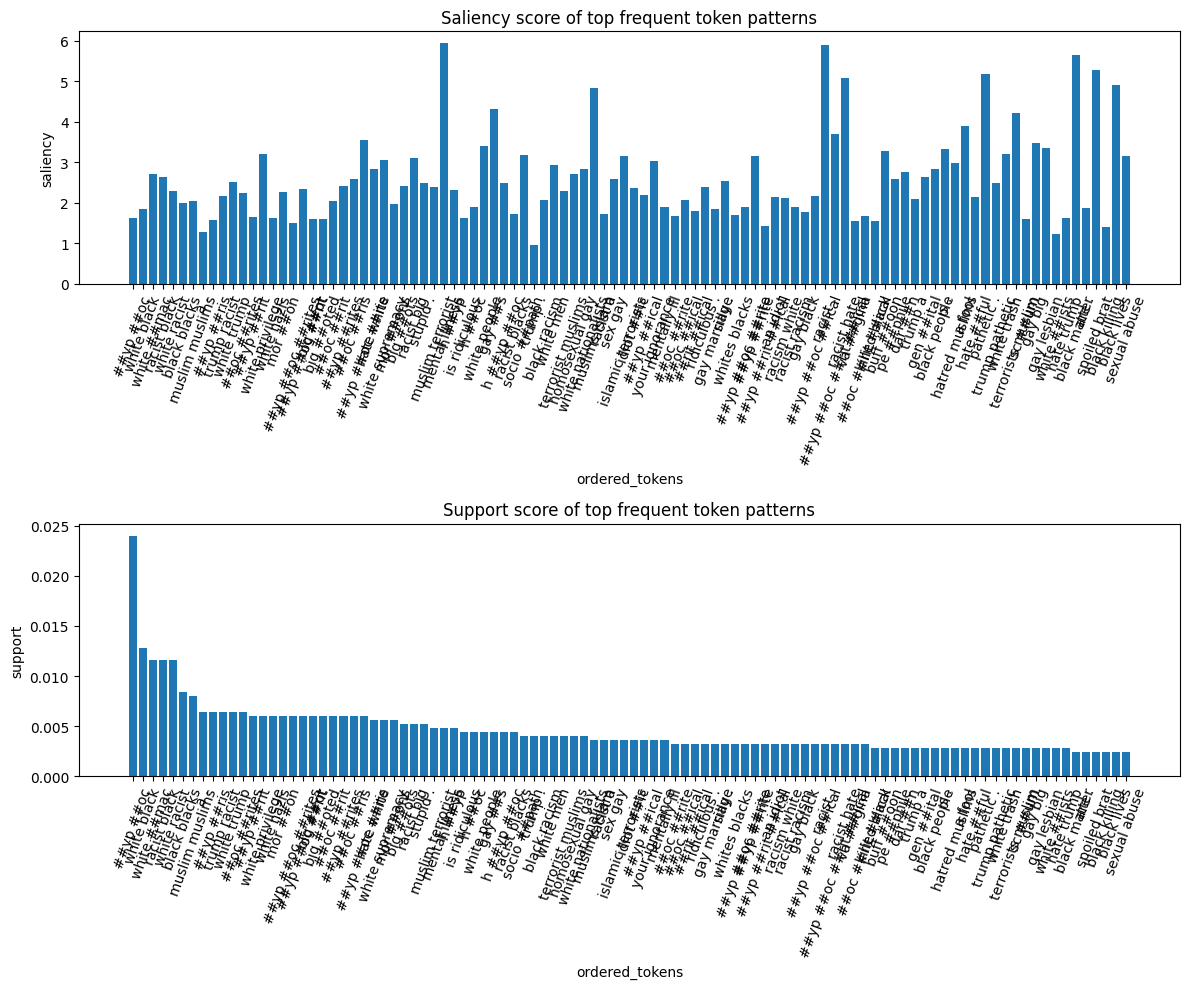

In [45]:
test = two_grams.sort_values("support", ascending=False)
labels_plot = test["ordered_tokens"].apply(lambda x: " ".join(x))

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].bar(labels_plot, two_grams["saliency_score"])
axes[0].set_xlabel("ordered_tokens")
axes[0].set_ylabel("saliency")
axes[0].set_title("Saliency score of top frequent token patterns")
axes[0].tick_params(axis="x", rotation=70)

axes[1].bar(labels_plot, two_grams["support"])
axes[1].set_xlabel("ordered_tokens")
axes[1].set_ylabel("support")
axes[1].set_title("Support score of top frequent token patterns")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

Function to extract hidden states, layer 11 and 12, for high support tokens.

In [46]:
@torch.no_grad()
def extract_itemset_hidden_states(
    model,
    tokenizer,
    itemsets_token_ids, # list of lists, e.g. [[101, 202], [55, 77, 88], ..]
    device,
    layers=(11, 12),
    context_mode="isolated", # "isolated" vs "template"
    template_prefix="This comment is",
    batch_size=32,
    num_labels=2,
):
    """
    Returns:
      out: dict layer_idx -> list[np.ndarray of shape (itemset_len, hidden_dim)]
      logits_out: np.ndarray [n_itemsets, num_labels]
    """

    model.eval()

    cls_id = tokenizer.cls_token_id
    sep_id = tokenizer.sep_token_id
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

    if context_mode == "isolated":
        base_ids = []
        token_start = 1
    elif context_mode == "template":
        base_ids = tokenizer(template_prefix, add_special_tokens=False).input_ids
        token_start = 1 + len(base_ids)
    else:
        raise ValueError("context_mode must be 'isolated' or 'template'")

    out = {L: [] for L in layers}
    logits_out = []

    for start in range(0, len(itemsets_token_ids), batch_size):
        batch_itemsets = itemsets_token_ids[start:start + batch_size]

        input_ids_list = []
        token_ranges = []

        for ids in batch_itemsets:
            ids = [int(t) for t in ids]

            full_ids = [cls_id] + base_ids + ids + [sep_id]
            input_ids_list.append(full_ids)
            # positions of the itemset tokens inside the sequence
            token_ranges.append((token_start, token_start + len(ids)))

        max_len = max(len(x) for x in input_ids_list)

        padded_input_ids = []
        attention_masks = []
        token_type_ids = []

        for ids in input_ids_list:
            pad_len = max_len - len(ids)
            padded_input_ids.append(ids + [pad_id] * pad_len)
            attention_masks.append([1] * len(ids) + [0] * pad_len)
            token_type_ids.append([0] * max_len)

        input_ids = torch.tensor(padded_input_ids, dtype=torch.long, device=device)
        attention_mask = torch.tensor(attention_masks, dtype=torch.long, device=device)
        token_type_ids = torch.tensor(token_type_ids, dtype=torch.long, device=device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=True,
            return_dict=True,
        )

        if hasattr(outputs, "logits"):
            logits_out.append(outputs.logits.detach().cpu().numpy())
        else:
            bsz = input_ids.shape[0]
            logits_out.append(np.full((bsz, num_labels), np.nan, dtype=float))

        hs = outputs.hidden_states

        for b_idx, (s, e) in enumerate(token_ranges):
            for L in layers:
                vecs = hs[L][b_idx, s:e, :].detach().cpu().numpy() # shape: [itemset_len, hidden_dim]
                out[L].append(vecs)

    logits_out = np.vstack(logits_out)
    return out, logits_out

Run Function for isolated tokens and for tokens within a template

In [47]:
layers = (5, 8, 11, 12)
itemset_ids = two_grams["ordered_ids"].tolist()

# Pretrained
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Finetuned
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

Add to dataframe

In [48]:
for L in layers:
    two_grams[f"pt_iso_l{L}"] = list(pt_iso[L])
    two_grams[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    two_grams[f"ft_iso_l{L}"] = list(ft_iso[L])
    two_grams[f"ft_tpl_l{L}"] = list(ft_tpl[L])

Inspect consine/euclidean distance between mean embeddings l12 from pre trained and finetuned bert per itemset

In [49]:
import numpy as np

def pool(x):
    x = np.asarray(x)
    return x.mean(axis=0) if x.ndim == 2 else x

def cos_shift(pt, ft):
    a = pool(pt)
    b = pool(ft)
    cos = np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))
    return 1 - cos

def euc_dist(pt, ft):
    a = pool(pt)
    b = pool(ft)
    return np.linalg.norm(a - b)

layers = (5, 8, 11, 12)

top = two_grams.sort_values("support", ascending=False).head(30).copy()

for L in layers:
    top[f"cos_shift_iso_l{L}"] = [
        cos_shift(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_iso_l{L}"], top[f"ft_iso_l{L}"])
    ]

    top[f"euc_iso_l{L}"] = [
        euc_dist(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_iso_l{L}"], top[f"ft_iso_l{L}"])
    ]

    top[f"cos_shift_tpl_l{L}"] = [
        cos_shift(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_tpl_l{L}"], top[f"ft_tpl_l{L}"])
    ]

    top[f"euc_tpl_l{L}"] = [
        euc_dist(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_tpl_l{L}"], top[f"ft_tpl_l{L}"])
    ]

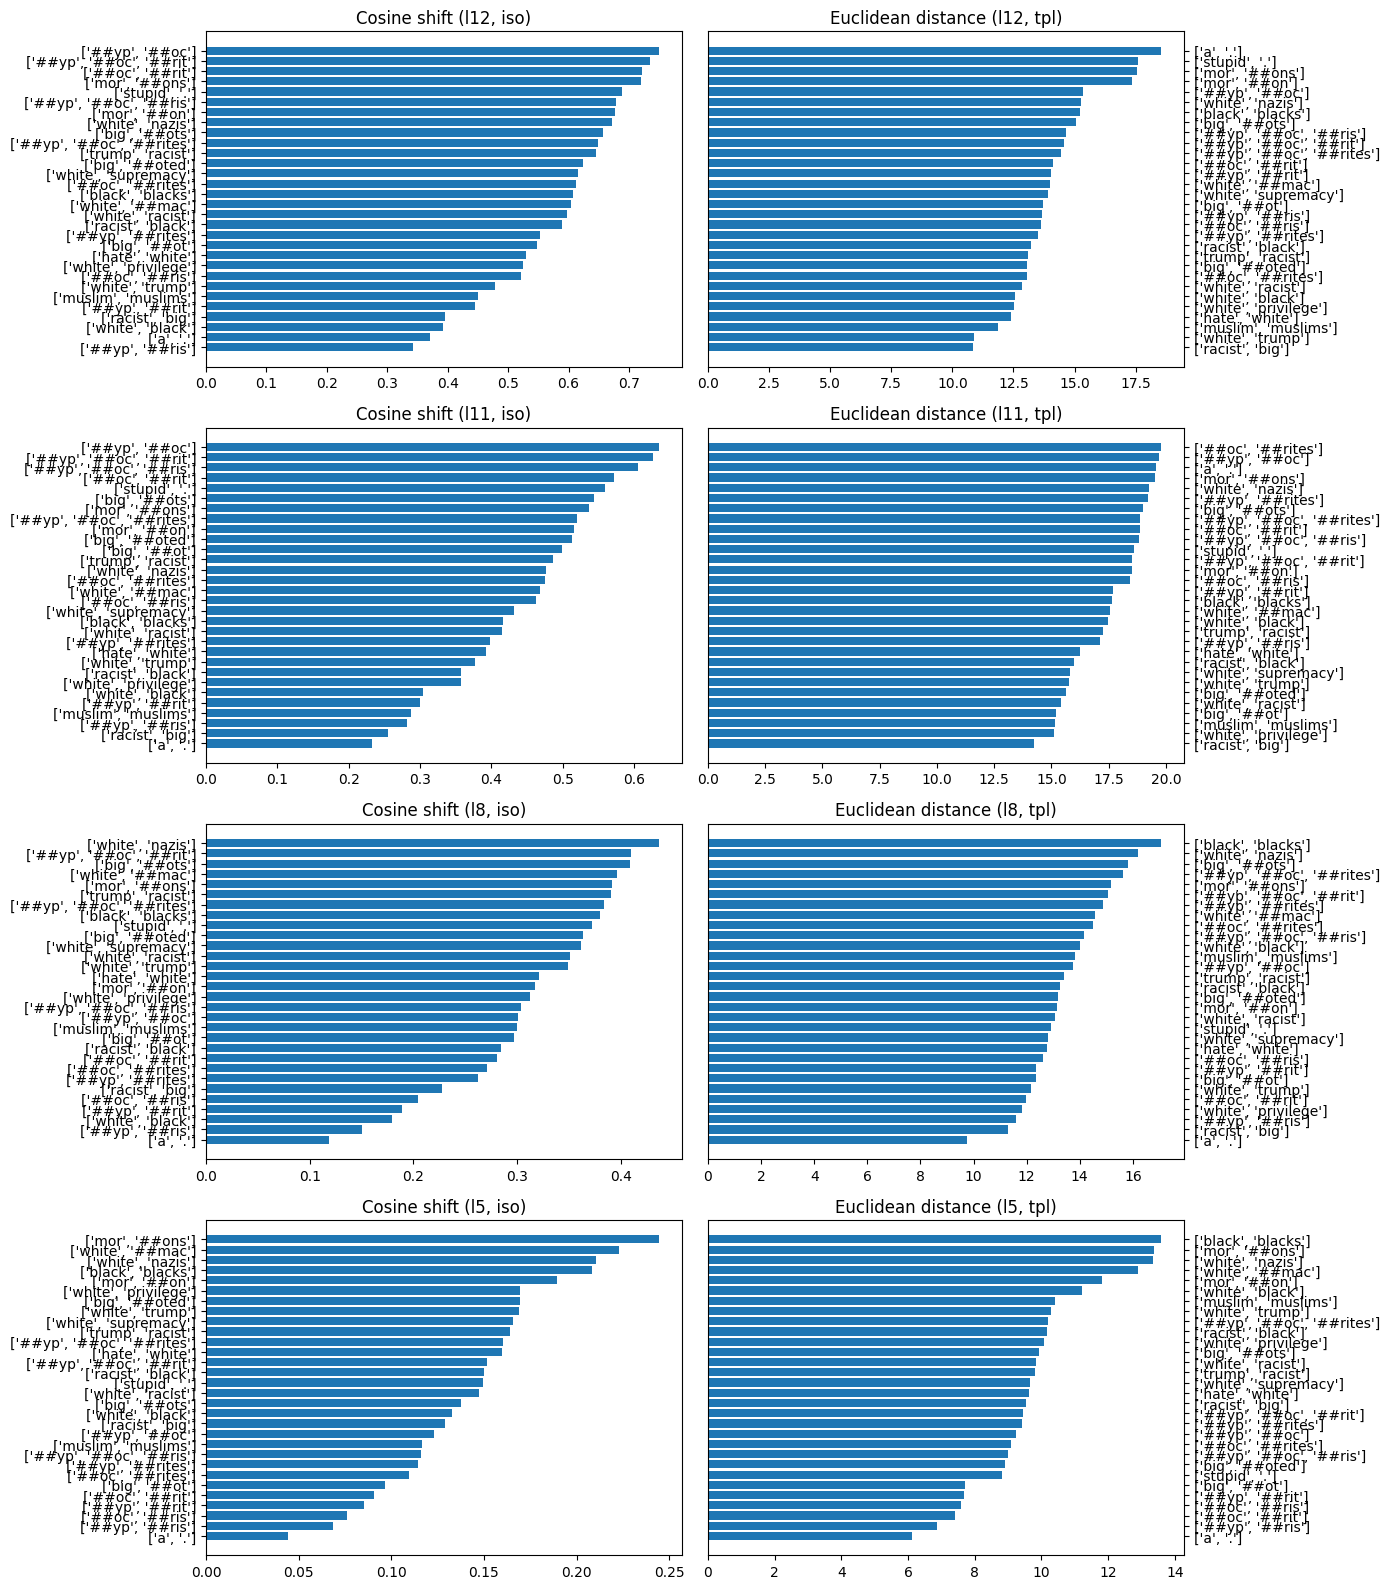

In [50]:
layers = (12,11,8,5)

fig, axes = plt.subplots(len(layers), 2, figsize=(14, 4 * len(layers)))
plt.subplots_adjust(wspace=0.6, hspace=0.4)

for i, L in enumerate(layers):
    # --- Cosine ---
    s1 = top.sort_values(f"cos_shift_iso_l{L}", ascending=False)
    axes[i, 0].barh(range(len(s1)), s1[f"cos_shift_iso_l{L}"])
    axes[i, 0].set_yticks(range(len(s1)))
    axes[i, 0].set_yticklabels(s1.ordered_tokens)
    axes[i, 0].set_title(f"Cosine shift (l{L}, iso)")
    axes[i, 0].invert_yaxis()

    # --- Euclidean ---
    s2 = top.sort_values(f"euc_tpl_l{L}", ascending=False)
    axes[i, 1].barh(range(len(s2)), s2[f"euc_tpl_l{L}"])
    axes[i, 1].set_yticks(range(len(s2)))
    axes[i, 1].set_yticklabels(s2.ordered_tokens)
    axes[i, 1].set_title(f"Euclidean distance (l{L}, tpl)")
    axes[i, 1].invert_yaxis()

    # move right labels outward to avoid overlap
    axes[i, 1].yaxis.tick_right()

plt.tight_layout()

Adding Manual Labels for testing purposoes.

In [51]:
shortcut_labels = [
0,  # ['##yp', '##oc']
1,  # ['racist', 'white']
0,  # ['##yp', '##rite']
0,  # ['idiot', '##ic']
0,  # ['pathetic', '.']
0,  # ['##yp', '##oc', '##rite']
0,  # ['##oc', '##rite']
0,  # ['.', 'stupid']
1,  # ['black', 'white']
0,  # ['mor', '##on']
0,  # ['buff', '##oon']
1,  # ['black', 'racist']
0,  # ['sc', '##um']
0,  # ['an', 'idiot']
0,  # ['idiot', '.']
0,  # ['is', 'stupid']
0,  # ['##yp', '##rites']
0,  # ['##yp', '##oc', '##rites']
0,  # ['##oc', '##rites']
1,  # ['black', 'blacks']
0,  # ['a', 'fool']
0,  # ['mor', '##ons']
0,  # ['idiots', '.']
0,  # ['is', '.']
0,  # ['h', '##yp', '##oc']
0,  # ['h', '##yp']
0,  # ['ridiculous', '.']
0,  # ['h', '##oc']
0,  # ['id', '##io']
0,  # ['is', 'a']
1,  # ['mentally', 'ill']
1,  # ['blacks', 'racist']
0,  # ['a', '.']
1,  # ['white', 'hate']
1,  # ['black', 'gay']
0,  # ['stupid', 'not']
0,  # ['stupid', 'ignorant']
0,  # ['this', 'garbage']
1,  # ['predator', 'sexual']
0,  # ['##oc', '##rit']
0,  # ['is', 'pathetic']
1,  # ['trump', 'a']
0,  # ['id', '##io', '##cy']
0,  # ['##io', '##cy']
0,  # ['##yp', '##oc', '##rit']
1,  # ['trump', '.']
1,  # ['gay', 'sex']
0,  # ['id', '##cy']
0,  # ['##yp', '##rit']
0,  # ['are', 'racist']
0,  # ['##be', '##ci']
1,  # ['trump', 'is']
0,  # ['disgusting', '.']
0,  # ['is', 'ridiculous']
0,  # ['this', '.']
0,  # ['stupid', 'racist']
0,  # ['stupid', 'you']
0,  # ['stupid', 'and']
0,  # ['islamic', 'terrorists']
0,  # ['dumb', '.']
0,  # ['a', 'liar']
1,  # ['white', 'trump']
1,  # ['trump', 'racist']
0,  # ['are', 'stupid']
0,  # ['stupid', '"']
1,  # ['va', '##gina']
0,  # ['dar', '##n']
0,  # ['pe', '##phile']
1,  # ['racist', 'hate']
1,  # ['whites', 'blacks']
1,  # ['black', 'people']
1,  # ['mental', 'illness']
1,  # ['muslims', 'terrorists']
1,  # ['buff', 'trump']
1,  # ['##oon', 'trump']
1,  # ['buff', '##oon', 'trump']
0,  # ['im', '##be']
0,  # ['im', '##be', '##ci']
0,  # ['muslim', 'terrorist']
0,  # ['im', '##ci']
0,  # ['this', 'crap']
1,  # ['muslims', 'stupid']
0,  # ['socio', '##path']
1,  # ['trump', 'stupid']
0,  # ['the', 'idiot']
0,  # ['are', '.']
0,  # ['stupidity', '.']
0,  # [',', 'stupid']
0,  # ['that', '.']
1,  # ['white', 'privilege']
0,  # ['stupid', 'idiot']
0,  # ['how', 'stupid']
0,  # ['an', '.']
0,  # ['a', '##on']
0,  # ['a', 'mor', '##on']
0,  # ['s', '.']
0,  # ['a', 'loser']
0,  # ['this', 'clown']
0,  # ['these', 'idiots']
0   # ['h', '##rite']
]

two_grams["shortcuts"] = shortcut_labels
two_grams

,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,pt_iso_l5,pt_tpl_l5,ft_iso_l5,...,ft_tpl_l8,pt_iso_l11,pt_tpl_l11,ft_iso_l11,ft_tpl_l11,pt_iso_l12,pt_tpl_l12,ft_iso_l12,ft_tpl_l12,shortcuts
538,0.0240,"(22571, 10085)",2,"[22571, 10085]","[##yp, ##oc]",1.618177,0.038836,"[[-0.7135446, 1.7651055, 0.36015412, 0.4686972...","[[-1.1975796, 1.406815, 0.6856058, 0.76791346,...","[[-0.87421197, 2.0502448, 0.34640327, 0.891568...",...,"[[-0.5848685, 0.81979454, 0.7263041, 0.4060461...","[[-0.23516098, 1.0450013, -0.019490913, 0.4359...","[[-0.36528298, 1.2620711, 0.57213295, 0.507592...","[[-0.12968098, 1.2109303, -1.2505602, 0.599612...","[[-0.37915292, 1.8645113, -0.8992446, -0.24978...","[[-0.101825796, 0.9928762, 0.224233, 0.4367425...","[[-0.1944664, 0.79339844, 0.30043584, 0.543171...","[[0.2281303, 1.0102988, -1.0372367, 0.1342952,...","[[-0.042705413, 0.95613366, -1.011834, -0.2111...",0
514,0.0128,"(2304, 2317)",2,"[2317, 2304]","[white, black]",1.834562,0.023482,"[[0.41291532, -0.16188681, 0.1373424, -1.78342...","[[0.090869635, -0.0049935505, 0.5168027, -1.58...","[[0.4820899, -0.65325475, -0.14758432, -1.0448...",...,"[[-0.28948915, 0.44939792, -0.41823974, -0.751...","[[0.103235655, -0.05247239, -0.5746884, -0.896...","[[0.43393257, -0.016312338, 0.030499749, -0.79...","[[0.36423048, 0.10899486, -1.1133856, -0.85700...","[[-0.0653272, 1.342025, -0.7098172, -1.0359414...","[[0.21003683, -0.17698213, -0.8779583, -0.7031...","[[0.26600626, 0.0020805784, -0.13810259, -0.42...","[[0.31832027, -0.28157607, -0.9050058, -0.2365...","[[0.056722865, 0.7135851, -1.006454, -0.053518...",1
578,0.0116,"(2317, 22911)",2,"[2317, 22911]","[white, ##mac]",2.715769,0.031503,"[[0.13685443, -1.10937, 0.1535937, -0.39105198...","[[0.3802377, -1.4770167, 0.18513995, -0.512161...","[[0.21855707, -1.752456, 0.6438752, -0.1529982...",...,"[[-0.4957897, -1.603784, 0.33065355, -0.52884,...","[[0.27487633, -0.2505673, -0.5537396, -0.52980...","[[0.5204126, -0.8246438, 0.09121399, -0.609599...","[[-0.22569613, -0.45327267, -0.52430785, -0.10...","[[-0.6637418, -0.62567765, -0.3767773, -0.3240...","[[0.17004785, 0.23925269, -0.5455345, -0.46279...","[[0.38660476, -0.3263345, 0.03602201, -0.22471...","[[-0.5226412, -0.021961944, -0.5805689, 0.1452...","[[-0.37722027, -0.47623295, -0.43409556, -0.18...",0
540,0.0116,"(16939, 2317)",2,"[2317, 16939]","[white, racist]",2.624524,0.030444,"[[-0.21273328, -0.28056914, 0.40171087, -0.931...","[[0.078852475, -0.46459687, 0.7189964, -0.8909...","[[-0.05754917, -0.28139484, 0.5813081, -0.8026...",...,"[[-0.36337098, -0.1582118, -0.3373147, -0.8533...","[[0.047584157, -0.2956706, -0.72589076, -0.611...","[[0.13167001, -0.29785177, -0.10933149, -0.754...","[[0.2280459, 1.7401915, -0.42722124, -0.332868...","[[-0.17584953, 2.018778, -0.32209414, -0.65841...","[[-0.16415177, 0.097273566, -0.90965956, -0.37...","[[0.05658955, 0.010050982, -0.26281434, -0.531...","[[-0.21905248, 0.9080763, -1.1750698, -0.23408...","[[-0.12724109, 0.91699016, -0.94198644, -0.343...",0
539,0.0116,"(2304, 16939)",2,"[16939, 2304]","[racist, black]",2.294029,0.026611,"[[0.330659, 0.9050353, 0.06861343, -0.59676665...","[[0.65053797, 0.45553476, 0.05942343, -0.77461...","[[0.2572796, 0.95710826, -0.25549728, -0.82329...",...,"[[-0.064482905, 0.50202644, -0.452598, -0.5681...","[[0.40350127, 0.35103634, -1.0559407, -0.65169...","[[0.66544086, 0.39445725, -0.3758831, -0.86834...","[[0.3919713, 1.3903917, -0.74359155, -0.410671...","[[0.41061598, 1.7630295, -0.5407894, -0.735733...","[[-0.0076207058, 0.35072893, -0.625372, -0.328...","[[0.43026224, 0.29358092, -0.13192654, -0.5644...","[[-0.23453511, 0.63836664, -1.2961061, -0.2848...","[[-0.020776797, 0.8314787, -1.1042947, -0.3538...",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
625,0.0024,"(2024, 1012)",2,"[2024, 1012]","[are, .]",1.879157,0.004510,"[[0.19546944, -1.0783739, 0.7488313, -1.747540...","[[0.73412293, -1.30182

In [52]:
def ids_to_string(x):
    if isinstance(x, (list, tuple)):
        return " | ".join(map(str, x))
    return str(x)


def row_to_single_vector(x, reduce_mode="mean"):
    arr = np.asarray(x, dtype=float)

    # already one embedding vector
    if arr.ndim == 1:
        return arr

    # multiple token embeddings in one row -> aggregate to one row vector
    if arr.ndim == 2:
        if reduce_mode == "mean":
            return arr.mean(axis=0)
        elif reduce_mode == "sum":
            return arr.sum(axis=0)
        else:
            raise ValueError("reduce_mode must be 'mean' or 'sum'")

    raise ValueError(f"Unexpected embedding shape: {arr.shape}")


def plot_3d_pca_pt_ft_shortcut(
    df,
    pt_col,
    ft_col,
    ordered_tokens_col="ordered_tokens",
    shortcut_col="shortcut",
    reduce_mode="mean",   # or sum
    title=None,
    annotate_ids=False,
    annotate_top_n=None,
):
    """Plot a 3D PCA comparison of pretrained and finetuned embeddings, grouped by shortcut label."""
    work_df = df[[pt_col, ft_col, ordered_tokens_col, shortcut_col]].copy().reset_index(drop=True)

    # make sure each row becomes exactly one vector
    work_df["pt_vec"] = work_df[pt_col].apply(lambda x: row_to_single_vector(x, reduce_mode=reduce_mode))
    work_df["ft_vec"] = work_df[ft_col].apply(lambda x: row_to_single_vector(x, reduce_mode=reduce_mode))

    vecs_pt = np.vstack(work_df["pt_vec"].to_numpy())
    vecs_ft = np.vstack(work_df["ft_vec"].to_numpy())

    combined = np.vstack([vecs_pt, vecs_ft])

    pca = PCA(n_components=3)
    coords = pca.fit_transform(combined)

    n = len(work_df)

    plot_df = pd.DataFrame({
        "PC1": coords[:, 0],
        "PC2": coords[:, 1],
        "PC3": coords[:, 2],
        "embedding_type": ["PT"] * n + ["FT"] * n,
        "shortcut": work_df[shortcut_col].tolist() + work_df[shortcut_col].tolist(),
        "ordered_tokens": work_df[ordered_tokens_col].apply(ids_to_string).tolist()
                           + work_df[ordered_tokens_col].apply(ids_to_string).tolist(),
    })

    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    for emb_type, marker in [("PT", "o"), ("FT", "^")]:
        for shortcut_value in sorted(plot_df["shortcut"].dropna().unique()):
            subset = plot_df[
                (plot_df["embedding_type"] == emb_type) &
                (plot_df["shortcut"] == shortcut_value)
            ]
            ax.scatter(
                subset["PC1"],
                subset["PC2"],
                subset["PC3"],
                marker=marker,
                alpha=0.75,
                label=f"{emb_type}, shortcut={shortcut_value}",
            )

    if annotate_ids:
        ann_df = plot_df if annotate_top_n is None else plot_df.head(annotate_top_n)
        for _, row in ann_df.iterrows():
            ax.text(row["PC1"], row["PC2"], row["PC3"], row["ordered_tokens"], fontsize=8)

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(title or f"3D PCA: {pt_col} vs {ft_col} ({reduce_mode})")
    ax.legend()
    plt.tight_layout()
    plt.show()

    return plot_df, pca

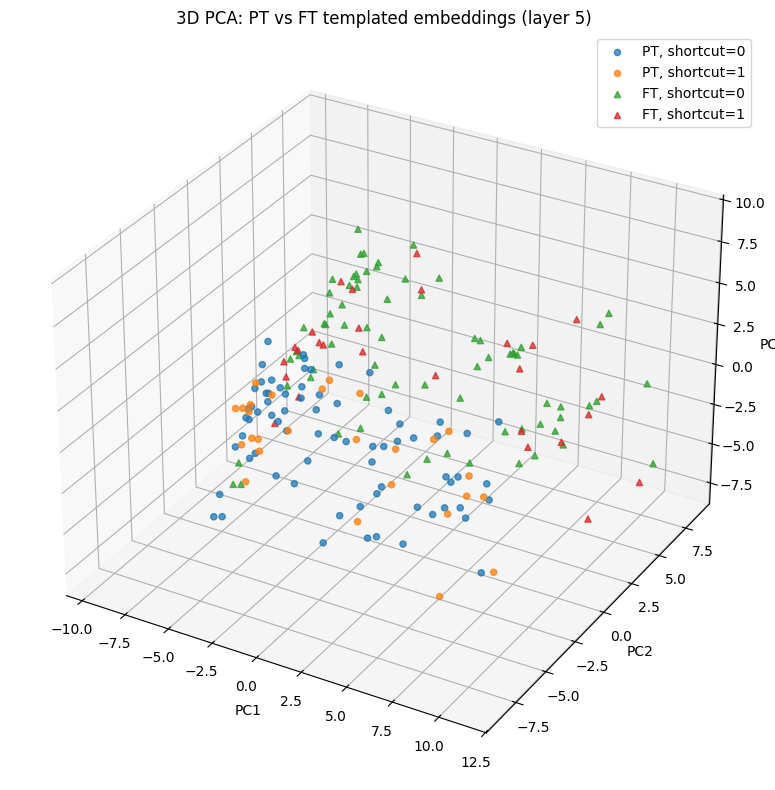

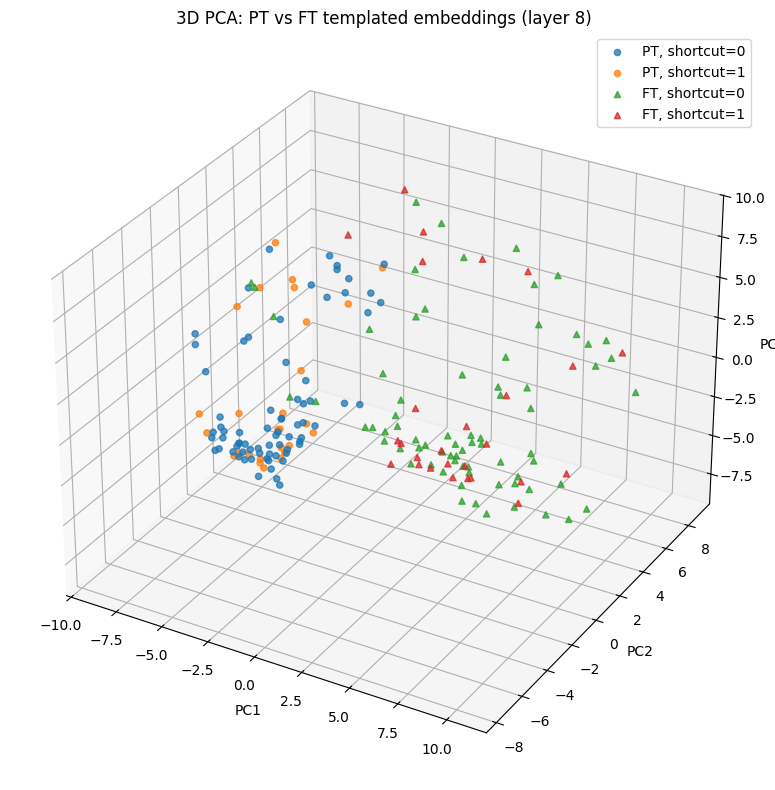

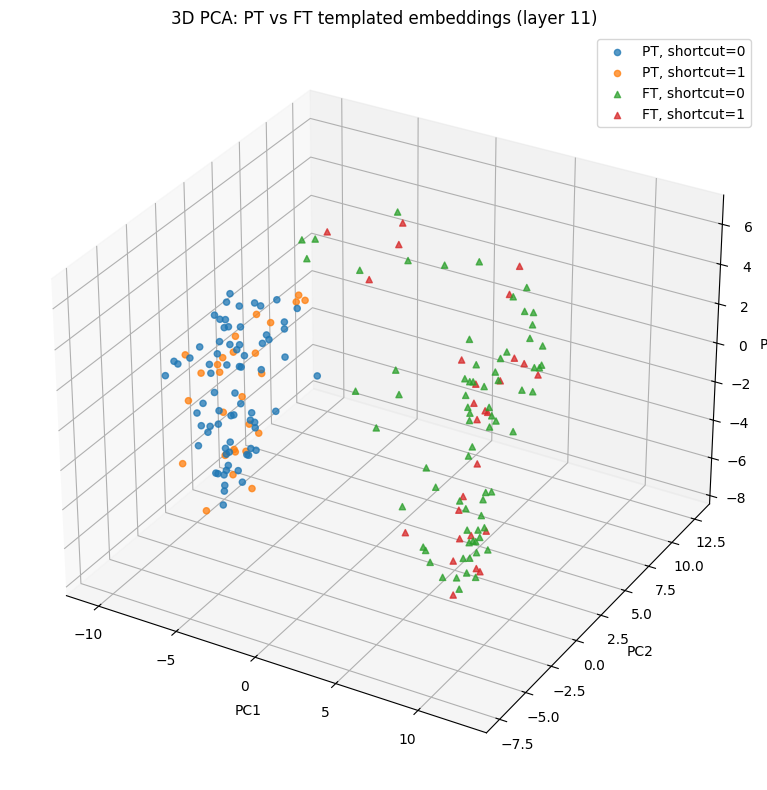

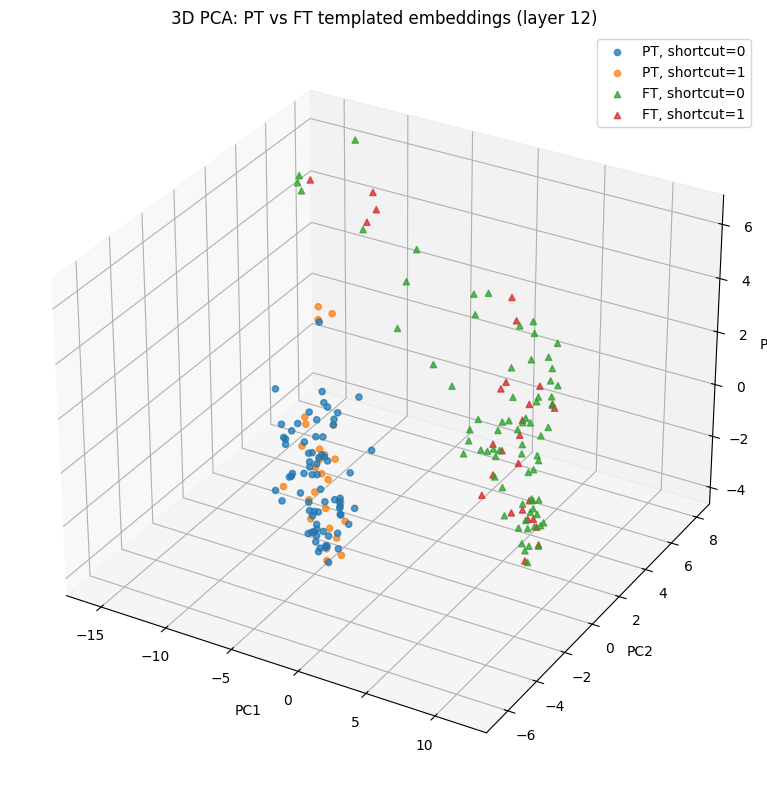

In [53]:
layers = (5, 8, 11, 12)

for L in layers:
    plot_df, pca_model = plot_3d_pca_pt_ft_shortcut(
        df=two_grams.head(100),
        pt_col=f"pt_tpl_l{L}",
        ft_col=f"ft_tpl_l{L}",
        ordered_tokens_col="ordered_tokens",
        shortcut_col="shortcuts",
        title=f"3D PCA: PT vs FT templated embeddings (layer {L})",
        annotate_ids=False,
    )

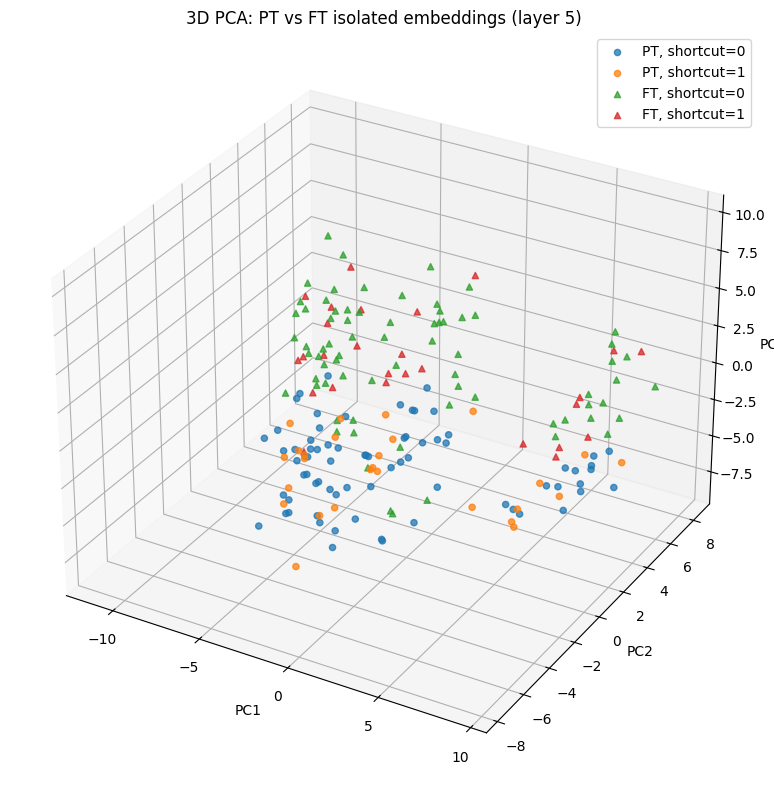

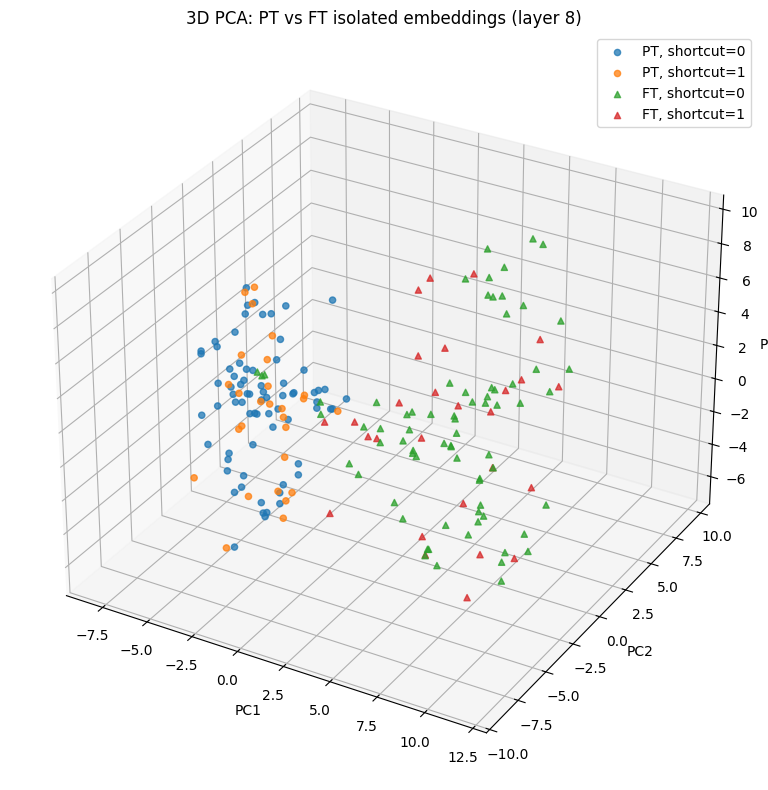

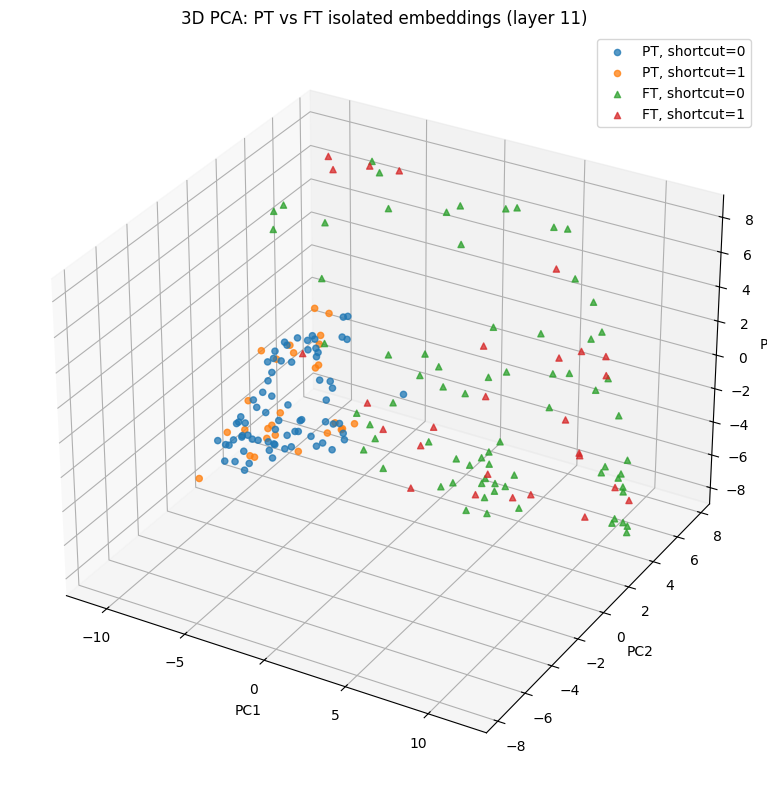

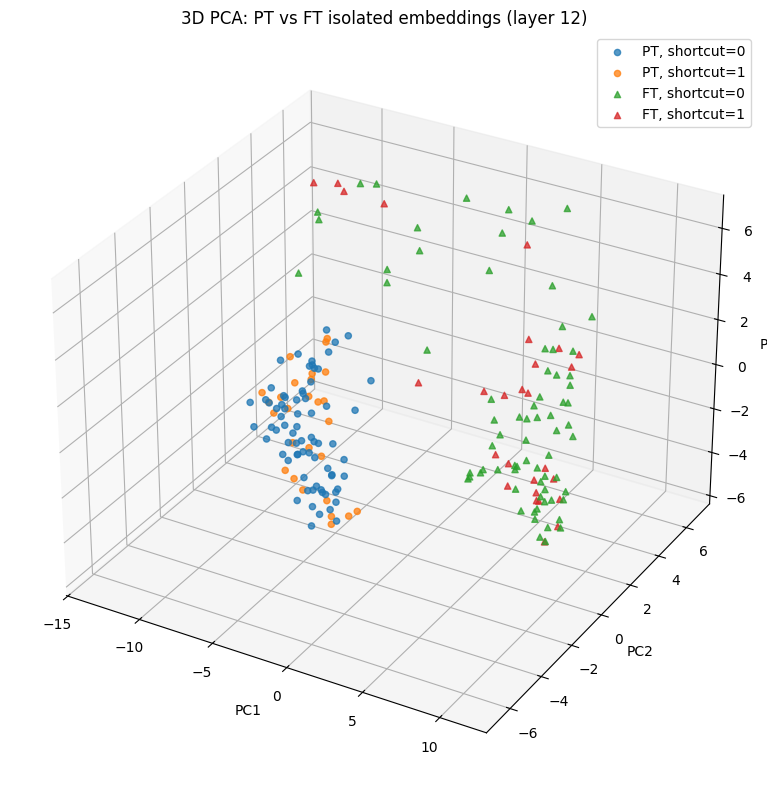

In [54]:
layers = (5, 8, 11, 12)

for L in layers:
    plot_df, pca_model = plot_3d_pca_pt_ft_shortcut(
        df=two_grams.head(100),
        pt_col=f"pt_iso_l{L}",
        ft_col=f"ft_iso_l{L}",
        ordered_tokens_col="ordered_tokens",
        shortcut_col="shortcuts",
        title=f"3D PCA: PT vs FT isolated embeddings (layer {L})",
        annotate_ids=False,
    )

## Experiment 2: Inspecting Hidden States: Layer 5,8,11 and 12

- Using freq_itemset with all tokens since we want a larger pool of tokens for neighbourhood analysis

In [55]:
neighbour_analysis_df = freq_itemsets_toxic_10[freq_itemsets_toxic_10["length"] > 0].sort_values("score", ascending=False)

In [56]:
freq_itemsets_toxic_10[freq_itemsets_toxic_10["length"] > 1].sort_values("score", ascending=False)

,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score
1299,0.0260,"(16939, 2317)",2,"[2317, 16939]","[white, racist]",1.916923,0.049840
1211,0.0288,"(1012, 8398)",2,"[8398, 1012]","[trump, .]",1.722900,0.049620
1238,0.0300,"(22571, 10085)",2,"[22571, 10085]","[##yp, ##oc]",1.454783,0.043643
1544,0.0208,"(2317, 22911)",2,"[2317, 22911]","[white, ##mac]",2.003593,0.041675
1448,0.0320,"(1012, 1037)",2,"[1012, 1037]","[., a]",1.301526,0.041649
...,...,...,...,...,...,...,...
1756,0.0020,"(1012, 2061)",2,"[2061, 1012]","[so, .]",0.702805,0.001406
1473,0.0020,"(1029, 999)",2,"[999, 1029]","[!, ?]",0.698879,0.001398
1197,0.0020,"(10041, 2023)",2,"[2023, 10041]","[this, idiot]",0.672690,0.001345
1178,0.0020,"(4995, 1012)",2,"[1012, 4995]","[., aren]",0.625837,0.001252


In [57]:
layers = (5, 8, 11, 12)
itemset_ids = neighbour_analysis_df["ordered_ids"].tolist()

# Pretrained
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Finetuned
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Assign pretrained
neighbour_analysis_df["pt_iso_l5"]  = list(pt_iso[5])
neighbour_analysis_df["pt_iso_l8"]  = list(pt_iso[8])
neighbour_analysis_df["pt_iso_l11"] = list(pt_iso[11])
neighbour_analysis_df["pt_iso_l12"] = list(pt_iso[12])

neighbour_analysis_df["pt_tpl_l5"]  = list(pt_tpl[5])
neighbour_analysis_df["pt_tpl_l8"]  = list(pt_tpl[8])
neighbour_analysis_df["pt_tpl_l11"] = list(pt_tpl[11])
neighbour_analysis_df["pt_tpl_l12"] = list(pt_tpl[12])

# Assign finetuned
neighbour_analysis_df["ft_iso_l5"]  = list(ft_iso[5])
neighbour_analysis_df["ft_iso_l8"]  = list(ft_iso[8])
neighbour_analysis_df["ft_iso_l11"] = list(ft_iso[11])
neighbour_analysis_df["ft_iso_l12"] = list(ft_iso[12])

neighbour_analysis_df["ft_tpl_l5"]  = list(ft_tpl[5])
neighbour_analysis_df["ft_tpl_l8"]  = list(ft_tpl[8])
neighbour_analysis_df["ft_tpl_l11"] = list(ft_tpl[11])
neighbour_analysis_df["ft_tpl_l12"] = list(ft_tpl[12])

# logits
neighbour_analysis_df["ft_iso_logits"] = list(ft_logits_iso)
neighbour_analysis_df["ft_tpl_logits"] = list(ft_logits_tpl)

In [58]:
neighbour_analysis_df.columns

Index(['support', 'itemsets', 'length', 'ordered_ids', 'ordered_tokens',
       'saliency_score', 'score', 'pt_iso_l5', 'pt_iso_l8', 'pt_iso_l11',
       'pt_iso_l12', 'pt_tpl_l5', 'pt_tpl_l8', 'pt_tpl_l11', 'pt_tpl_l12',
       'ft_iso_l5', 'ft_iso_l8', 'ft_iso_l11', 'ft_iso_l12', 'ft_tpl_l5',
       'ft_tpl_l8', 'ft_tpl_l11', 'ft_tpl_l12', 'ft_iso_logits',
       'ft_tpl_logits'],
      dtype='object')

Building three dfs for nieghbourhood analysis of embeddings of itemsets:
- Inspecting mean of all tokens from one itemset
- Inspecting just the first embedding of an itemset
- Inspecting the sum of all tokens within an itemset

This code builds a pipeline to visualize embedding differences between  PT and FT BERT using 3-D PCA. 
- It starts from the original neighbour_analysis_df, dynamically aggregates token-level embeddings into a single vector per itemset using one of three selectable strategies (mean, first_token, or sum)
- For a chosen pair of embedding columns (e.g., pt_tpl_l12 vs ft_tpl_l12 or pt_iso_l12 vs ft_iso_l12), it stacks the vectors from both embeddings, runs PCA to reduce them to three dimensions, and plots the results in a 3D scatter plot where each point represents an itemset embedding and colors distinguish the embedding type (pretrained vs finetuned)
- The result allows visual comparison of how itemset representations shift between pretrained and finetuned models under different embedding aggregation strategies.

In [59]:
layers = (5, 8, 11, 12)
types = ("pt", "ft")
contexts = ("iso", "tpl")

EMBEDDING_COLS = [
    f"{t}_{ctx}_l{L}"
    for t in types
    for ctx in contexts
    for L in layers
]

BASE_COLS = ["support", "length", "ordered_ids", "ordered_tokens", "saliency_score"]


def emb_mean(x):
    arr = np.asarray(x)
    return arr.mean(axis=0)


def emb_first(x):
    arr = np.asarray(x)
    return arr[0]


def emb_sum(x):
    arr = np.asarray(x)
    return arr.sum(axis=0)


def get_aggregation_function(mode):
    if mode == "mean":
        return emb_mean
    if mode == "first_token":
        return emb_first
    if mode == "sum":
        return emb_sum
    raise ValueError("mode must be one of: 'mean', 'first_token', 'sum'")


def build_embedding_view(source_df, mode):
    agg_func = get_aggregation_function(mode)

    base_df = source_df[BASE_COLS + EMBEDDING_COLS].copy()
    out_df = base_df[BASE_COLS].copy()

    for col in EMBEDDING_COLS:
        out_df[col] = base_df[col].apply(agg_func)

    out_df = out_df.reset_index(drop=True)
    return out_df


def tokens_to_string(tokens):
    if isinstance(tokens, (list, tuple)):
        return " | ".join(tokens)
    return str(tokens)


def build_pca_input(df, col_a, col_b):
    vecs_a = np.vstack(df[col_a].to_numpy())
    vecs_b = np.vstack(df[col_b].to_numpy())

    combined = np.vstack([vecs_a, vecs_b])

    labels = [col_a] * len(vecs_a) + [col_b] * len(vecs_b)
    itemsets = list(df["ordered_tokens"].apply(tokens_to_string)) * 2
    lengths = list(df["length"]) * 2
    supports = list(df["support"]) * 2

    return combined, labels, itemsets, lengths, supports


def plot_3d_pca_pair(source_df, mode, col_a, col_b, title):
    work_df = build_embedding_view(source_df, mode)

    combined, labels, itemsets, lengths, supports = build_pca_input(
        work_df, col_a, col_b
    )

    pca = PCA(n_components=3)
    coords = pca.fit_transform(combined)

    plot_df = pd.DataFrame({
        "PC1": coords[:, 0],
        "PC2": coords[:, 1],
        "PC3": coords[:, 2],
        "embedding_type": labels,
        "ordered_tokens_str": itemsets,
        "length": lengths,
        "support": supports,
    })

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    mask_a = plot_df["embedding_type"] == col_a
    mask_b = plot_df["embedding_type"] == col_b

    ax.scatter(
        plot_df.loc[mask_a, "PC1"],
        plot_df.loc[mask_a, "PC2"],
        plot_df.loc[mask_a, "PC3"],
        label=col_a,
        alpha=0.7
    )

    ax.scatter(
        plot_df.loc[mask_b, "PC1"],
        plot_df.loc[mask_b, "PC2"],
        plot_df.loc[mask_b, "PC3"],
        label=col_b,
        alpha=0.7
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(f"{title} ({mode})")
    ax.legend()

    plt.tight_layout()
    plt.show()

    return plot_df

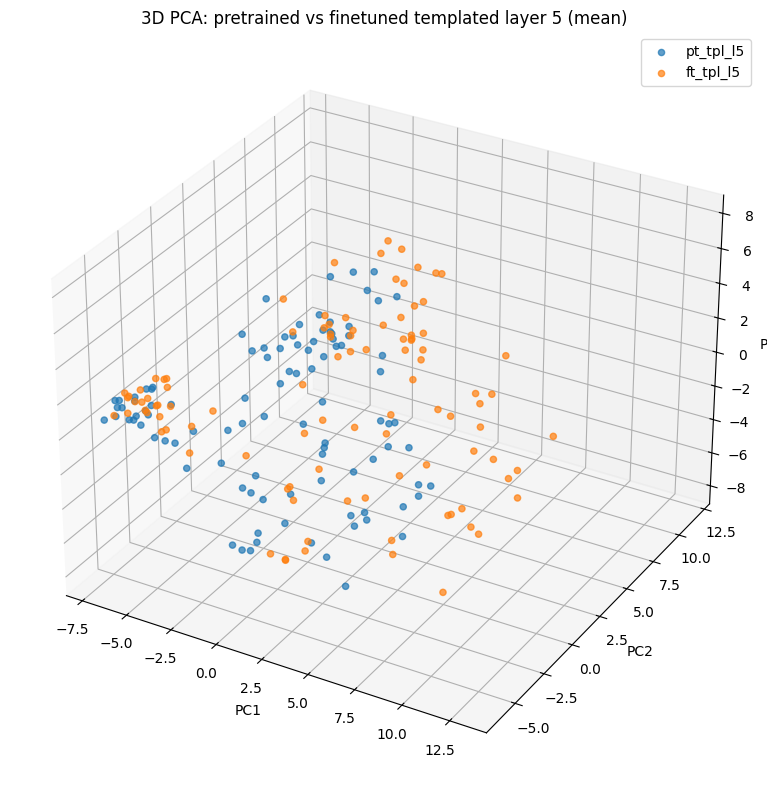

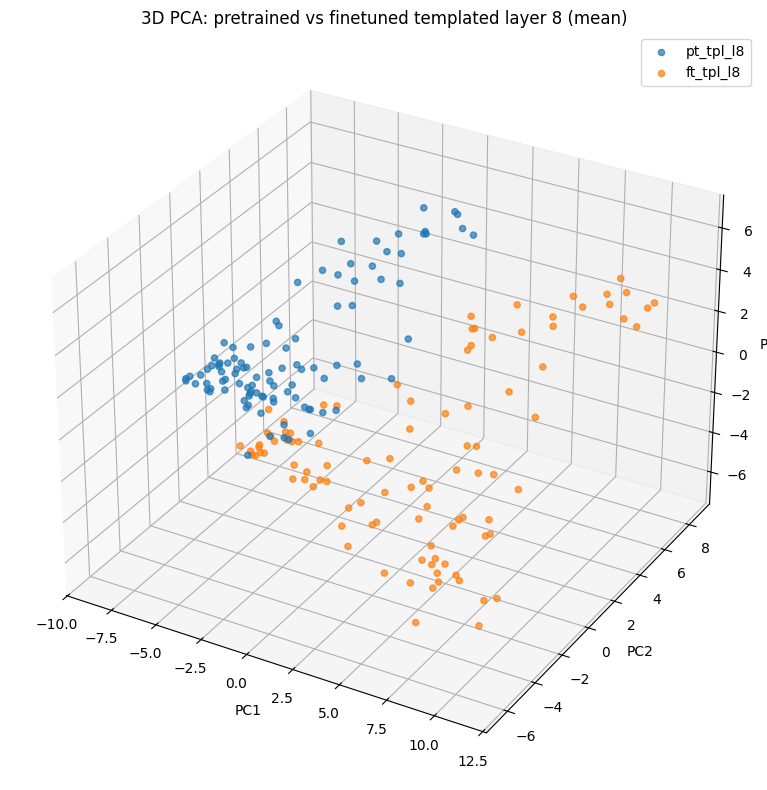

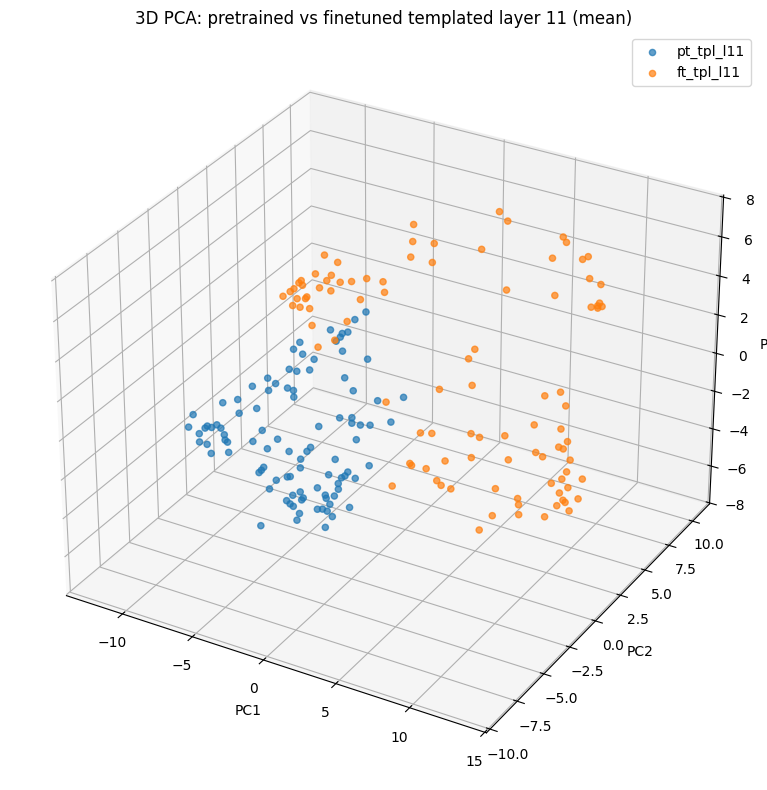

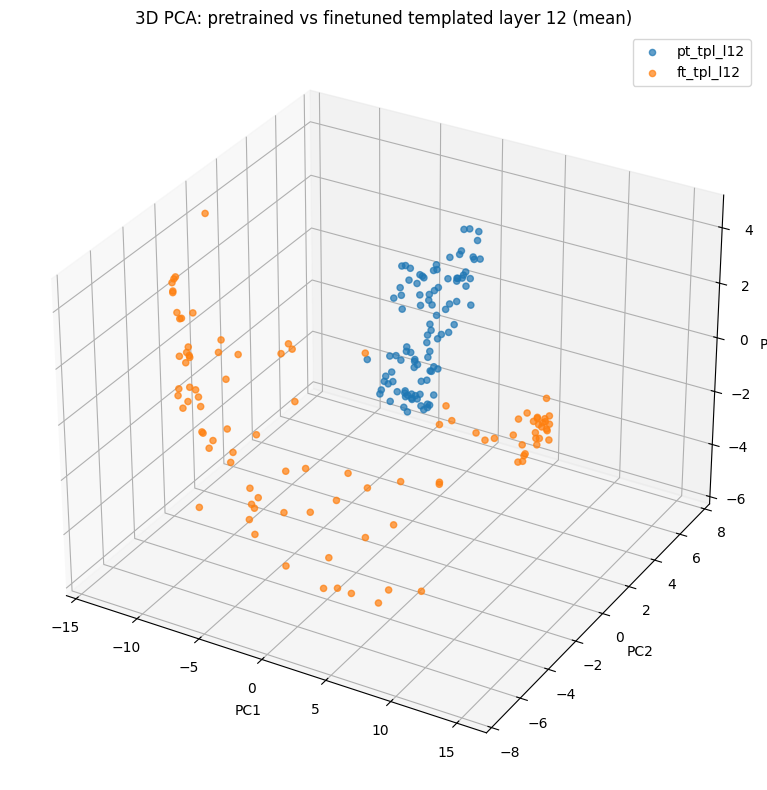

In [60]:
plot_df_tpl_mean_l5 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(100),
    mode="mean",
    col_a="pt_tpl_l5",
    col_b="ft_tpl_l5",
    title="3D PCA: pretrained vs finetuned templated layer 5"
)

plot_df_tpl_mean_l8 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(100),
    mode="mean",
    col_a="pt_tpl_l8",
    col_b="ft_tpl_l8",
    title="3D PCA: pretrained vs finetuned templated layer 8"
)

plot_df_tpl_mean_l11 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(100),
    mode="mean",
    col_a="pt_tpl_l11",
    col_b="ft_tpl_l11",
    title="3D PCA: pretrained vs finetuned templated layer 11"
)

plot_df_tpl_mean_l12 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(100),
    mode="mean",
    col_a="pt_tpl_l12",
    col_b="ft_tpl_l12",
    title="3D PCA: pretrained vs finetuned templated layer 12"
)

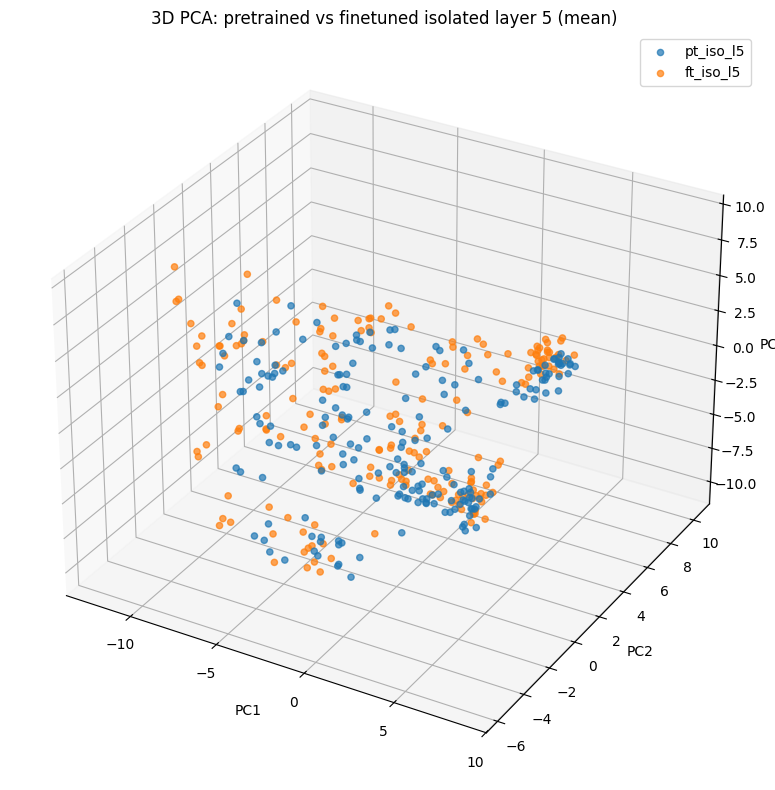

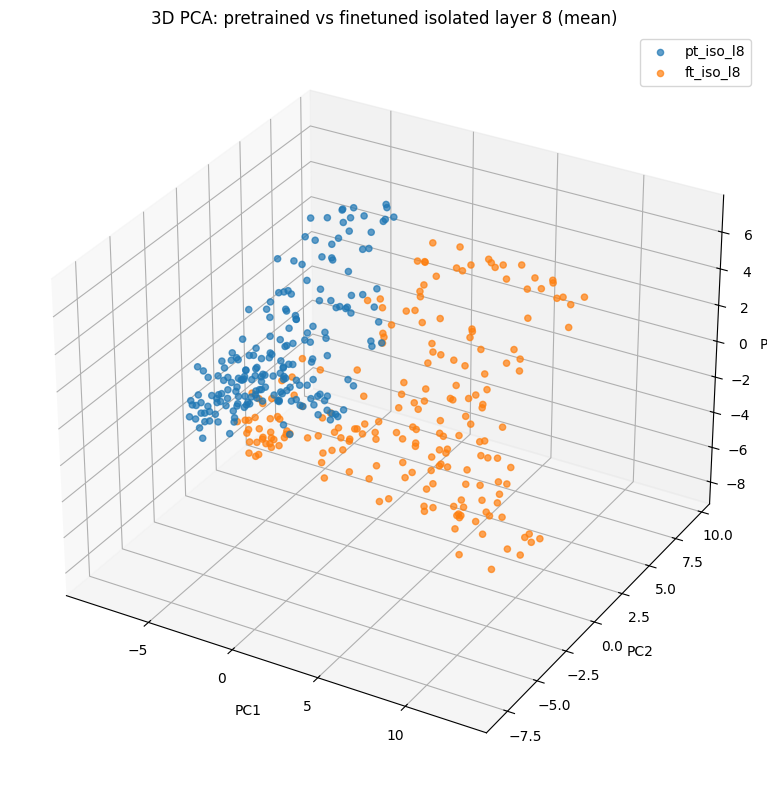

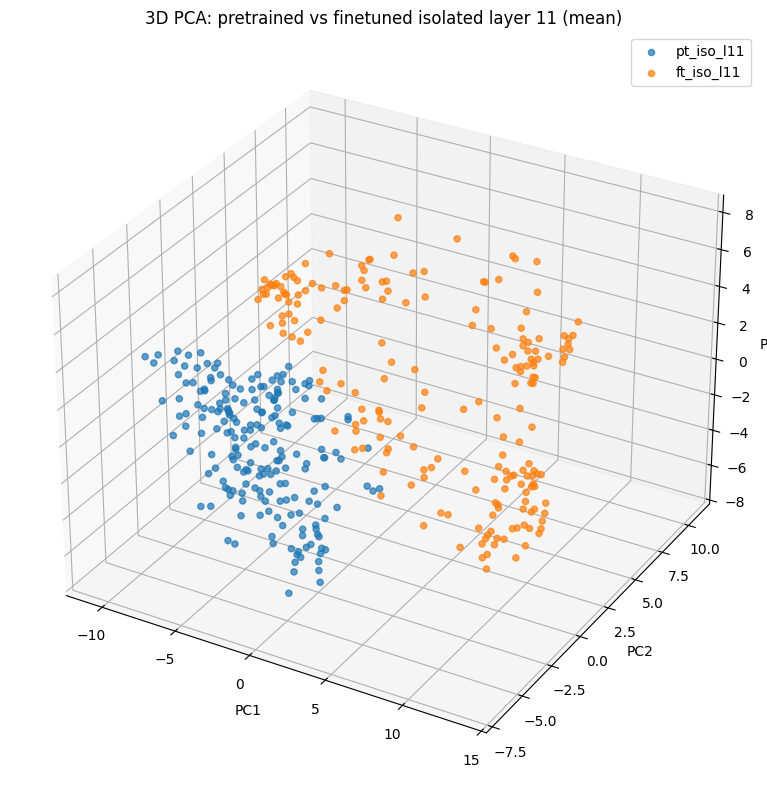

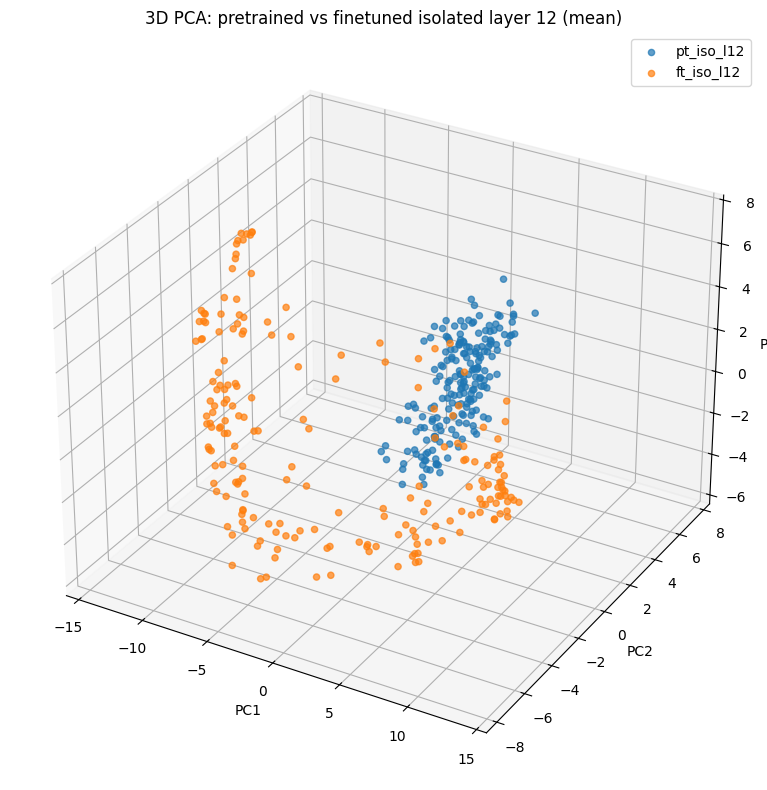

In [61]:
plot_df_iso_mean_l5 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(200),
    mode="mean",
    col_a="pt_iso_l5",
    col_b="ft_iso_l5",
    title="3D PCA: pretrained vs finetuned isolated layer 5"
)

plot_df_iso_mean_l8 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(200),
    mode="mean",
    col_a="pt_iso_l8",
    col_b="ft_iso_l8",
    title="3D PCA: pretrained vs finetuned isolated layer 8"
)

plot_df_iso_mean_l11 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(200),
    mode="mean",
    col_a="pt_iso_l11",
    col_b="ft_iso_l11",
    title="3D PCA: pretrained vs finetuned isolated layer 11"
)

plot_df_iso_mean_l12 = plot_3d_pca_pair(
    source_df=neighbour_analysis_df[neighbour_analysis_df["length"] > 1].sort_values("support", ascending=False).head(200),
    mode="mean",
    col_a="pt_iso_l12",
    col_b="ft_iso_l12",
    title="3D PCA: pretrained vs finetuned isolated layer 12"
)

## Experiment 3: Neighbourhood analysis

Aggregating Embeddings

In [62]:
# embedding columns you want to transform
layers = (5, 8, 11, 12)
types = ("pt", "ft")
contexts = ("iso", "tpl")

embedding_cols = [
    f"{type}_{context}_l{layer}"
    for type in types
    for context in contexts
    for layer in layers
]

# base dataframe
base_cols = ["support", "length", "ordered_ids", "ordered_tokens", "saliency_score"]

base_df = neighbour_analysis_df[base_cols + embedding_cols].copy()

def emb_mean(x):
    return np.asarray(x).mean(axis=0)

def emb_first(x):
    return np.asarray(x)[0]

def emb_sum(x):
    return np.asarray(x).sum(axis=0)

# build the 3 result dataframes
df_mean = base_df[base_cols].copy()
df_first_token = base_df[base_cols].copy()
df_sum = base_df[base_cols].copy()

for col in embedding_cols:
    df_mean[col] = base_df[col].apply(emb_mean)
    df_first_token[col] = base_df[col].apply(emb_first)
    df_sum[col] = base_df[col].apply(emb_sum)

# reset index
df_mean = df_mean.reset_index(drop=True)
df_first_token = df_first_token.reset_index(drop=True)
df_sum = df_sum.reset_index(drop=True)

print(df_mean.shape, df_first_token.shape, df_sum.shape)
display(df_mean.head(2))
display(df_first_token.head(2))
display(df_sum.head(2))

(2189, 21) (2189, 21) (2189, 21)


,support,length,ordered_ids,ordered_tokens,saliency_score,pt_iso_l5,pt_iso_l8,pt_iso_l11,pt_iso_l12,pt_tpl_l5,...,pt_tpl_l11,pt_tpl_l12,ft_iso_l5,ft_iso_l8,ft_iso_l11,ft_iso_l12,ft_tpl_l5,ft_tpl_l8,ft_tpl_l11,ft_tpl_l12
0,0.1392,1,[2317],[white],2.051034,"[-0.013200482, 0.021036997, -0.3477131, -1.775...","[-0.39881077, 0.08513653, -0.60700524, -0.8926...","[-0.468334, -0.49777508, -0.61485356, -0.77095...","[-0.122618906, -0.20388734, -0.71915895, -0.42...","[-0.0794721, -0.24960864, -0.08016373, -0.8305...",...,"[0.07030319, -0.77834857, -0.38689208, -0.3825...","[0.14175096, -0.5326434, -0.083641544, 0.07607...","[0.025014225, -0.5723946, -0.15280864, -1.0258...","[-0.24816452, 0.04971866, -0.17980841, -0.4462...","[-0.43518022, -0.10605596, -1.1766987, -0.7441...","[-0.20927857, -0.46832258, -0.93590605, 0.0982...","[-0.24725297, -0.905374, 0.19355614, -0.490770...","[-0.35107183, -0.0707708, -0.17020875, -0.6100...","[-0.94998056, 0.1927598, -0.6807556, -0.671132...","[-0.2484166, -0.042583264, -0.69060326, -0.032..."
1,0.2216,1,[1012],[.],1.155694,"[-0.8913462, -1.5119932, 0.4167107, -1.7783227...","[-2.1822963, -1.7734826, 0.26335663, -0.345559...","[-1.1483024, -0.70872647, 0.35021675, 0.066513...","[-0.08182937, 0.1709258, 0.4092239, 0.49613476...","[-1.2273253, -0.7931664, 0.10814671, -0.585409...",...,"[-1.4968649, -0.6107423, -0.24831587, -0.07664...","[-0.59711856, -0.41162917, 0.07341825, -0.0607...","[-1.044069, -1.5773221, 0.15073176, -1.7853681...","[-2.6879923, -1.9258643, 0.053555083, -0.24557...","[-1.5119555, -0.8502281, 0.5657357, 0.47961926...","[-0.20923729, -0.20677121, 0.8964964, 0.244913...","[-1.2741259, -0.9643157, -0.29879376, -0.36510...","[-2.2187731, -1.135656, -0.37950006, 0.3506334...","[-1.4989287, -1.0229194, 0.62837106, -0.056939...","[-0.47299144, -0.89706457, 1.17928, -0.2023619..."


,support,length,ordered_ids,ordered_tokens,saliency_score,pt_iso_l5,pt_iso_l8,pt_iso_l11,pt_iso_l12,pt_tpl_l5,...,pt_tpl_l11,pt_tpl_l12,ft_iso_l5,ft_iso_l8,ft_iso_l11,ft_iso_l12,ft_tpl_l5,ft_tpl_l8,ft_tpl_l11,ft_tpl_l12
0,0.1392,1,[2317],[white],2.051034,"[-0.013200482, 0.021036997, -0.3477131, -1.775...","[-0.39881077, 0.08513653, -0.60700524, -0.8926...","[-0.468334, -0.49777508, -0.61485356, -0.77095...","[-0.122618906, -0.20388734, -0.71915895, -0.42...","[-0.0794721, -0.24960864, -0.08016373, -0.8305...",...,"[0.07030319, -0.77834857, -0.38689208, -0.3825...","[0.14175096, -0.5326434, -0.083641544, 0.07607...","[0.025014225, -0.5723946, -0.15280864, -1.0258...","[-0.24816452, 0.04971866, -0.17980841, -0.4462...","[-0.43518022, -0.10605596, -1.1766987, -0.7441...","[-0.20927857, -0.46832258, -0.93590605, 0.0982...","[-0.24725297, -0.905374, 0.19355614, -0.490770...","[-0.35107183, -0.0707708, -0.17020875, -0.6100...","[-0.94998056, 0.1927598, -0.6807556, -0.671132...","[-0.2484166, -0.042583264, -0.69060326, -0.032..."
1,0.2216,1,[1012],[.],1.155694,"[-0.8913462, -1.5119932, 0.4167107, -1.7783227...","[-2.1822963, -1.7734826, 0.26335663, -0.345559...","[-1.1483024, -0.70872647, 0.35021675, 0.066513...","[-0.08182937, 0.1709258, 0.4092239, 0.49613476...","[-1.2273253, -0.7931664, 0.10814671, -0.585409...",...,"[-1.4968649, -0.6107423, -0.24831587, -0.07664...","[-0.59711856, -0.41162917, 0.07341825, -0.0607...","[-1.044069, -1.5773221, 0.15073176, -1.7853681...","[-2.6879923, -1.9258643, 0.053555083, -0.24557...","[-1.5119555, -0.8502281, 0.5657357, 0.47961926...","[-0.20923729, -0.20677121, 0.8964964, 0.244913...","[-1.2741259, -0.9643157, -0.29879376, -0.36510...","[-2.2187731, -1.135656, -0.37950006, 0.3506334...","[-1.4989287, -1.0229194, 0.62837106, -0.056939...","[-0.47299144, -0.89706457, 1.17928, -0.2023619..."


,support,length,ordered_ids,ordered_tokens,saliency_score,pt_iso_l5,pt_iso_l8,pt_iso_l11,pt_iso_l12,pt_tpl_l5,...,pt_tpl_l11,pt_tpl_l12,ft_iso_l5,ft_iso_l8,ft_iso_l11,ft_iso_l12,ft_tpl_l5,ft_tpl_l8,ft_tpl_l11,ft_tpl_l12
0,0.1392,1,[2317],[white],2.051034,"[-0.013200482, 0.021036997, -0.3477131, -1.775...","[-0.39881077, 0.08513653, -0.60700524, -0.8926...","[-0.468334, -0.49777508, -0.61485356, -0.77095...","[-0.122618906, -0.20388734, -0.71915895, -0.42...","[-0.0794721, -0.24960864, -0.08016373, -0.8305...",...,"[0.07030319, -0.77834857, -0.38689208, -0.3825...","[0.14175096, -0.5326434, -0.083641544, 0.07607...","[0.025014225, -0.5723946, -0.15280864, -1.0258...","[-0.24816452, 0.04971866, -0.17980841, -0.4462...","[-0.43518022, -0.10605596, -1.1766987, -0.7441...","[-0.20927857, -0.46832258, -0.93590605, 0.0982...","[-0.24725297, -0.905374, 0.19355614, -0.490770...","[-0.35107183, -0.0707708, -0.17020875, -0.6100...","[-0.94998056, 0.1927598, -0.6807556, -0.671132...","[-0.2484166, -0.042583264, -0.69060326, -0.032..."
1,0.2216,1,[1012],[.],1.155694,"[-0.8913462, -1.5119932, 0.4167107, -1.7783227...","[-2.1822963, -1.7734826, 0.26335663, -0.345559...","[-1.1483024, -0.70872647, 0.35021675, 0.066513...","[-0.08182937, 0.1709258, 0.4092239, 0.49613476...","[-1.2273253, -0.7931664, 0.10814671, -0.585409...",...,"[-1.4968649, -0.6107423, -0.24831587, -0.07664...","[-0.59711856, -0.41162917, 0.07341825, -0.0607...","[-1.044069, -1.5773221, 0.15073176, -1.7853681...","[-2.6879923, -1.9258643, 0.053555083, -0.24557...","[-1.5119555, -0.8502281, 0.5657357, 0.47961926...","[-0.20923729, -0.20677121, 0.8964964, 0.244913...","[-1.2741259, -0.9643157, -0.29879376, -0.36510...","[-2.2187731, -1.135656, -0.37950006, 0.3506334...","[-1.4989287, -1.0229194, 0.62837106, -0.056939...","[-0.47299144, -0.89706457, 1.17928, -0.2023619..."


Extracting Hidden States for Each token: Layer12

In [63]:
# extract uniquq token ids
unique_token_ids = sorted(set(tok for ids in df_mean["ordered_ids"] for tok in ids))

#token to strings
id_to_token = {}
for ids, toks in zip(df_mean["ordered_ids"], df_mean["ordered_tokens"]):
    for i, t in zip(ids, toks):
        id_to_token[i] = t

token_df = pd.DataFrame({
    "token_id": unique_token_ids,
    "token": [id_to_token[i] for i in unique_token_ids]
})


In [64]:
import numpy as np
import torch

@torch.no_grad()
def extract_token_hidden_states(
    model,
    tokenizer,
    token_ids,                  # list[int]
    device,
    layers=(5, 8, 11, 12),
    context_mode="isolated",    # "isolated" or "template"
    template_prefix="The comment is",
    batch_size=64,
):
    """
    Extract single-token embeddings from one BERT model.

    Modes
    -----
    isolated:
        [CLS] token [SEP]

    template:
        [CLS] template_prefix token [SEP]

    Returns
    -------
    dict: layer_idx -> np.ndarray of shape (n_tokens, hidden_dim)
    """
    model.eval()

    cls_id = tokenizer.cls_token_id
    sep_id = tokenizer.sep_token_id
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

    if context_mode == "isolated":
        base_ids = []
        token_pos = 1
    elif context_mode == "template":
        base_ids = tokenizer(template_prefix, add_special_tokens=False).input_ids
        token_pos = 1 + len(base_ids)
    else:
        raise ValueError("context_mode must be 'isolated' or 'template'")

    all_vecs = {L: [] for L in layers}

    for start in range(0, len(token_ids), batch_size):
        batch_ids = [int(t) for t in token_ids[start:start + batch_size]]

        input_ids_list = []
        for tok_id in batch_ids:
            full_ids = [cls_id] + base_ids + [tok_id] + [sep_id]
            input_ids_list.append(full_ids)

        max_len = max(len(x) for x in input_ids_list)

        padded_input_ids = []
        attention_masks = []
        token_type_ids = []

        for ids in input_ids_list:
            pad_len = max_len - len(ids)
            padded_input_ids.append(ids + [pad_id] * pad_len)
            attention_masks.append([1] * len(ids) + [0] * pad_len)
            token_type_ids.append([0] * max_len)

        input_ids = torch.tensor(padded_input_ids, dtype=torch.long, device=device)
        attention_mask = torch.tensor(attention_masks, dtype=torch.long, device=device)
        token_type_ids = torch.tensor(token_type_ids, dtype=torch.long, device=device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=True,
            return_dict=True,
        )

        for L in layers:
            vecs = outputs.hidden_states[L][:, token_pos, :].detach().cpu().numpy()
            all_vecs[L].append(vecs)

    return {L: np.vstack(all_vecs[L]) for L in layers}

In [65]:
layers = (5, 8, 11, 12)

# extract isolated embeddings
pt_iso = extract_token_hidden_states(
    model=pt_bert,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="isolated",
)

ft_iso = extract_token_hidden_states(
    model=ft_bert,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="isolated",
)

# extract templated embeddings
pt_tpl = extract_token_hidden_states(
    model=pt_bert,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="template",
)

ft_tpl = extract_token_hidden_states(
    model=ft_bert,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="template",
)

# store as vectors in the dataframe
for L in layers:
    token_df[f"pt_iso_l{L}"] = list(pt_iso[L])
    token_df[f"ft_iso_l{L}"] = list(ft_iso[L])
    token_df[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    token_df[f"ft_tpl_l{L}"] = list(ft_tpl[L])

token_df.head()

,token_id,token,pt_iso_l5,ft_iso_l5,pt_tpl_l5,ft_tpl_l5,pt_iso_l8,ft_iso_l8,pt_tpl_l8,ft_tpl_l8,pt_iso_l11,ft_iso_l11,pt_tpl_l11,ft_tpl_l11,pt_iso_l12,ft_iso_l12,pt_tpl_l12,ft_tpl_l12
0,999,!,"[-0.23470674, -0.1345416, -0.077731356, -2.646...","[-0.96842694, -1.0201325, -0.32336426, -2.2653...","[0.14386375, -0.94287795, 0.13758737, -0.77133...","[-0.606728, -1.6368327, -0.37305227, -1.221773...","[-1.0377996, -0.57245165, -0.7095441, -1.74455...","[-2.144676, -0.7446226, -0.61267966, -0.845260...","[-0.8072307, -0.49770218, -0.4401561, -0.59937...","[-1.6471941, -0.8195325, -0.022552468, -0.8331...","[-0.6196404, -0.72565615, -0.61968935, -1.6692...","[-1.7134986, -1.3496362, 0.26723915, -0.639930...","[-0.44770223, -0.5329862, -0.69029474, -0.4895...","[-1.3553334, -0.82028973, 0.70966536, 0.014826...","[-0.094838455, -0.5202105, -0.41595998, -1.021...","[-0.9363004, -1.0641092, 0.38011816, -0.982838...","[-0.2843912, -0.4424144, -0.42799976, -0.19455...","[-0.39282775, -0.90280926, 1.060958, -0.322872..."
1,1000,"""","[1.2429631, -1.2481024, -0.23129705, -0.641771...","[0.85505664, -1.1403027, -0.639544, -0.6690615...","[0.57522017, -0.86820304, -0.6680137, -0.35688...","[0.39642048, -0.89039236, -0.83064705, -0.2924...","[-0.05297234, -1.338232, -0.4574837, -0.369465...","[-0.1975135, -1.4915524, -0.5576811, -0.242750...","[0.30618334, -1.3496348, -0.497981, -0.2909875...","[0.11279446, -1.5065694, -0.5468137, -0.080312...","[-0.15724362, -0.6428637, 0.5065164, -0.345313...","[-0.31658438, -0.8029607, 0.96141726, 0.698105...","[-0.13893117, -0.70971507, 0.20243476, -0.1987...","[-0.3604032, -1.1803426, 0.524191, 0.6701309, ...","[0.050145224, -0.37823233, 0.0599958, -0.17554...","[0.0697254, -0.7135364, 0.88939273, 0.5907782,...","[-0.0098925885, -0.37176082, 0.02787467, 0.053...","[-0.016010202, -0.86429197, 0.83076286, 0.3800..."
2,1002,$,"[0.065272555, 0.2948484, -0.5125689, -2.398924...","[-0.547609, 0.23995873, -0.59866506, -2.322174...","[-0.123110116, -0.13418408, -0.4716127, -1.490...","[-0.48124993, -0.07368333, -0.89274496, -1.397...","[0.3260262, 0.46927083, -0.51082325, -1.259506...","[-0.012282079, -0.04566196, -0.03508457, -1.08...","[0.41118786, -0.18607353, -0.41259664, -0.7628...","[0.40582457, -0.19634123, -0.25608262, -0.5265...","[0.09205604, 0.88826835, 0.19003688, -0.306689...","[-0.62408626, -0.28532666, 0.45667744, 0.70326...","[-0.35115555, 0.10819206, 0.5546961, -0.320886...","[-0.81774926, -0.2696807, 0.79670715, 0.401047...","[0.19575068, 0.612972, 0.36604843, 0.4631329, ...","[-0.33619466, -0.28006166, 0.6407989, 0.055690...","[-0.0071972907, 0.12910229, 0.65271264, 0.1433...","[-0.2536642, -0.4658569, 1.1848943, -0.0701909..."
3,1004,&,"[-0.12431438, -0.35649788, 0.8381018, -1.00302...","[-0.5045501, -0.30690867, 0.85838807, -0.67606...","[-0.8486079, -0.57436186, 0.44623345, 0.184665...","[-0.86871386, -0.54881895, 0.35291335, 0.36959...","[-0.65078527, -0.40723276, 0.7546232, -1.55952...","[-0.497433, 0.15666541, 0.83829355, -1.073408,...","[-0.67730385, -0.7156175, -0.14236361, -0.0775...","[-0.67753536, -0.46817985, -0.48496518, 0.6889...","[-0.29302838, -0.48556933, 1.0917946, -0.49736...","[-0.31505623, 0.10719833, 0.9607795, -0.294010...","[-0.27042437, -0.52449805, 0.16323268, -0.3733...","[-0.75999457, -0.41829363, 0.902483, 0.7619172...","[-0.13905643, -0.103765704, 0.7265981, -0.0234...","[-0.2410458, -0.33857542, 0.68569756, -0.08870...","[0.034341853, -0.16776562, 0.3857505, -0.10817...","[-0.18256754, -0.5761785, 1.2924984, 0.0069806..."
4,1005,',"[0.1911915, -0.8419162, -0.11475133, -1.143343...","[-0.45887503, -1.0605419, -0.27144858, -1.0505...","[-0.85199064, -0.95774317, 0.12636958, -0.1667...","[-1.368854, -1.3793031, -0.011183022, -0.10344...","[-1.0136603, -1.2840776, 0.624036, -0.542977, ...","[-1.3013834, -1.3495299, 0.29492754, -0.481726...","[-0.48260158, -1.2990555, 0.4209833, -0.214251...","[-0.90163165, -1.6129614, 0.30149445, -0.13618...","[-0.27395946, -0.5431775

# Find the nearest neighbour of an itemset

In [66]:
manual_shortcut_tokens = {
    "black", "white", "gay", "trump", "muslim", "jew", "privilege", ".","!",",","lib","liberal","disorder"
    "blacks", "whites", "muslims", "jews",
    "asian", "asians", "latino", "latinos", "latina", "latinas",
    "hispanic", "hispanics", "arab", "arabs",
    "african", "american",
    "christian", "christians",
    "islam", "islamic",
    "female", "male", "woman", "women", "man", "men",
    "trans", "transgender", "lesbian", "bisexual", "queer",
    "immigrant", "immigrants", "refugee", "refugees",
    "democrat", "democrats", "republican", "republicans",
    "biden", "obama", "clinton"
}
manual_shortcut_tokens = {t.lower() for t in manual_shortcut_tokens}

def tokens_to_list(x):
    if isinstance(x, list):
        return [str(t).lower() for t in x]
    return [str(x).lower()]

In [67]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

def stack_embs(series):
    return np.vstack(series.apply(np.asarray).to_list())

def add_nearest_neighbors(
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    prefix,
    k=1,
    metric="cosine",   # "cosine" or "euclidean"
    exclude_constituents=False,
    drop_embedding_cols=False,
    embedding_cols_to_drop=None,
):
    q_mat = stack_embs(query_df[query_emb_col])
    t_mat = stack_embs(token_df[token_emb_col])

    if metric == "cosine":
        scores = cosine_similarity(q_mat, t_mat)
        larger_is_better = True
        score_col = f"{prefix}_nn_cosines"
    elif metric == "euclidean":
        scores = euclidean_distances(q_mat, t_mat)
        larger_is_better = False
        score_col = f"{prefix}_nn_euclidean"
    else:
        raise ValueError("metric must be 'cosine' or 'euclidean'")

    token_ids = token_df["token_id"].values
    token_strs = token_df["token"].values

    nn_token_ids = []
    nn_tokens = []
    nn_scores = []

    for i in range(len(query_df)):
        row = scores[i].copy()

        if exclude_constituents:
            itemset_ids = query_df.iloc[i]["ordered_ids"]
            if larger_is_better:
                row[np.isin(token_ids, list(itemset_ids))] = -np.inf
            else:
                row[np.isin(token_ids, list(itemset_ids))] = np.inf

        top_idx = np.argsort(row)[::-1][:k] if larger_is_better else np.argsort(row)[:k]

        nn_token_ids.append(token_ids[top_idx].tolist())
        nn_tokens.append(token_strs[top_idx].tolist())
        nn_scores.append(row[top_idx].tolist())

    out = query_df.copy()
    out[f"{prefix}_nn_token_ids"] = nn_token_ids
    out[f"{prefix}_nn_tokens"] = nn_tokens
    out[score_col] = nn_scores
    out[f"{prefix}_nn_metric"] = metric

    if drop_embedding_cols:
        if embedding_cols_to_drop is None:
            embedding_cols_to_drop = [c for c in out.columns if "_l" in c]
        cols_to_drop = [c for c in embedding_cols_to_drop if c in out.columns]
        out = out.drop(columns=cols_to_drop)

    return out

In [68]:
from sklearn.metrics.pairwise import euclidean_distances

def add_euclidean_distances(
    df_with_nns,
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    nn_ids_col,
    out_col,
):
    out = df_with_nns.copy()

    q_lookup = {
        tuple(row["ordered_ids"]): np.asarray(row[query_emb_col])
        for _, row in query_df.iterrows()
    }
    t_lookup = {
        row["token_id"]: np.asarray(row[token_emb_col])
        for _, row in token_df.iterrows()
    }

    all_dists = []

    for _, row in out.iterrows():
        q_vec = q_lookup[tuple(row["ordered_ids"])].reshape(1, -1)
        dists = []

        for tok_id in row[nn_ids_col]:
            t_vec = t_lookup[tok_id].reshape(1, -1)
            dists.append(euclidean_distances(q_vec, t_vec)[0, 0])

        all_dists.append(dists)

    out[out_col] = all_dists
    return out

def add_cosine_values(
    df_with_nns,
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    nn_ids_col,
    out_col,
    as_distance=False,
):
    out = df_with_nns.copy()

    q_lookup = {
        tuple(row["ordered_ids"]): np.asarray(row[query_emb_col])
        for _, row in query_df.iterrows()
    }
    t_lookup = {
        row["token_id"]: np.asarray(row[token_emb_col])
        for _, row in token_df.iterrows()
    }

    all_vals = []

    for _, row in out.iterrows():
        q_vec = q_lookup[tuple(row["ordered_ids"])].reshape(1, -1)
        vals = []

        for tok_id in row[nn_ids_col]:
            t_vec = t_lookup[tok_id].reshape(1, -1)
            cos_sim = cosine_similarity(q_vec, t_vec)[0, 0]
            vals.append(1 - cos_sim if as_distance else cos_sim)

        all_vals.append(vals)

    out[out_col] = all_vals
    return out

In [69]:
import numpy as np

def add_distance_deltas(
    df,
    ft_euclidean_col,
    pt_euclidean_col,
    ft_cosine_col,
    pt_cosine_col,
    out_ft_cosine_distance_col,
    out_delta_euclidean_col,
    out_delta_cosine_col,
    out_mean_delta_euclidean_col=None,
    out_mean_delta_cosine_col=None,
    ft_cosine_is_similarity=True,
):
    out = df.copy()

    if ft_cosine_is_similarity:
        out[out_ft_cosine_distance_col] = out[ft_cosine_col].apply(
            lambda xs: [1 - x for x in xs]
        )
        ft_cosine_distance_col = out_ft_cosine_distance_col
    else:
        ft_cosine_distance_col = ft_cosine_col

    out[out_delta_euclidean_col] = [
        np.abs(np.array(pt) - np.array(ft)).tolist()
        for ft, pt in zip(out[ft_euclidean_col], out[pt_euclidean_col])
    ]

    out[out_delta_cosine_col] = [
        np.abs(np.array(pt) - np.array(ft)).tolist()
        for ft, pt in zip(out[ft_cosine_distance_col], out[pt_cosine_col])
    ]

    if out_mean_delta_euclidean_col is not None:
        out[out_mean_delta_euclidean_col] = out[out_delta_euclidean_col].apply(np.mean)

    if out_mean_delta_cosine_col is not None:
        out[out_mean_delta_cosine_col] = out[out_delta_cosine_col].apply(np.mean)

    return out

In [70]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LAYERS = (12, 11, 8, 5)
ALL_NN_LAYERS = (5, 8, 11, 12)


def run_anchor_analysis(
    df_mean,
    token_df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
    k=10,
):
    """
    Build full NN / cross-layer distance / delta analysis for one anchor layer.

    Returns a dataframe with:
      - NN columns for all layers
      - FT distances to anchor-layer neighbours across all layers
      - PT distances to same anchor-layer neighbours across all layers
      - FT/PT deltas across all layers
    """
    assert context in {"iso", "tpl"}

    ctx = "iso" if context == "iso" else "tpl"
    out = df_mean.copy()

    # 1) nearest neighbours for all layers in FT space
    for L in ALL_NN_LAYERS:
        prefix = f"ft_{ctx}_l{L}" if ctx == "tpl" else f"ft_l{L}"
        out = add_nearest_neighbors(
            query_df=out,
            token_df=token_df,
            query_emb_col=f"ft_{ctx}_l{L}",
            token_emb_col=f"ft_{ctx}_l{L}",
            prefix=prefix,
            k=k,
            exclude_constituents=True,
        )

    # anchor neighbour ids column
    nn_ids_col = f"ft_{ctx}_l{anchor_layer}_nn_token_ids" if ctx == "tpl" else f"ft_l{anchor_layer}_nn_token_ids"

    # naming prefixes for cross-layer outputs
    ft_base = f"ft_{ctx}_l{anchor_layer}" if ctx == "tpl" else f"ft_l{anchor_layer}"
    pt_base = f"pt_{ctx}_l{anchor_layer}" if ctx == "tpl" else f"pt_l{anchor_layer}"

    # 2) FT/PT distances to the same anchor-layer neighbours across all layers
    for L in LAYERS:
        out = add_euclidean_distances(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=f"ft_{ctx}_l{L}",
            token_emb_col=f"ft_{ctx}_l{L}",
            nn_ids_col=nn_ids_col,
            out_col=f"{ft_base}_nns_euclidean_l{L}",
        )

        out = add_cosine_values(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=f"ft_{ctx}_l{L}",
            token_emb_col=f"ft_{ctx}_l{L}",
            nn_ids_col=nn_ids_col,
            out_col=f"{ft_base}_nns_cosine_l{L}",
            as_distance=False,
        )

        out = add_euclidean_distances(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=f"pt_{ctx}_l{L}",
            token_emb_col=f"pt_{ctx}_l{L}",
            nn_ids_col=nn_ids_col,
            out_col=f"{pt_base}_same_nns_euclidean_l{L}",
        )

        out = add_cosine_values(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=f"pt_{ctx}_l{L}",
            token_emb_col=f"pt_{ctx}_l{L}",
            nn_ids_col=nn_ids_col,
            out_col=f"{pt_base}_same_nns_cosdist_l{L}",
            as_distance=True,
        )

    # 3) deltas
    for L in LAYERS:
        if ctx == "iso":
            out = add_distance_deltas(
                df=out,
                ft_euclidean_col=f"{ft_base}_nns_euclidean_l{L}",
                pt_euclidean_col=f"{pt_base}_same_nns_euclidean_l{L}",
                ft_cosine_col=f"{ft_base}_nns_cosine_l{L}",
                pt_cosine_col=f"{pt_base}_same_nns_cosdist_l{L}",
                out_ft_cosine_distance_col=f"{ft_base}_nns_cosdist_l{L}",
                out_delta_euclidean_col=f"delta_l{anchor_layer}_euclidean_l{L}",
                out_delta_cosine_col=f"delta_l{anchor_layer}_cosine_l{L}",
                out_mean_delta_euclidean_col=f"mean_delta_l{anchor_layer}_euclidean_l{L}",
                out_mean_delta_cosine_col=f"mean_delta_l{anchor_layer}_cosine_l{L}",
                ft_cosine_is_similarity=True,
            )
        else:
            out = add_distance_deltas(
                df=out,
                ft_euclidean_col=f"{ft_base}_nns_euclidean_l{L}",
                pt_euclidean_col=f"{pt_base}_same_nns_euclidean_l{L}",
                ft_cosine_col=f"{ft_base}_nns_cosine_l{L}",
                pt_cosine_col=f"{pt_base}_same_nns_cosdist_l{L}",
                out_ft_cosine_distance_col=f"{ft_base}_nns_cosdist_l{L}",
                out_delta_euclidean_col=f"delta_tpl_l{anchor_layer}_euclidean_l{L}",
                out_delta_cosine_col=f"delta_tpl_l{anchor_layer}_cosine_l{L}",
                out_mean_delta_euclidean_col=f"mean_delta_tpl_l{anchor_layer}_euclidean_l{L}",
                out_mean_delta_cosine_col=f"mean_delta_tpl_l{anchor_layer}_cosine_l{L}",
                ft_cosine_is_similarity=True,
            )

    return out


def plot_anchor_overlay(
    df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
    top_n=50,
    min_length=2,
    sort_col="support",
):
    """
    Overlay bar plots of mean deltas across layers for one anchor layer.
    """
    assert context in {"iso", "tpl"}

    if context == "iso":
        euc_cols = {L: f"mean_delta_l{anchor_layer}_euclidean_l{L}" for L in LAYERS}
        cos_cols = {L: f"mean_delta_l{anchor_layer}_cosine_l{L}" for L in LAYERS}
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_cols = {L: f"mean_delta_tpl_l{anchor_layer}_euclidean_l{L}" for L in LAYERS}
        cos_cols = {L: f"mean_delta_tpl_l{anchor_layer}_cosine_l{L}" for L in LAYERS}
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    plot_df = (
        df[df["length"] >= min_length]
        .sort_values(sort_col, ascending=False)
        .head(top_n)
        .copy()
    )

    plot_df["label"] = plot_df["ordered_tokens"].apply(
        lambda x: " ".join(x) if isinstance(x, list) else str(x)
    )

    x = np.arange(len(plot_df))
    width = 0.2

    plt.figure(figsize=(20, 6))
    for i, L in enumerate(LAYERS):
        plt.bar(x + i * width, plot_df[euc_cols[L]], width, label=f"L{L}")
    plt.xticks(x + width * (len(LAYERS) - 1) / 2, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta euclidean")
    plt.title(f"{title_prefix}: mean delta euclidean across layers")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(20, 6))
    for i, L in enumerate(LAYERS):
        plt.bar(x + i * width, plot_df[cos_cols[L]], width, label=f"L{L}")
    plt.xticks(x + width * (len(LAYERS) - 1) / 2, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta cosine")
    plt.title(f"{title_prefix}: mean delta cosine across layers")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_shortcut_vs_non_shortcut(
    df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
):
    """
    Overlay plots for shortcut-token-containing vs non-shortcut groups across layers.
    """
    assert context in {"iso", "tpl"}

    def tokens_to_list(x):
        if isinstance(x, list):
            return [str(t).lower() for t in x]
        return [str(x).lower()]

    df_plot = df.copy()
    df_plot["token_list"] = df_plot["ordered_tokens"].apply(tokens_to_list)

    is_shortcut = df_plot["token_list"].apply(
        lambda toks: any(t in manual_shortcut_tokens for t in toks)
    )

    df_shortcut = df_plot[is_shortcut]
    df_non_shortcut = df_plot[~is_shortcut]

    if context == "iso":
        euc_name = lambda L: f"mean_delta_l{anchor_layer}_euclidean_l{L}"
        cos_name = lambda L: f"mean_delta_l{anchor_layer}_cosine_l{L}"
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_name = lambda L: f"mean_delta_tpl_l{anchor_layer}_euclidean_l{L}"
        cos_name = lambda L: f"mean_delta_tpl_l{anchor_layer}_cosine_l{L}"
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    summary_rows = []
    for L in LAYERS:
        summary_rows.append({
            "group": "shortcut",
            "layer": f"L{L}",
            "mean_delta_euclidean": df_shortcut[euc_name(L)].mean(),
            "mean_delta_cosine": df_shortcut[cos_name(L)].mean(),
        })
        summary_rows.append({
            "group": "non_shortcut",
            "layer": f"L{L}",
            "mean_delta_euclidean": df_non_shortcut[euc_name(L)].mean(),
            "mean_delta_cosine": df_non_shortcut[cos_name(L)].mean(),
        })

    summary = pd.DataFrame(summary_rows)

    x = np.arange(len(LAYERS))
    width = 0.35

    plt.figure(figsize=(8, 5))
    shortcut_vals = summary[summary["group"] == "shortcut"]["mean_delta_euclidean"].values
    non_shortcut_vals = summary[summary["group"] == "non_shortcut"]["mean_delta_euclidean"].values
    plt.bar(x - width/2, shortcut_vals, width, label="shortcut")
    plt.bar(x + width/2, non_shortcut_vals, width, label="non_shortcut")
    plt.xticks(x, [f"L{L}" for L in LAYERS])
    plt.ylabel("average mean delta euclidean")
    plt.title(f"{title_prefix}: shortcut vs non-shortcut")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    shortcut_vals = summary[summary["group"] == "shortcut"]["mean_delta_cosine"].values
    non_shortcut_vals = summary[summary["group"] == "non_shortcut"]["mean_delta_cosine"].values
    plt.bar(x - width/2, shortcut_vals, width, label="shortcut")
    plt.bar(x + width/2, non_shortcut_vals, width, label="non_shortcut")
    plt.xticks(x, [f"L{L}" for L in LAYERS])
    plt.ylabel("average mean delta cosine")
    plt.title(f"{title_prefix}: shortcut vs non-shortcut")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return summary

In [71]:

def plot_shortcut_vs_non_shortcut(
    df,
    anchor_layer,
    context="iso",
):
    assert context in {"iso", "tpl"}

    def tokens_to_list(x):
        if isinstance(x, list):
            return [str(t).lower() for t in x]
        return [str(x).lower()]

    df_plot = df.copy()
    df_plot["token_list"] = df_plot["ordered_tokens"].apply(tokens_to_list)

    is_shortcut = df_plot["token_list"].apply(
        lambda toks: any(t in manual_shortcut_tokens for t in toks)
    )

    df_shortcut = df_plot[is_shortcut]
    df_non_shortcut = df_plot[~is_shortcut]

    if context == "iso":
        euc_name = lambda L: f"mean_delta_l{anchor_layer}_euclidean_l{L}"
        cos_name = lambda L: f"mean_delta_l{anchor_layer}_cosine_l{L}"
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_name = lambda L: f"mean_delta_tpl_l{anchor_layer}_euclidean_l{L}"
        cos_name = lambda L: f"mean_delta_tpl_l{anchor_layer}_cosine_l{L}"
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    summary_rows = []
    for L in LAYERS:
        summary_rows.append({
            "group": "shortcut",
            "layer": f"L{L}",
            "mean_delta_euclidean": df_shortcut[euc_name(L)].mean(),
            "std_delta_euclidean": df_shortcut[euc_name(L)].std(),
            "mean_delta_cosine": df_shortcut[cos_name(L)].mean(),
            "std_delta_cosine": df_shortcut[cos_name(L)].std(),
        })
        summary_rows.append({
            "group": "non_shortcut",
            "layer": f"L{L}",
            "mean_delta_euclidean": df_non_shortcut[euc_name(L)].mean(),
            "std_delta_euclidean": df_non_shortcut[euc_name(L)].std(),
            "mean_delta_cosine": df_non_shortcut[cos_name(L)].mean(),
            "std_delta_cosine": df_non_shortcut[cos_name(L)].std(),
        })

    summary = pd.DataFrame(summary_rows)

    x = np.arange(len(LAYERS))
    width = 0.35

    # --- Euclidean ---
    plt.figure(figsize=(8, 5))

    shortcut = summary[summary["group"] == "shortcut"]
    non_shortcut = summary[summary["group"] == "non_shortcut"]

    plt.bar(
        x - width/2,
        shortcut["mean_delta_euclidean"].values,
        width,
        yerr=shortcut["std_delta_euclidean"].values,
        label="shortcut",
        capsize=4
    )

    plt.bar(
        x + width/2,
        non_shortcut["mean_delta_euclidean"].values,
        width,
        yerr=non_shortcut["std_delta_euclidean"].values,
        label="non_shortcut",
        capsize=4
    )

    plt.xticks(x, [f"L{L}" for L in LAYERS])
    plt.ylabel("average mean delta euclidean")
    plt.title(f"{title_prefix}: shortcut vs non-shortcut")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --- Cosine ---
    plt.figure(figsize=(8, 5))

    plt.bar(
        x - width/2,
        shortcut["mean_delta_cosine"].values,
        width,
        yerr=shortcut["std_delta_cosine"].values,
        label="shortcut",
        capsize=4
    )

    plt.bar(
        x + width/2,
        non_shortcut["mean_delta_cosine"].values,
        width,
        yerr=non_shortcut["std_delta_cosine"].values,
        label="non_shortcut",
        capsize=4
    )

    plt.xticks(x, [f"L{L}" for L in LAYERS])
    plt.ylabel("average mean delta cosine")
    plt.title(f"{title_prefix}: shortcut vs non-shortcut")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return summary

### Anchor layer 12

### Top 10 Nearest Neighbours

Calculated in finetuned embedding space

Isolated

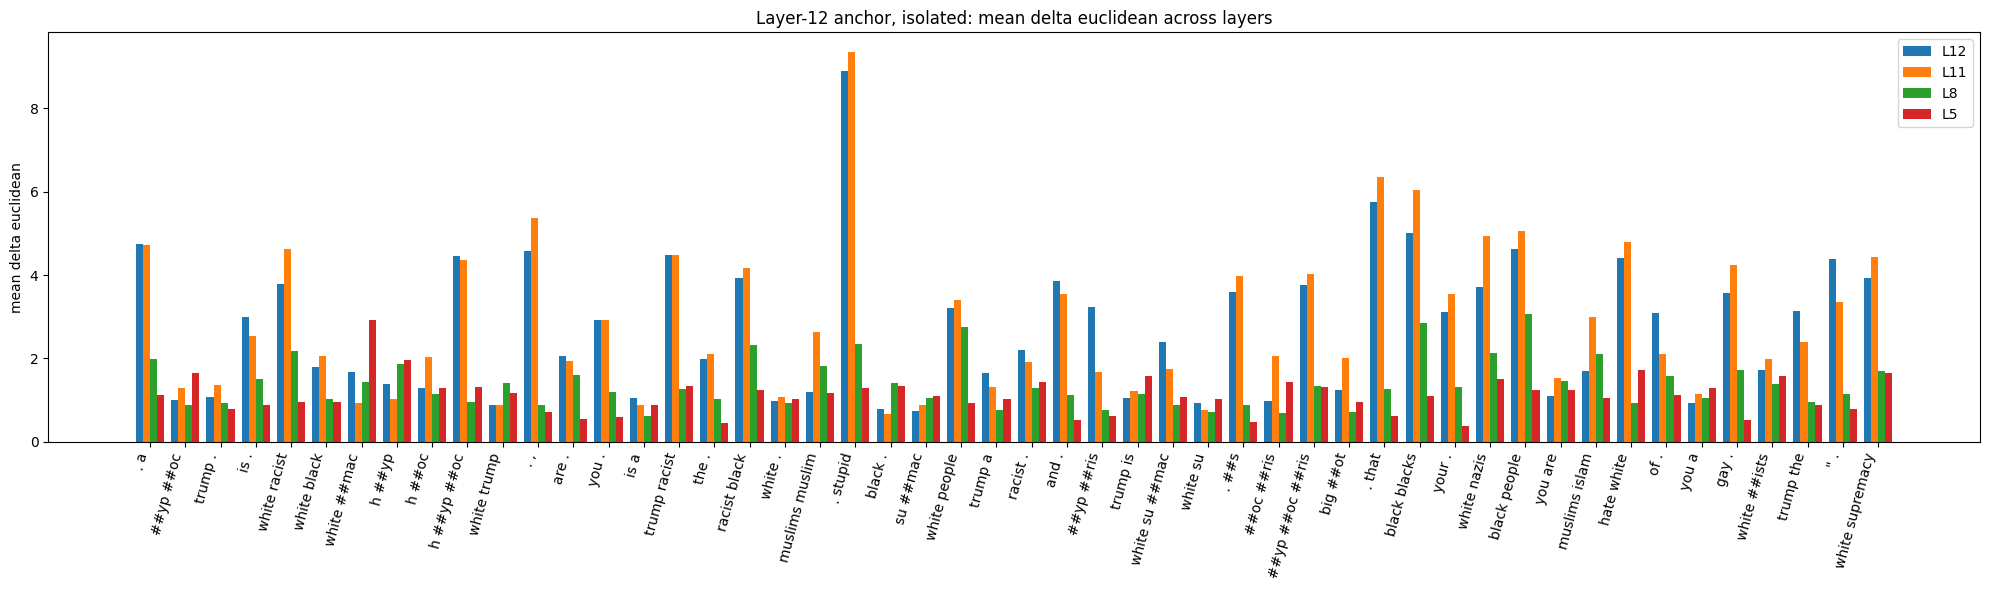

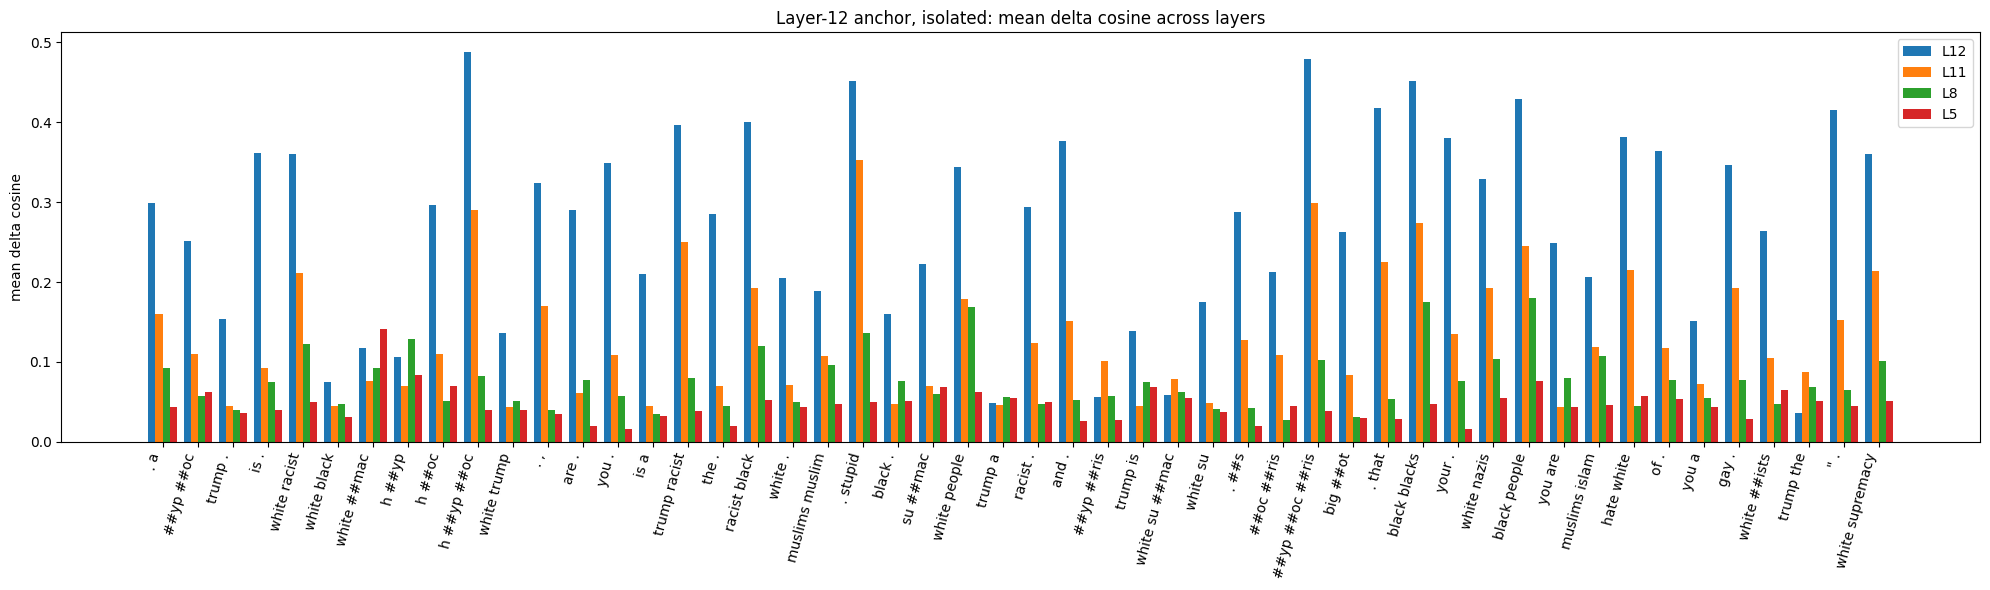

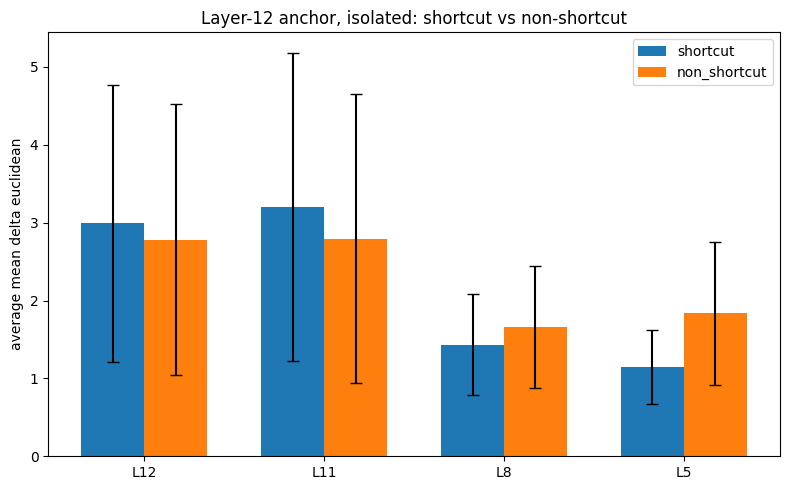

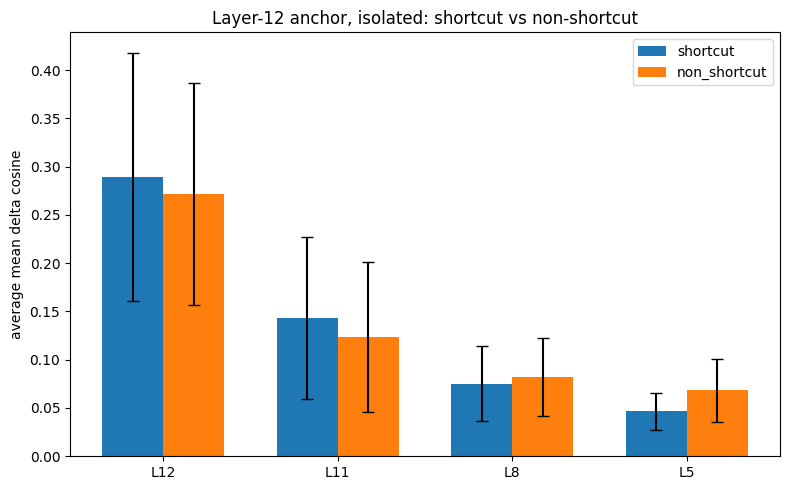

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,shortcut,L12,2.992237,1.779884,0.289628,0.128504
1,non_shortcut,L12,2.781166,1.738939,0.271876,0.115121
2,shortcut,L11,3.204083,1.980419,0.143269,0.083558
3,non_shortcut,L11,2.794699,1.855791,0.123175,0.077535
4,shortcut,L8,1.432500,0.649539,0.075165,0.038678
5,non_shortcut,L8,1.661064,0.786508,0.082342,0.040316
6,shortcut,L5,1.147844,0.473764,0.046558,0.019426
7,non_shortcut,L5,1.835453,0.915679,0.068281,0.032391


In [72]:
df_iso_l12 = run_anchor_analysis(df_mean, token_df, anchor_layer=12, context="iso")
plot_anchor_overlay(df_iso_l12, anchor_layer=12, context="iso")
plot_shortcut_vs_non_shortcut(df_iso_l12, anchor_layer=12, context="iso")

Templated

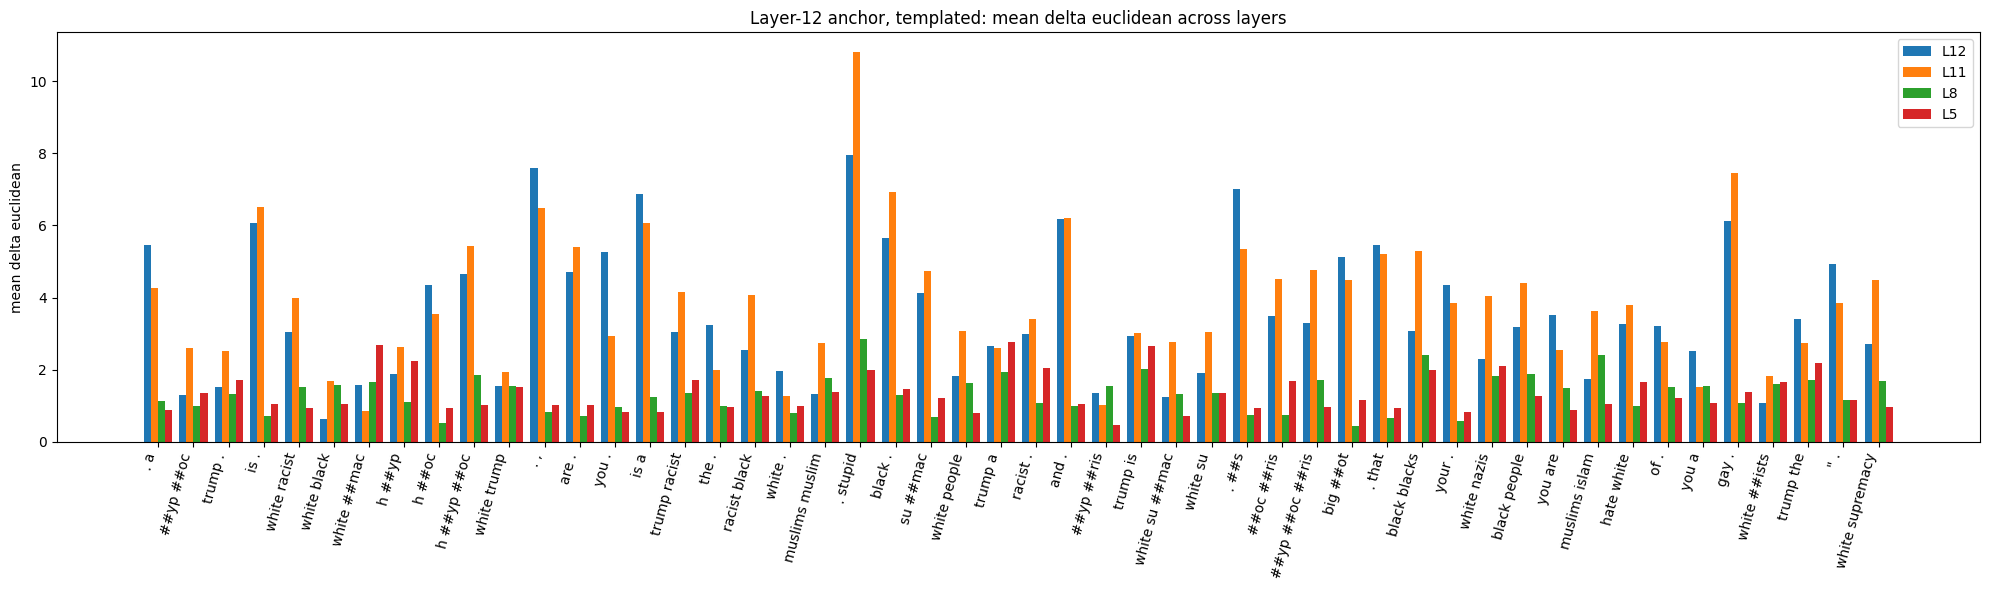

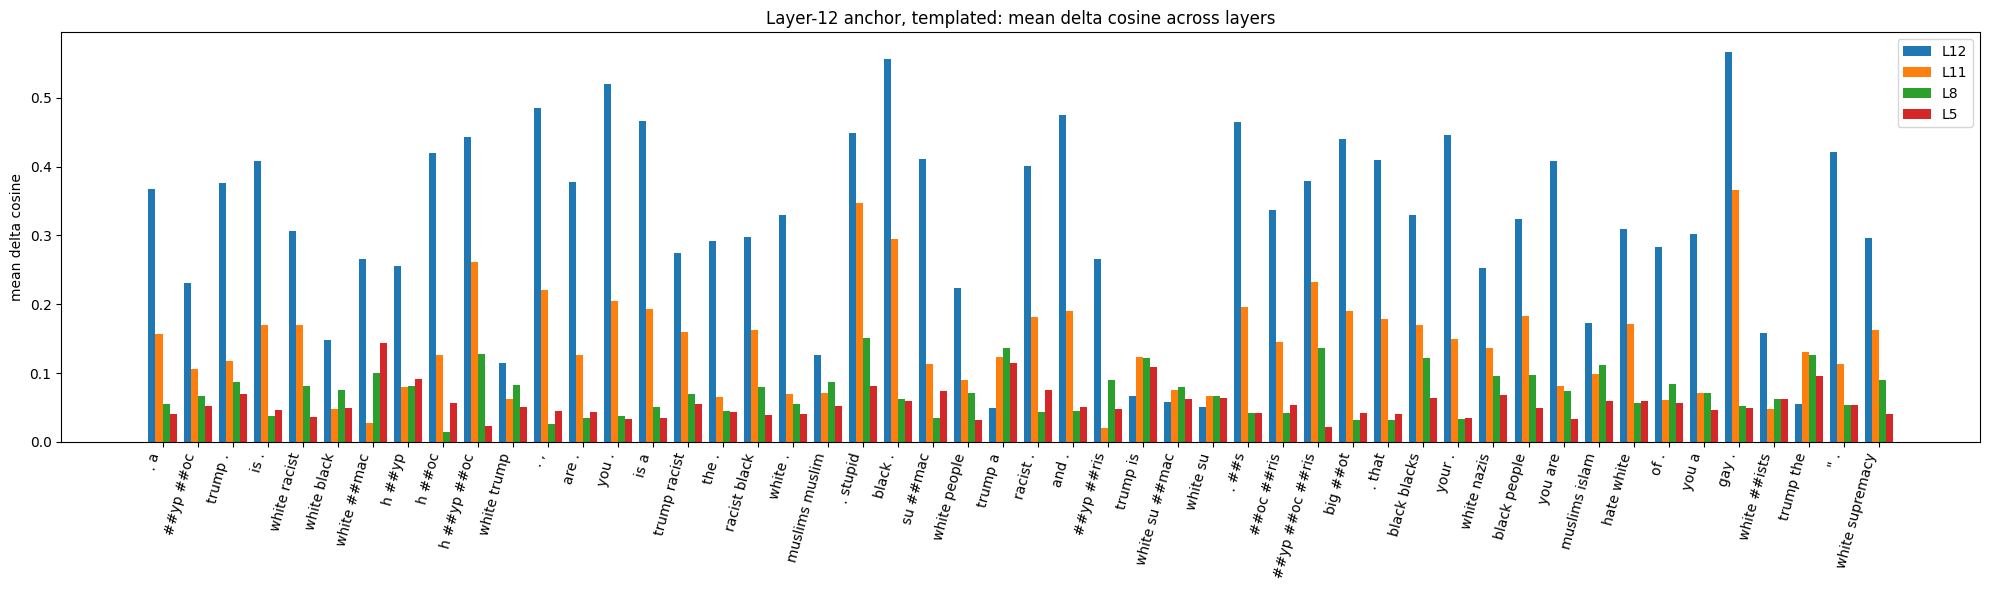

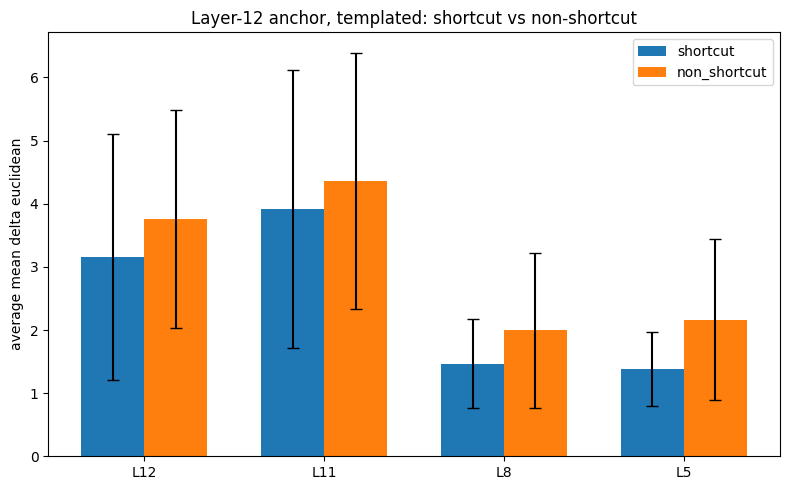

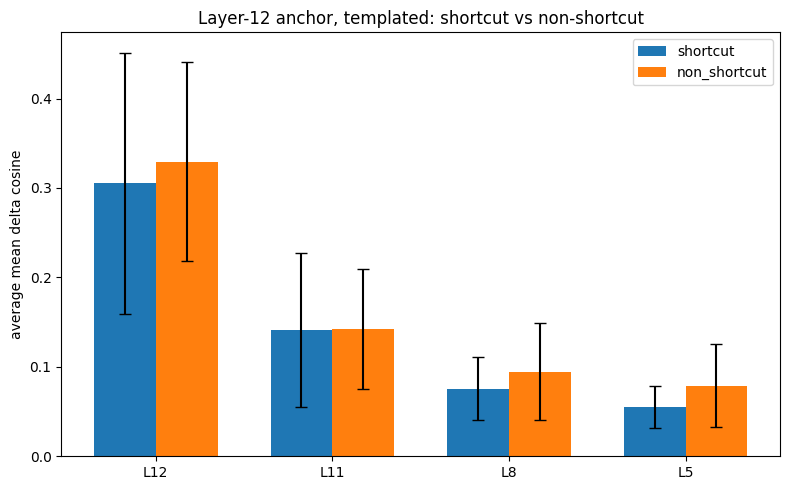

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,shortcut,L12,3.156277,1.951296,0.305098,0.146392
1,non_shortcut,L12,3.752921,1.723809,0.329251,0.111432
2,shortcut,L11,3.916181,2.206282,0.141327,0.086401
3,non_shortcut,L11,4.362644,2.032169,0.142117,0.067178
4,shortcut,L8,1.466988,0.699344,0.075508,0.035305
5,non_shortcut,L8,1.993835,1.231535,0.094387,0.054205
6,shortcut,L5,1.383486,0.582212,0.054753,0.023381
7,non_shortcut,L5,2.163407,1.274453,0.079122,0.046047


In [73]:
df_tpl_l12 = run_anchor_analysis(df_mean, token_df, anchor_layer=12, context="tpl")
plot_anchor_overlay(df_tpl_l12, anchor_layer=12, context="tpl")
plot_shortcut_vs_non_shortcut(df_tpl_l12, anchor_layer=12, context="tpl")

### Anchor layer 11

Isolated

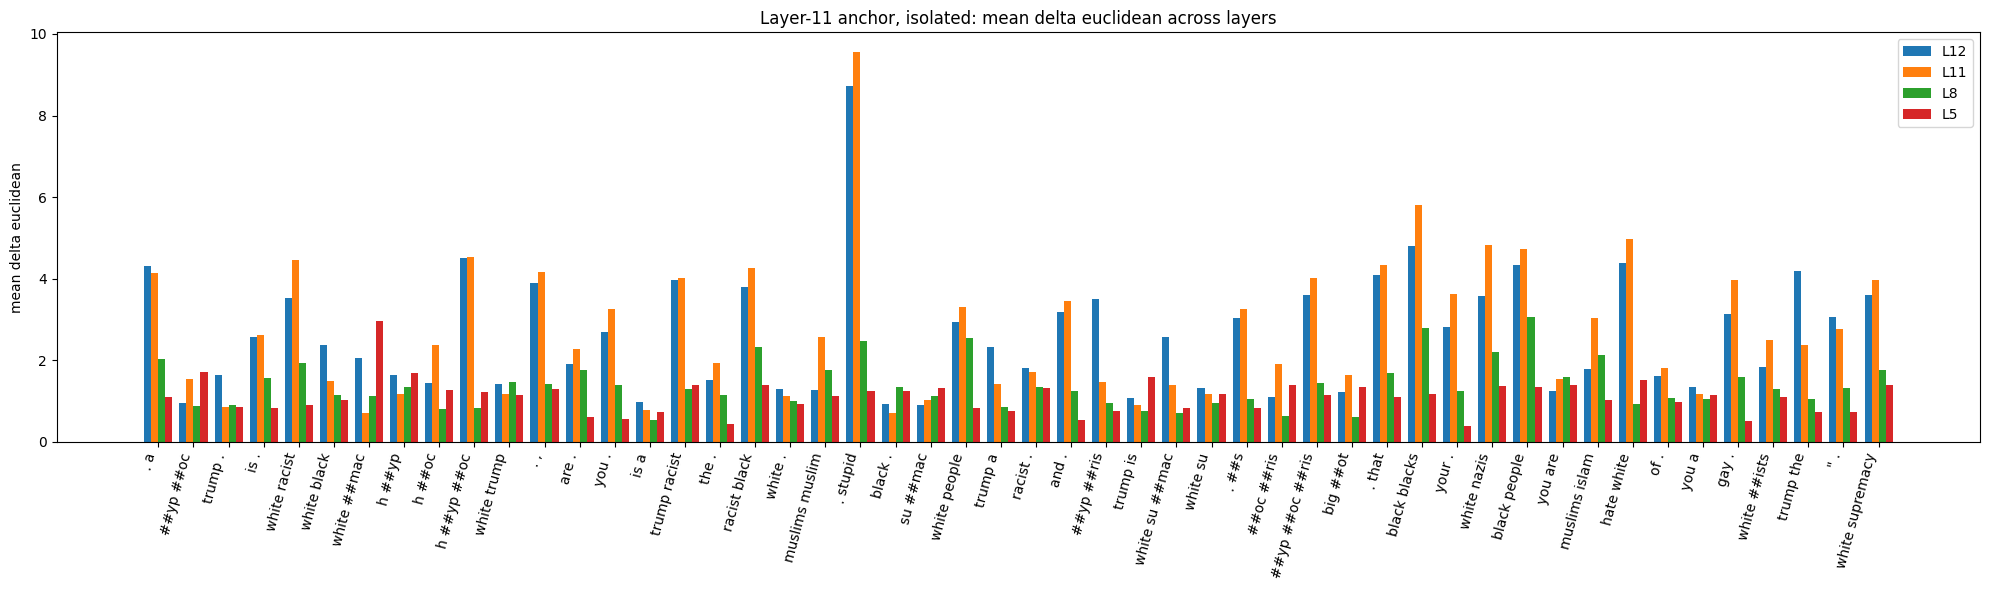

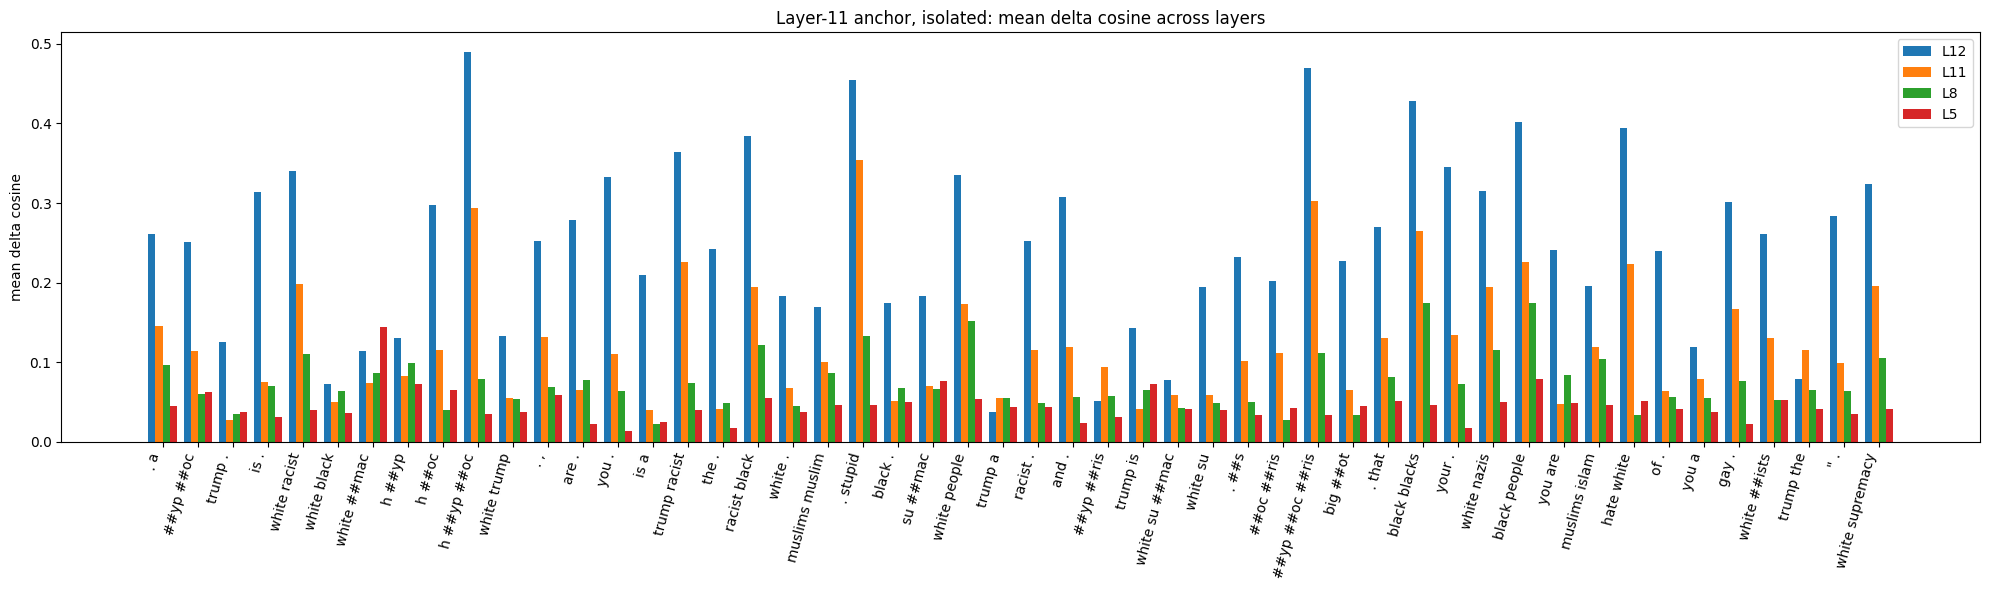

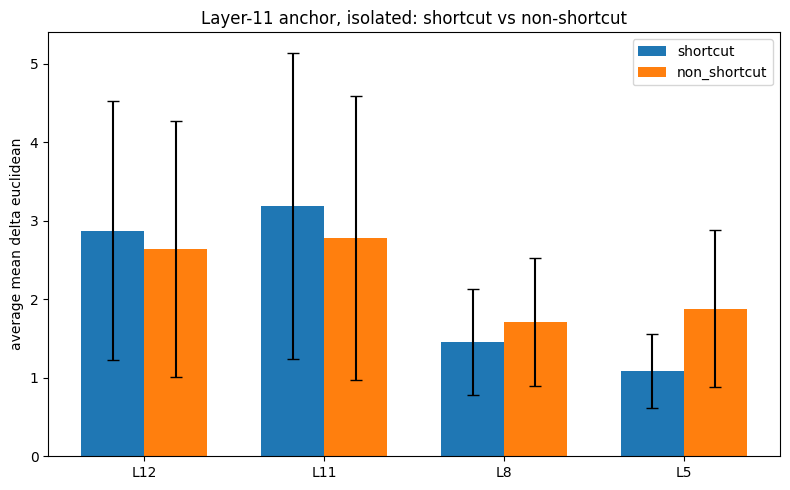

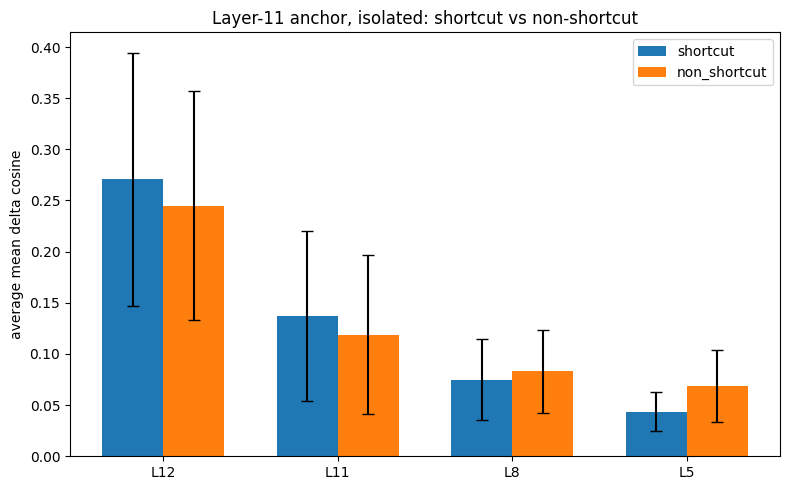

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,shortcut,L12,2.876821,1.651592,0.270665,0.123939
1,non_shortcut,L12,2.638013,1.630869,0.245075,0.111957
2,shortcut,L11,3.195112,1.950059,0.137391,0.083025
3,non_shortcut,L11,2.778144,1.808840,0.118942,0.077641
4,shortcut,L8,1.453567,0.672503,0.075022,0.039239
5,non_shortcut,L8,1.713581,0.815283,0.082914,0.040750
6,shortcut,L5,1.086359,0.468927,0.043731,0.019134
7,non_shortcut,L5,1.882522,1.003393,0.068945,0.034957


In [74]:
df_iso_l11 = run_anchor_analysis(df_mean, token_df, anchor_layer=11, context="iso")
plot_anchor_overlay(df_iso_l11, anchor_layer=11, context="iso")
plot_shortcut_vs_non_shortcut(df_iso_l11, anchor_layer=11, context="iso")

Templated


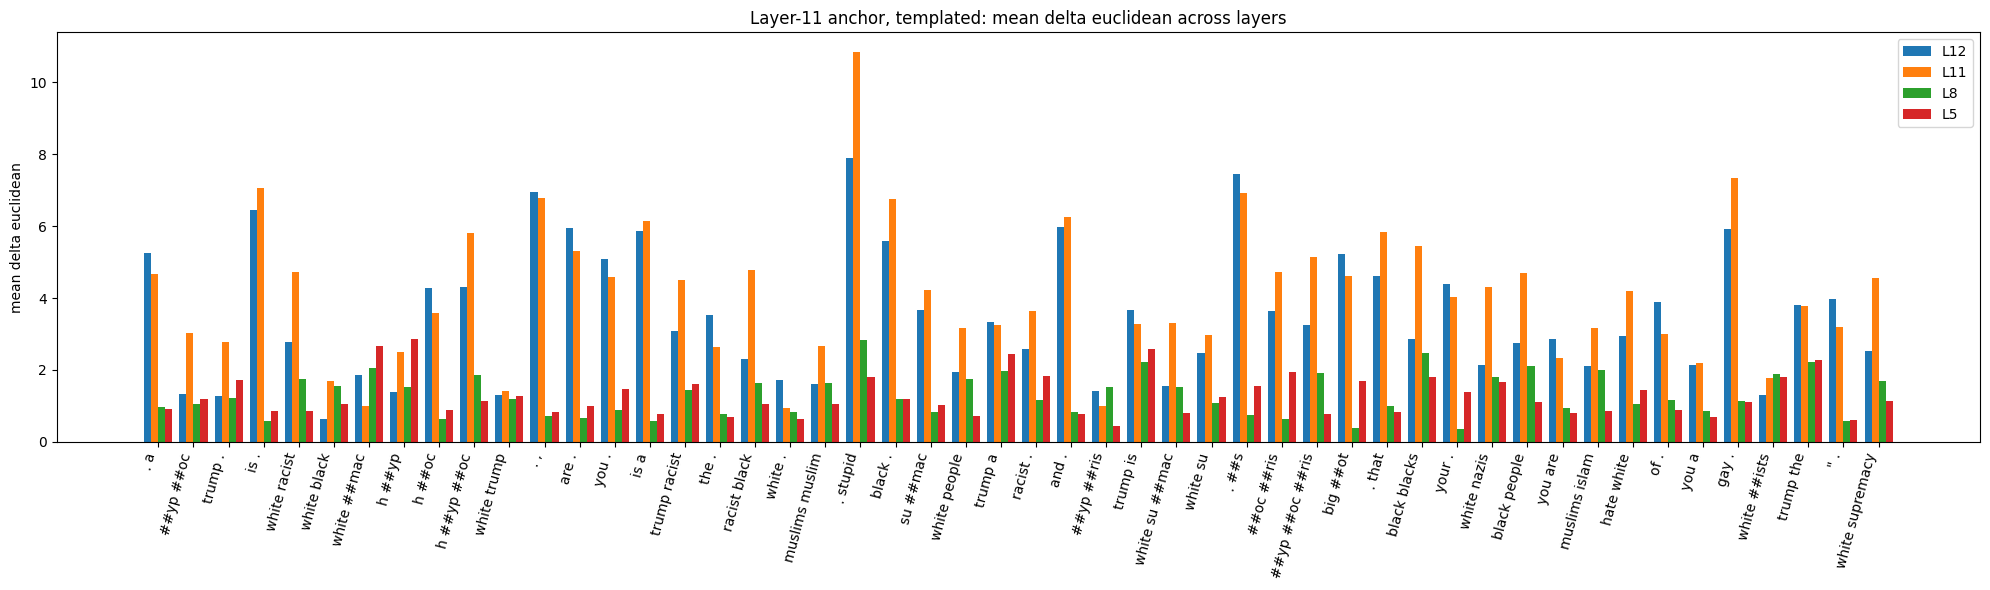

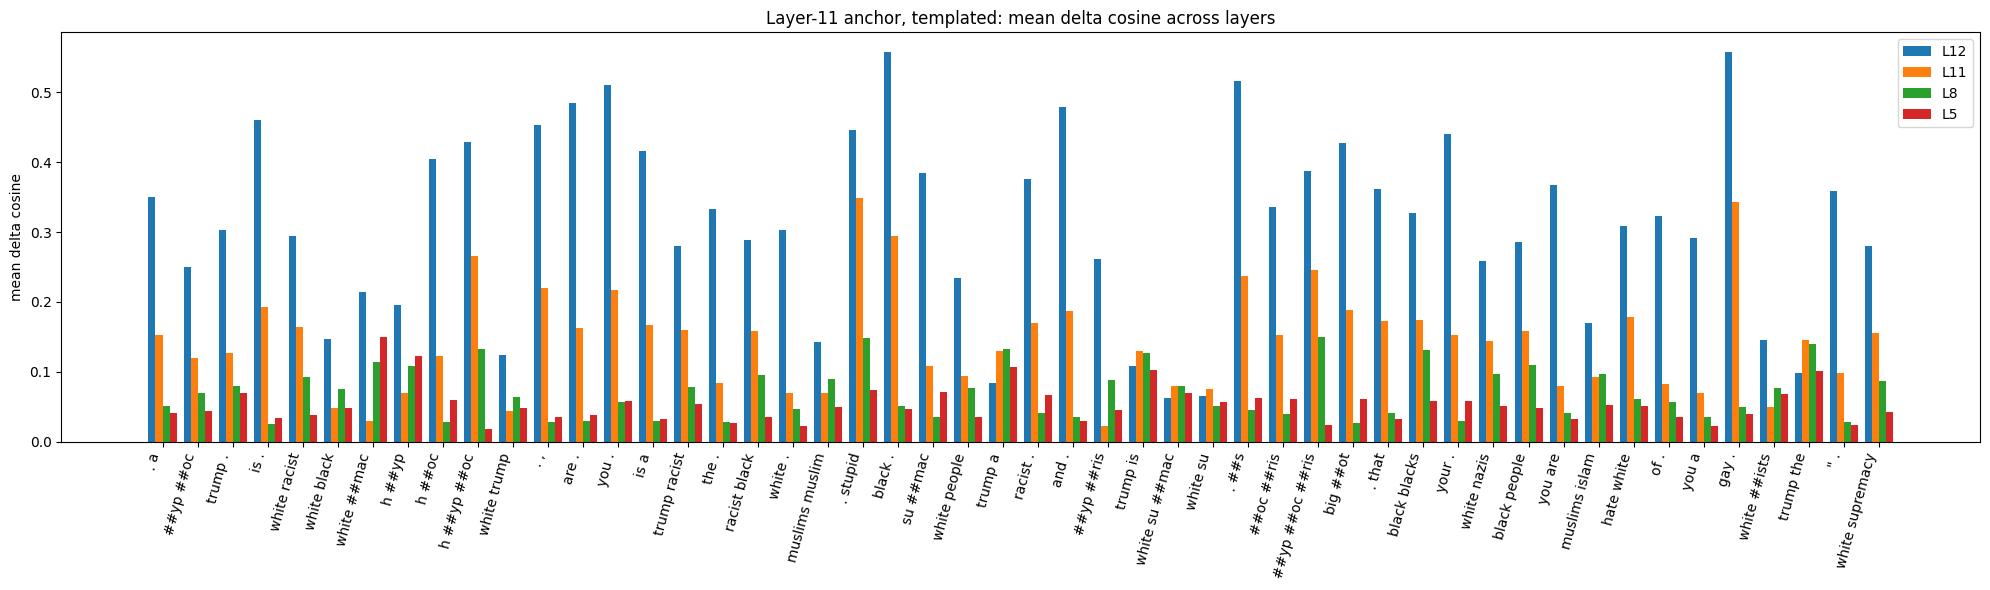

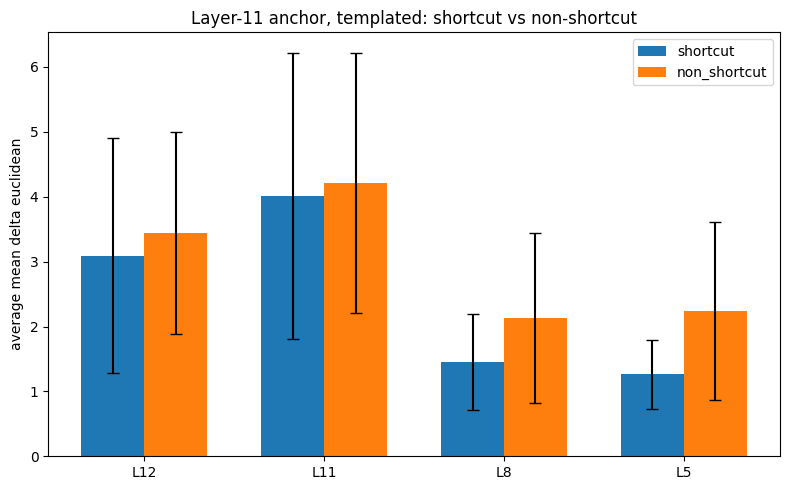

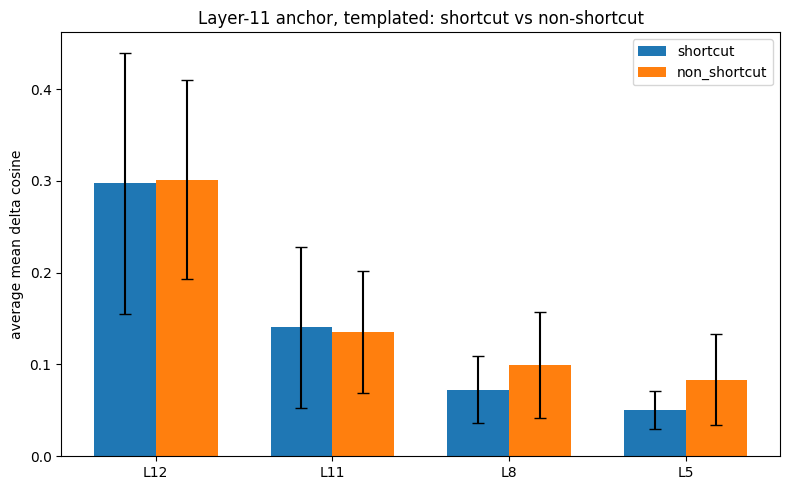

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,shortcut,L12,3.088135,1.811086,0.297582,0.142285
1,non_shortcut,L12,3.443581,1.556267,0.301392,0.108785
2,shortcut,L11,4.015427,2.203424,0.140670,0.087768
3,non_shortcut,L11,4.215557,2.006937,0.135748,0.066405
4,shortcut,L8,1.447238,0.739984,0.072565,0.036310
5,non_shortcut,L8,2.130045,1.308998,0.099732,0.057706
6,shortcut,L5,1.264433,0.531728,0.050457,0.020668
7,non_shortcut,L5,2.245072,1.372231,0.083247,0.049545


In [75]:
df_tpl_l11 = run_anchor_analysis(df_mean, token_df, anchor_layer=11, context="tpl")
plot_anchor_overlay(df_tpl_l11, anchor_layer=11, context="tpl")
plot_shortcut_vs_non_shortcut(df_tpl_l11, anchor_layer=11, context="tpl")

### Anchor Layer 8

Isolated

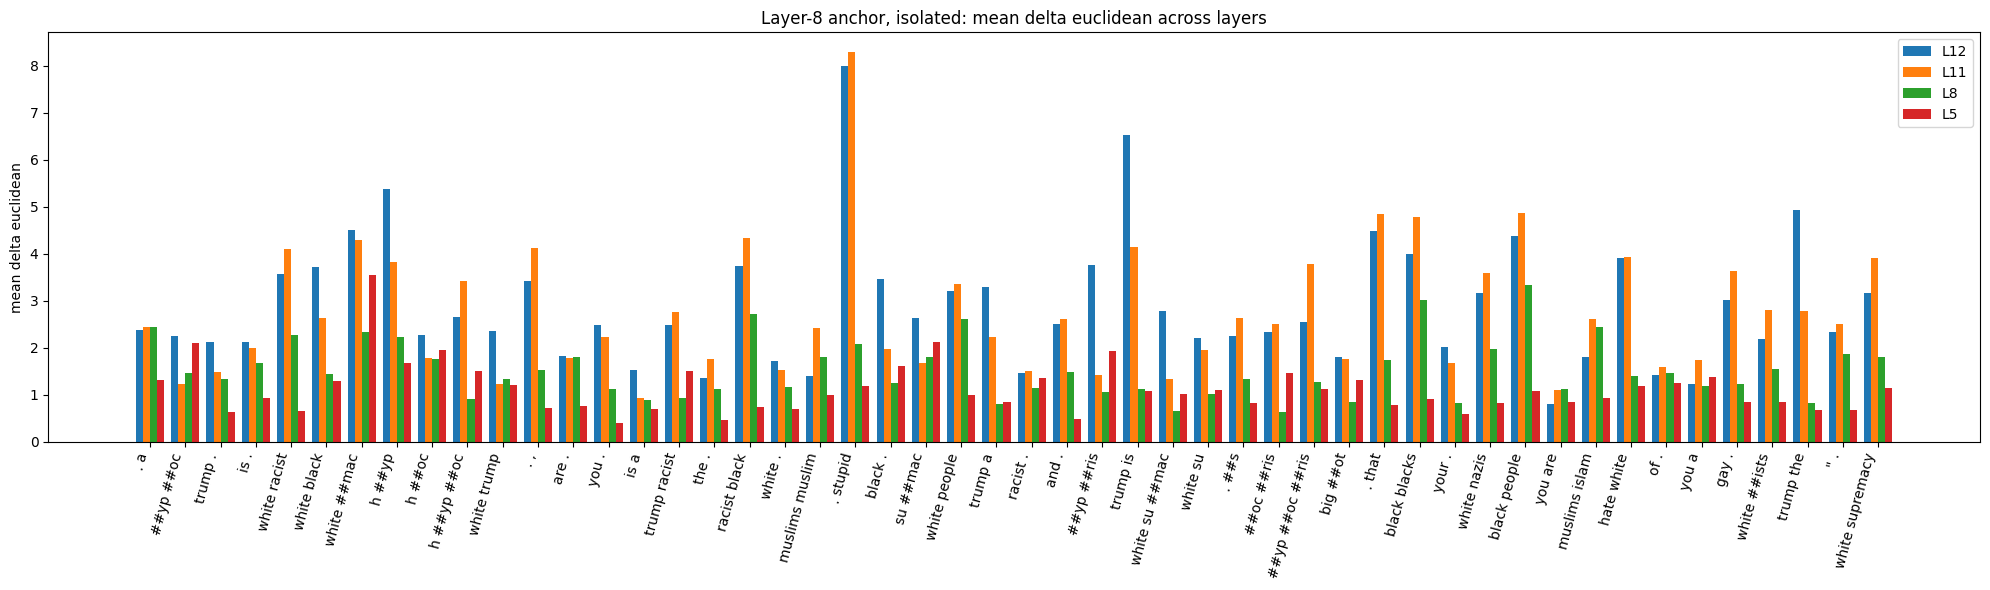

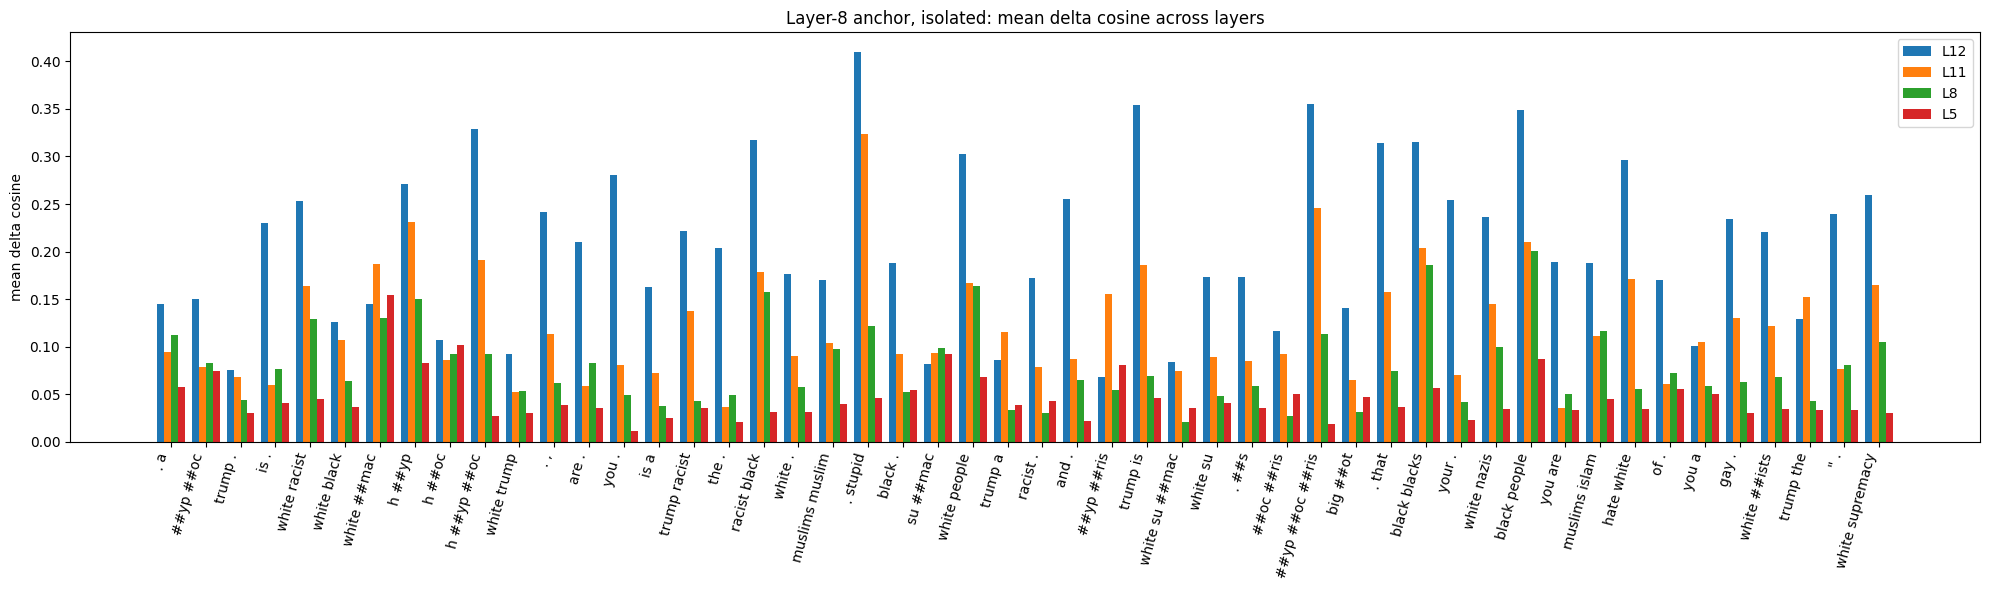

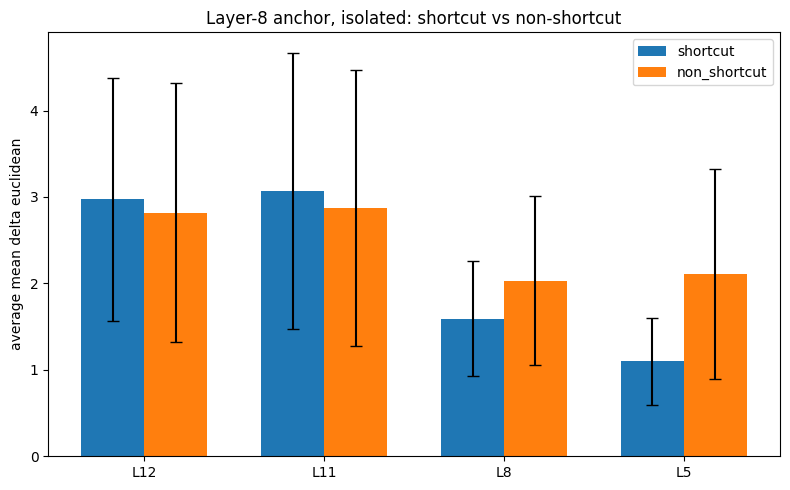

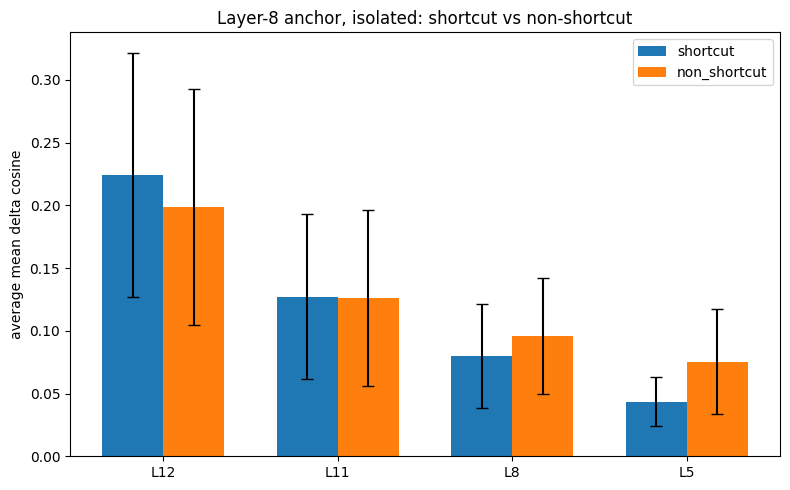

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,shortcut,L12,2.971295,1.404563,0.224349,0.097485
1,non_shortcut,L12,2.818383,1.500551,0.198657,0.094363
2,shortcut,L11,3.074111,1.597495,0.127203,0.065871
3,non_shortcut,L11,2.870602,1.595189,0.126063,0.070369
4,shortcut,L8,1.593703,0.670600,0.079742,0.041348
5,non_shortcut,L8,2.033634,0.975120,0.096103,0.046346
6,shortcut,L5,1.099960,0.501971,0.043321,0.019477
7,non_shortcut,L5,2.107760,1.216894,0.075519,0.042052


In [76]:
df_iso_l8 = run_anchor_analysis(df_mean, token_df, anchor_layer=8, context="iso")
plot_anchor_overlay(df_iso_l8, anchor_layer=8, context="iso")
plot_shortcut_vs_non_shortcut(df_iso_l8, anchor_layer=8, context="iso")

Templated

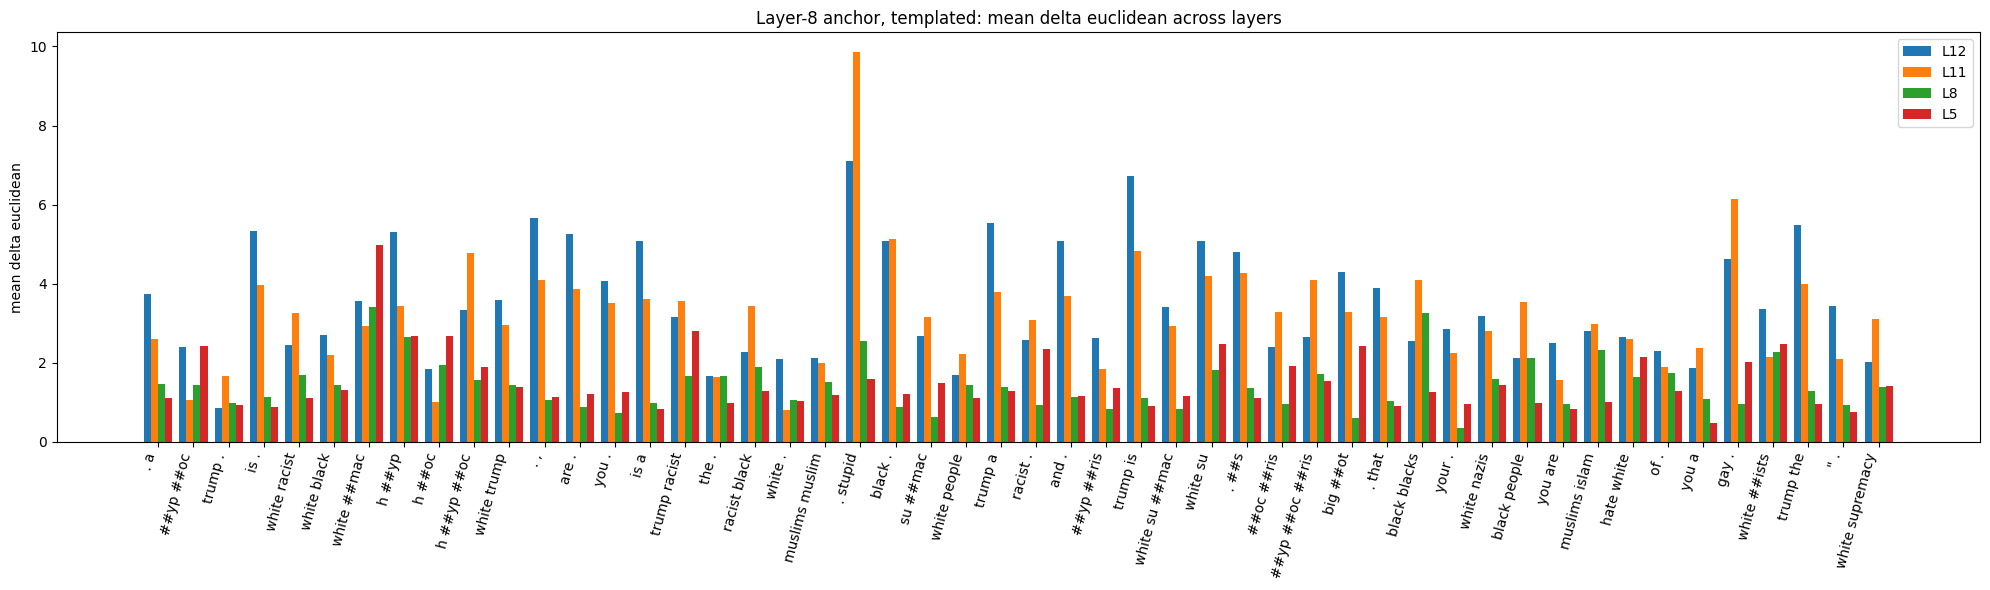

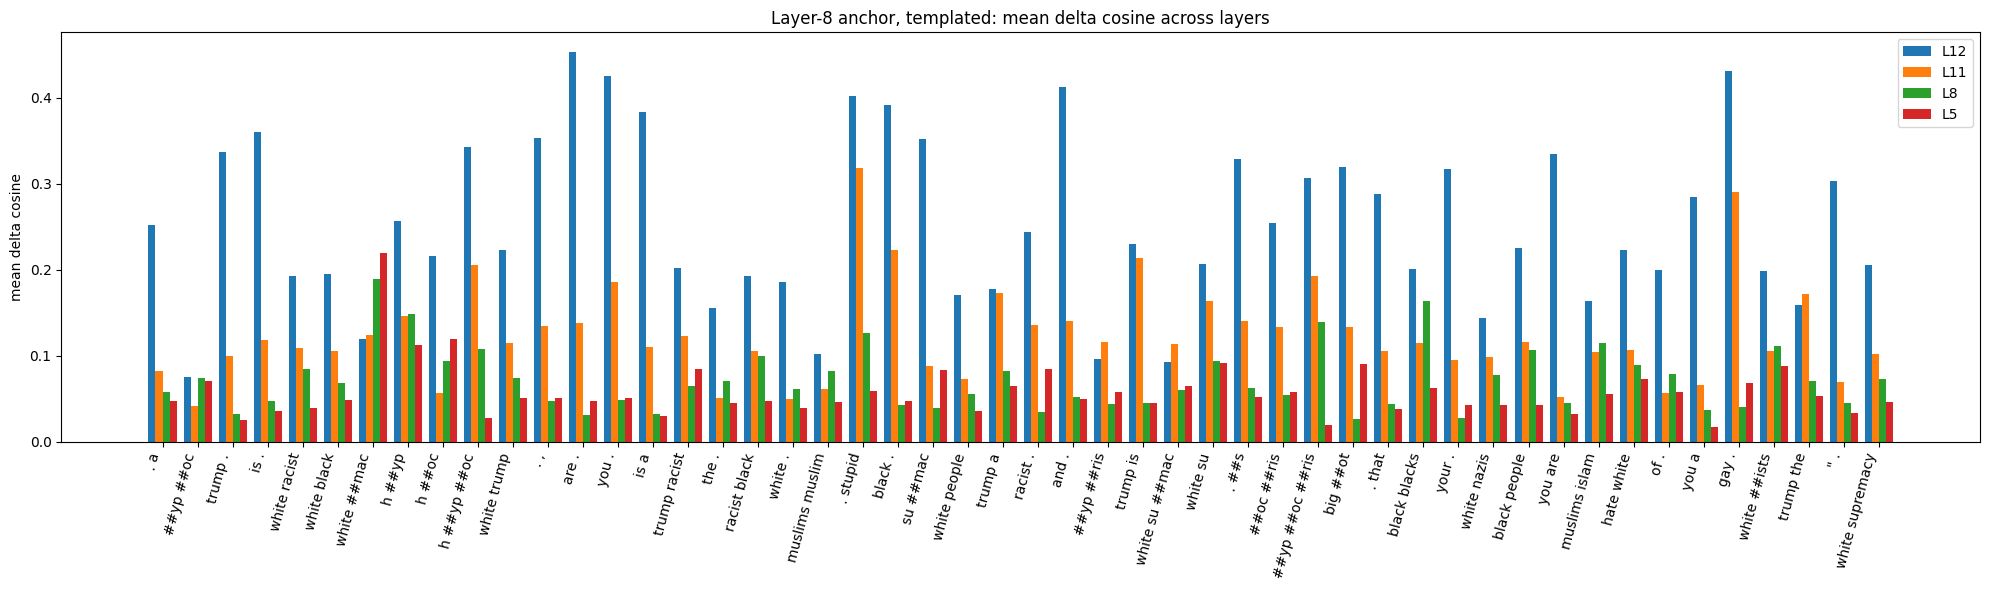

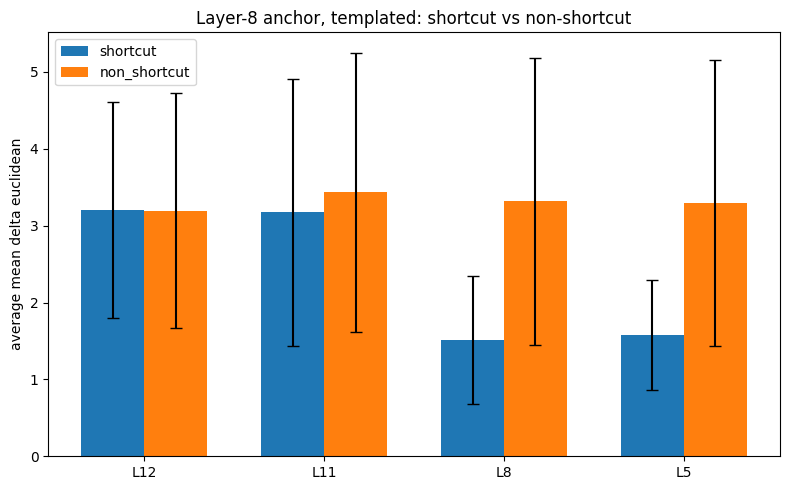

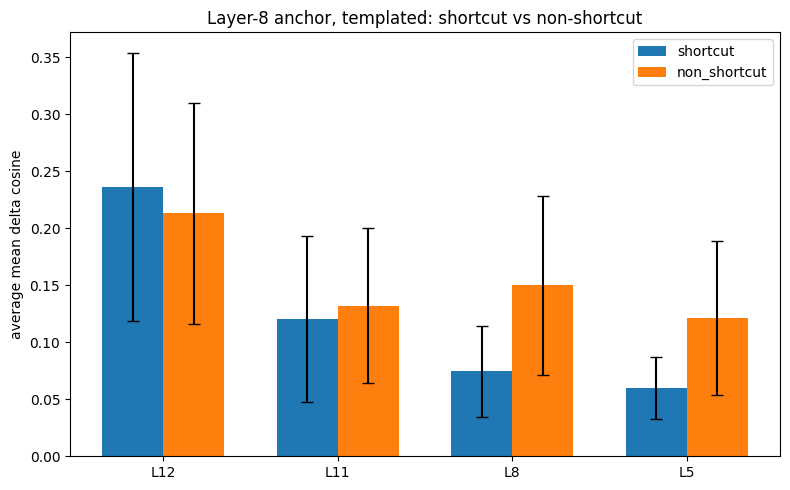

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,shortcut,L12,3.207051,1.403735,0.236527,0.117721
1,non_shortcut,L12,3.191417,1.529124,0.213140,0.097211
2,shortcut,L11,3.172556,1.733850,0.120358,0.072618
3,non_shortcut,L11,3.437130,1.814827,0.132237,0.068139
4,shortcut,L8,1.513715,0.834844,0.074456,0.040051
5,non_shortcut,L8,3.315793,1.866648,0.150014,0.078452
6,shortcut,L5,1.573792,0.715480,0.060258,0.027233
7,non_shortcut,L5,3.298802,1.862262,0.121329,0.067181


In [77]:
df_tpl_l8 = run_anchor_analysis(df_mean, token_df, anchor_layer=8, context="tpl")
plot_anchor_overlay(df_tpl_l8, anchor_layer=8, context="tpl")
plot_shortcut_vs_non_shortcut(df_tpl_l8, anchor_layer=8, context="tpl")

### Anchor Layer 5

Isolate 

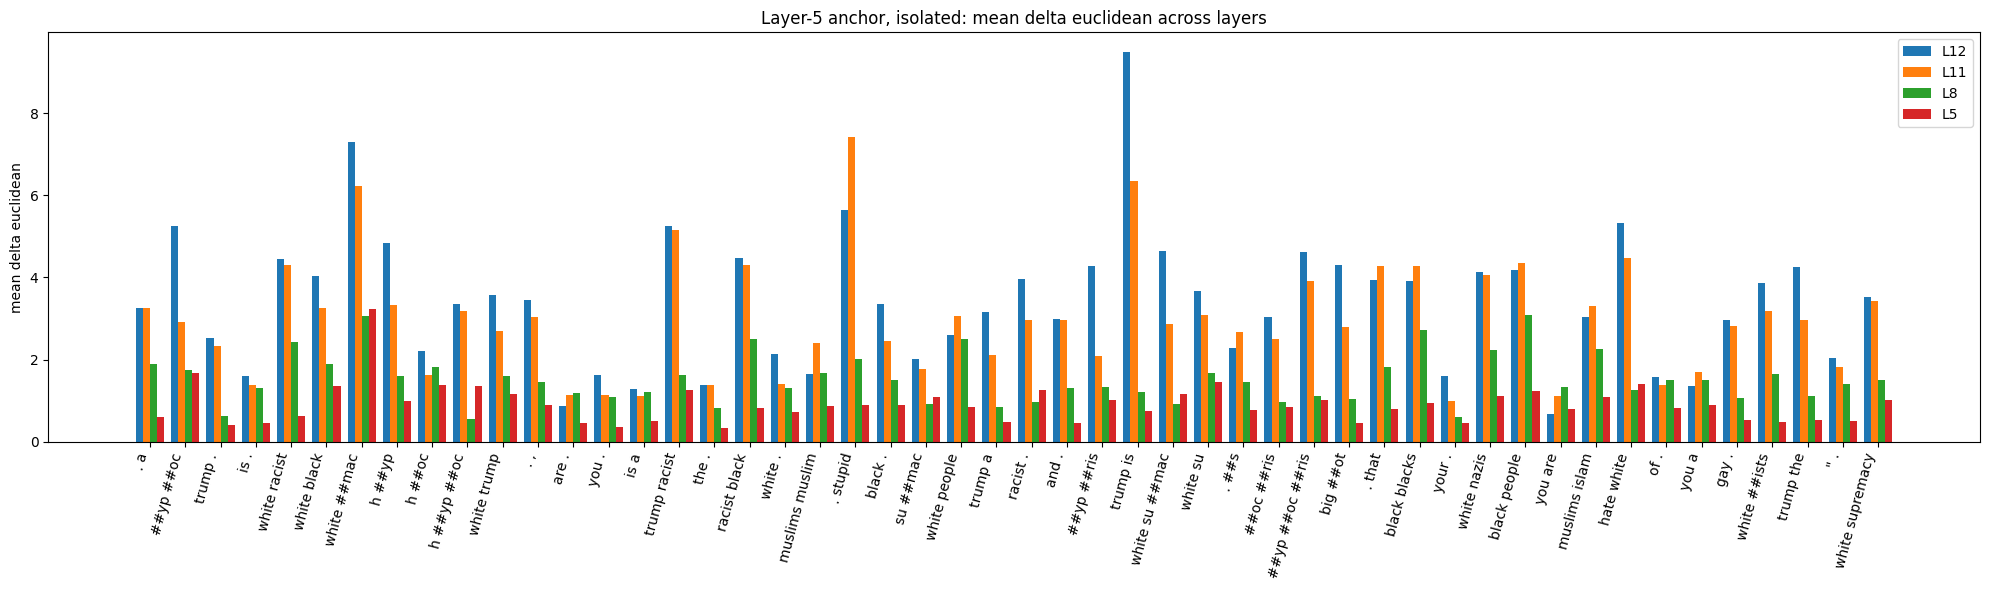

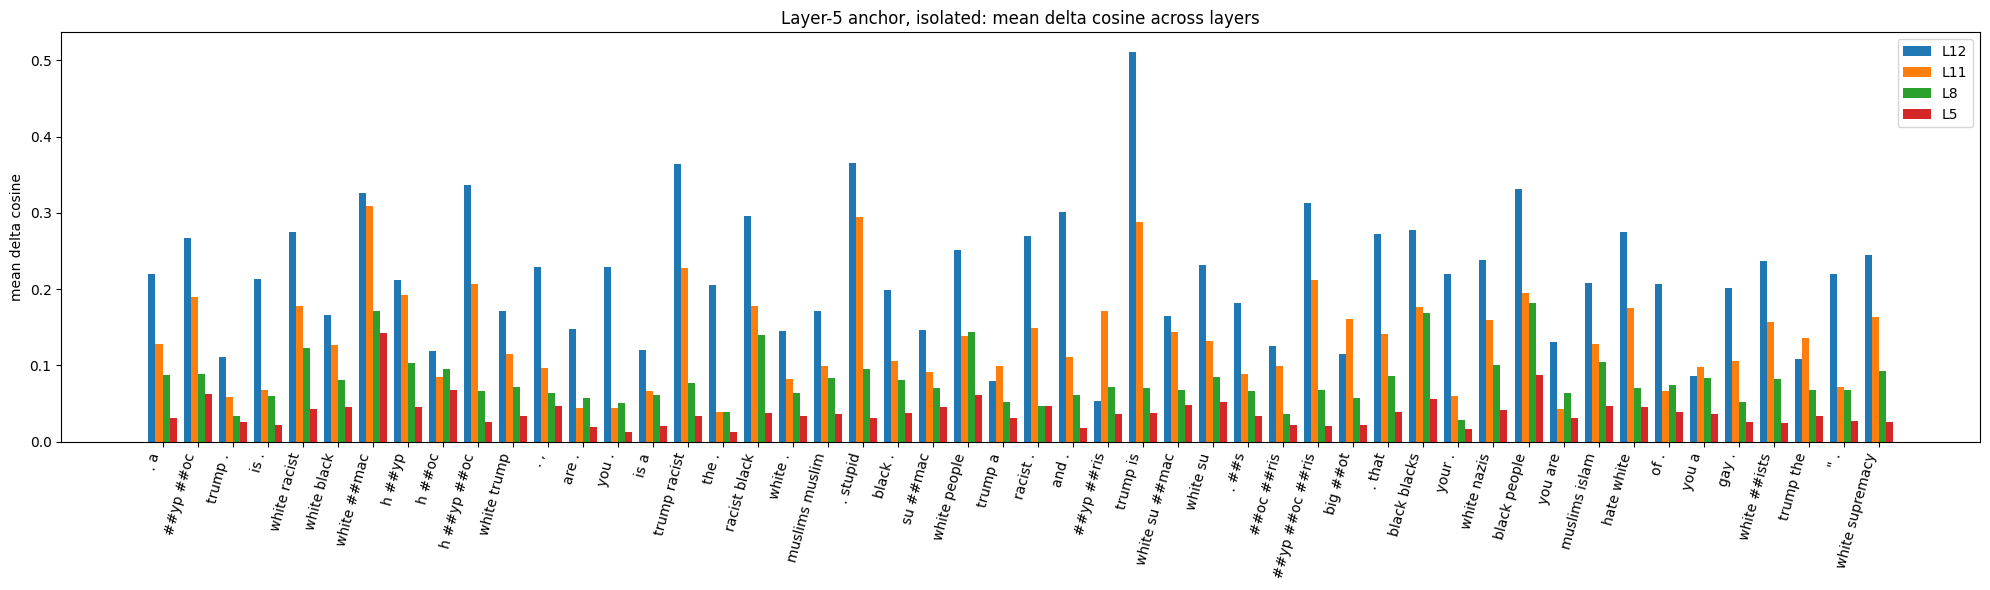

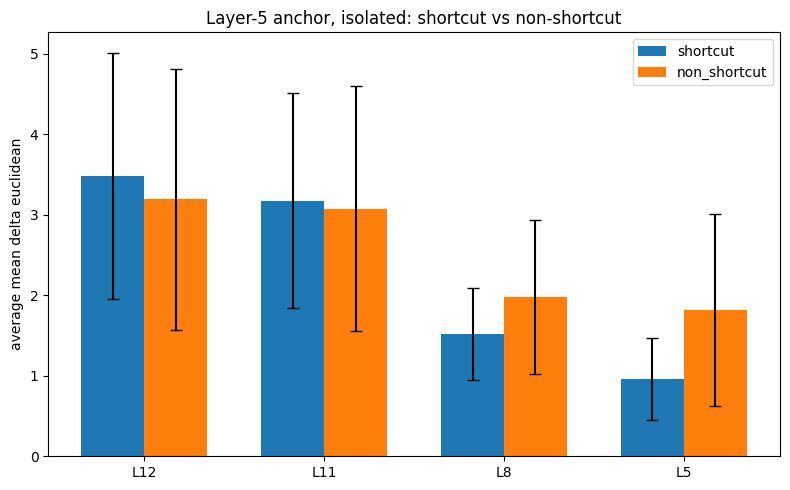

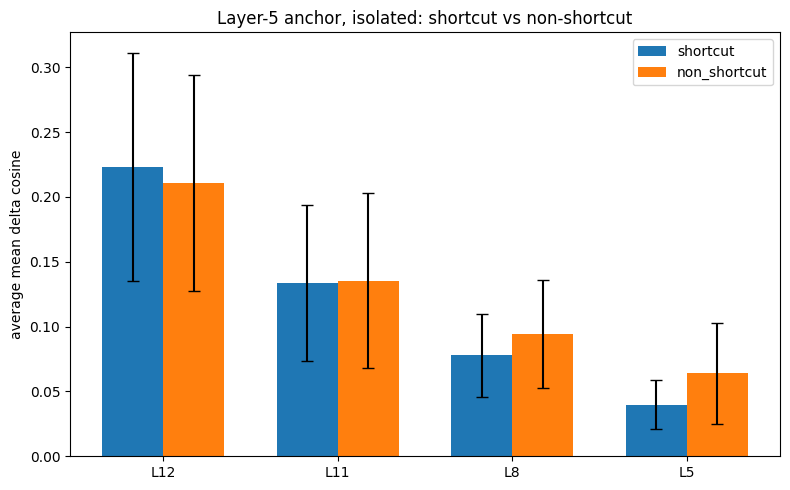

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,shortcut,L12,3.481584,1.531330,0.223250,0.088108
1,non_shortcut,L12,3.191439,1.618511,0.210623,0.083084
2,shortcut,L11,3.174973,1.335832,0.133835,0.060269
3,non_shortcut,L11,3.074511,1.517386,0.135257,0.067562
4,shortcut,L8,1.522282,0.572974,0.077854,0.032148
5,non_shortcut,L8,1.977165,0.959495,0.094261,0.041501
6,shortcut,L5,0.961510,0.506574,0.039742,0.018940
7,non_shortcut,L5,1.820844,1.192014,0.063856,0.038710


In [78]:
df_iso_l5 = run_anchor_analysis(df_mean, token_df, anchor_layer=5, context="iso")
plot_anchor_overlay(df_iso_l5, anchor_layer=5, context="iso")
plot_shortcut_vs_non_shortcut(df_iso_l5, anchor_layer=5, context="iso")

Templated

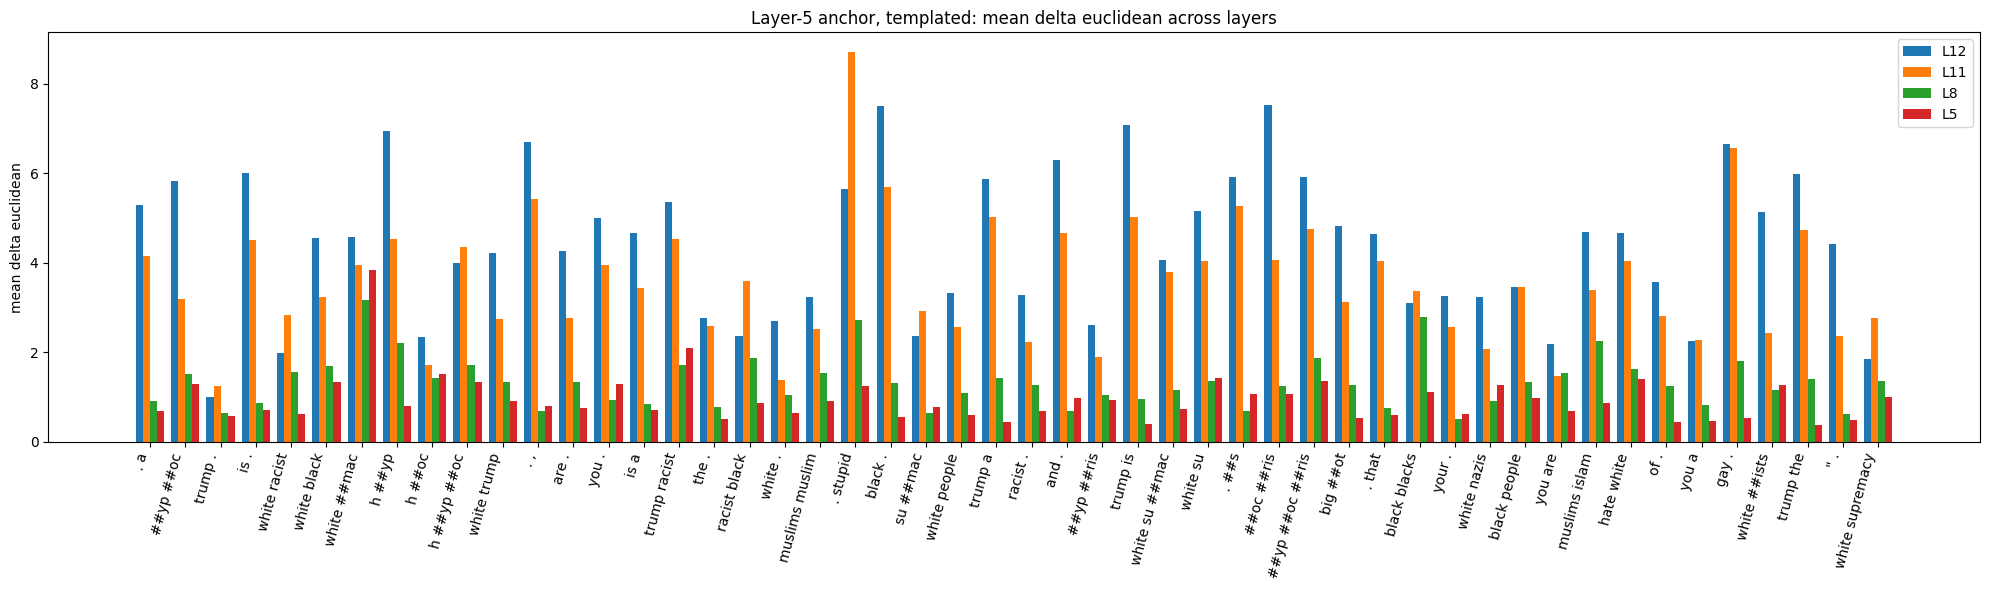

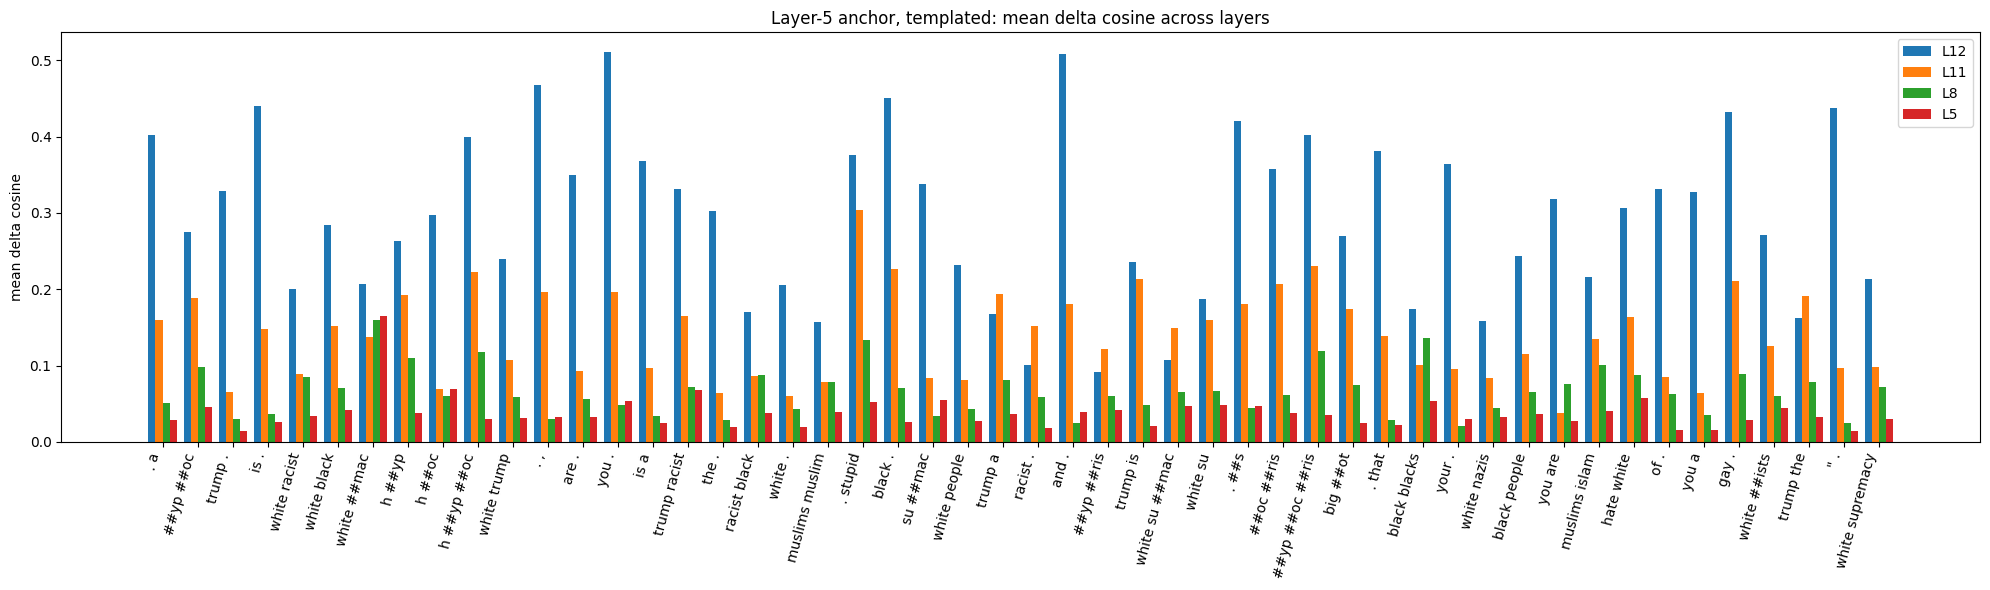

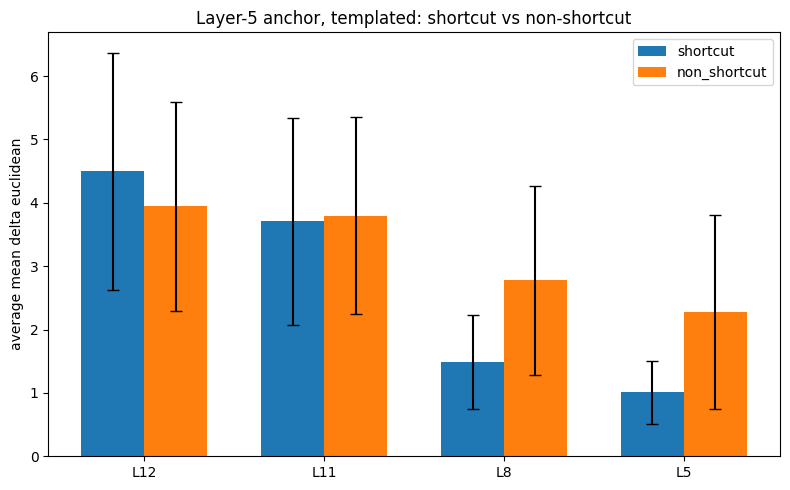

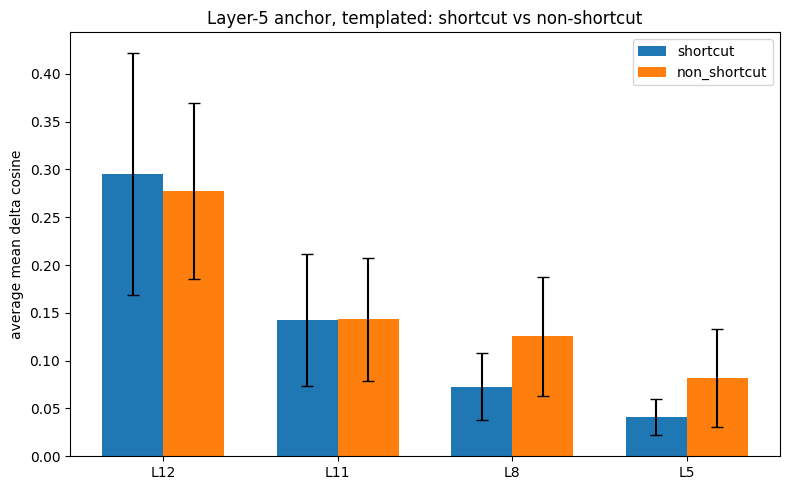

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,shortcut,L12,4.494943,1.875833,0.295321,0.126888
1,non_shortcut,L12,3.944161,1.646383,0.277516,0.092009
2,shortcut,L11,3.709543,1.631245,0.142514,0.069203
3,non_shortcut,L11,3.798185,1.549853,0.143399,0.064324
4,shortcut,L8,1.487374,0.747169,0.072467,0.035025
5,non_shortcut,L8,2.775744,1.486797,0.125284,0.061934
6,shortcut,L5,1.009120,0.494137,0.040693,0.018913
7,non_shortcut,L5,2.273456,1.530571,0.081963,0.051111


In [79]:
df_tpl_l5 = run_anchor_analysis(df_mean, token_df, anchor_layer=5, context="tpl")
plot_anchor_overlay(df_tpl_l5, anchor_layer=5, context="tpl")
plot_shortcut_vs_non_shortcut(df_tpl_l5, anchor_layer=5, context="tpl")

In [80]:
import numpy as np
import matplotlib.pyplot as plt

def plot_anchor_same_layer_with_std(
    df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
    top_n=50,
    min_length=2,
    sort_col="support",
):
    assert context in {"iso", "tpl"}

    if context == "iso":
        euc_mean_col = f"mean_delta_l{anchor_layer}_euclidean_l{anchor_layer}"
        euc_raw_col  = f"delta_l{anchor_layer}_euclidean_l{anchor_layer}"
        cos_mean_col = f"mean_delta_l{anchor_layer}_cosine_l{anchor_layer}"
        cos_raw_col  = f"delta_l{anchor_layer}_cosine_l{anchor_layer}"
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_mean_col = f"mean_delta_tpl_l{anchor_layer}_euclidean_l{anchor_layer}"
        euc_raw_col  = f"delta_tpl_l{anchor_layer}_euclidean_l{anchor_layer}"
        cos_mean_col = f"mean_delta_tpl_l{anchor_layer}_cosine_l{anchor_layer}"
        cos_raw_col  = f"delta_tpl_l{anchor_layer}_cosine_l{anchor_layer}"
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    plot_df = (
        df[df["length"] >= min_length]
        .sort_values(sort_col, ascending=False)
        .head(top_n)
        .copy()
    )

    plot_df["label"] = plot_df["ordered_tokens"].apply(
        lambda x: " ".join(x) if isinstance(x, list) else str(x)
    )

    # std over the raw NN delta values for each itemset
    plot_df["std_euclidean"] = plot_df[euc_raw_col].apply(
        lambda xs: float(np.std(xs)) if len(xs) > 0 else 0.0
    )
    plot_df["std_cosine"] = plot_df[cos_raw_col].apply(
        lambda xs: float(np.std(xs)) if len(xs) > 0 else 0.0
    )

    x = np.arange(len(plot_df))

    # Euclidean
    plt.figure(figsize=(20, 6))
    plt.bar(
        x,
        plot_df[euc_mean_col],
        yerr=plot_df["std_euclidean"],
        capsize=4
    )
    plt.xticks(x, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta euclidean")
    plt.title(f"{title_prefix}: same-layer delta euclidean only")
    plt.tight_layout()
    plt.show()

    # Cosine
    plt.figure(figsize=(20, 6))
    plt.bar(
        x,
        plot_df[cos_mean_col],
        yerr=plot_df["std_cosine"],
        capsize=4
    )
    plt.xticks(x, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta cosine")
    plt.title(f"{title_prefix}: same-layer delta cosine only")
    plt.tight_layout()
    plt.show()

    return plot_df[
        [
            "label",
            euc_mean_col,
            "std_euclidean",
            cos_mean_col,
            "std_cosine",
        ]
    ]

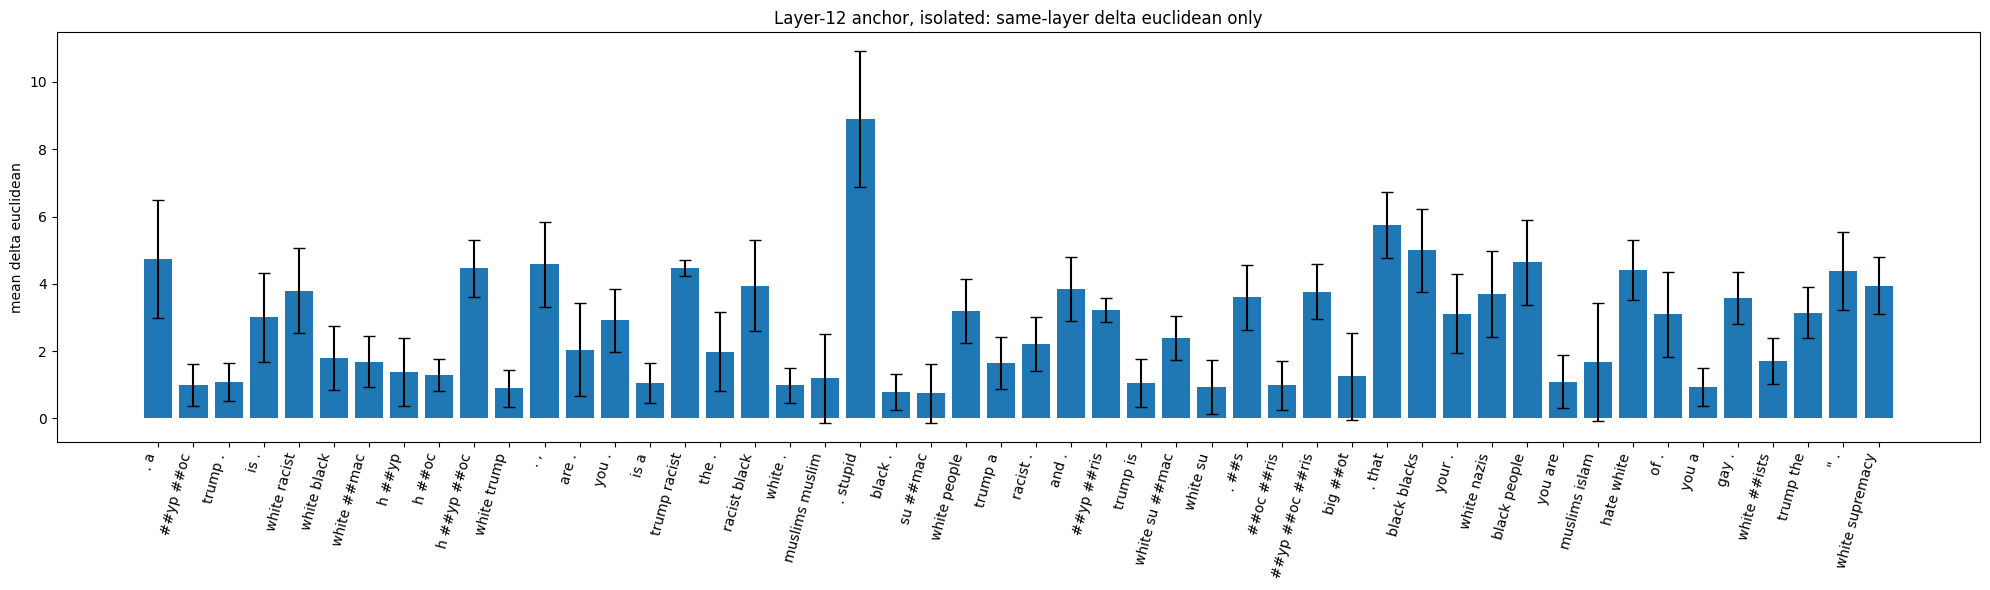

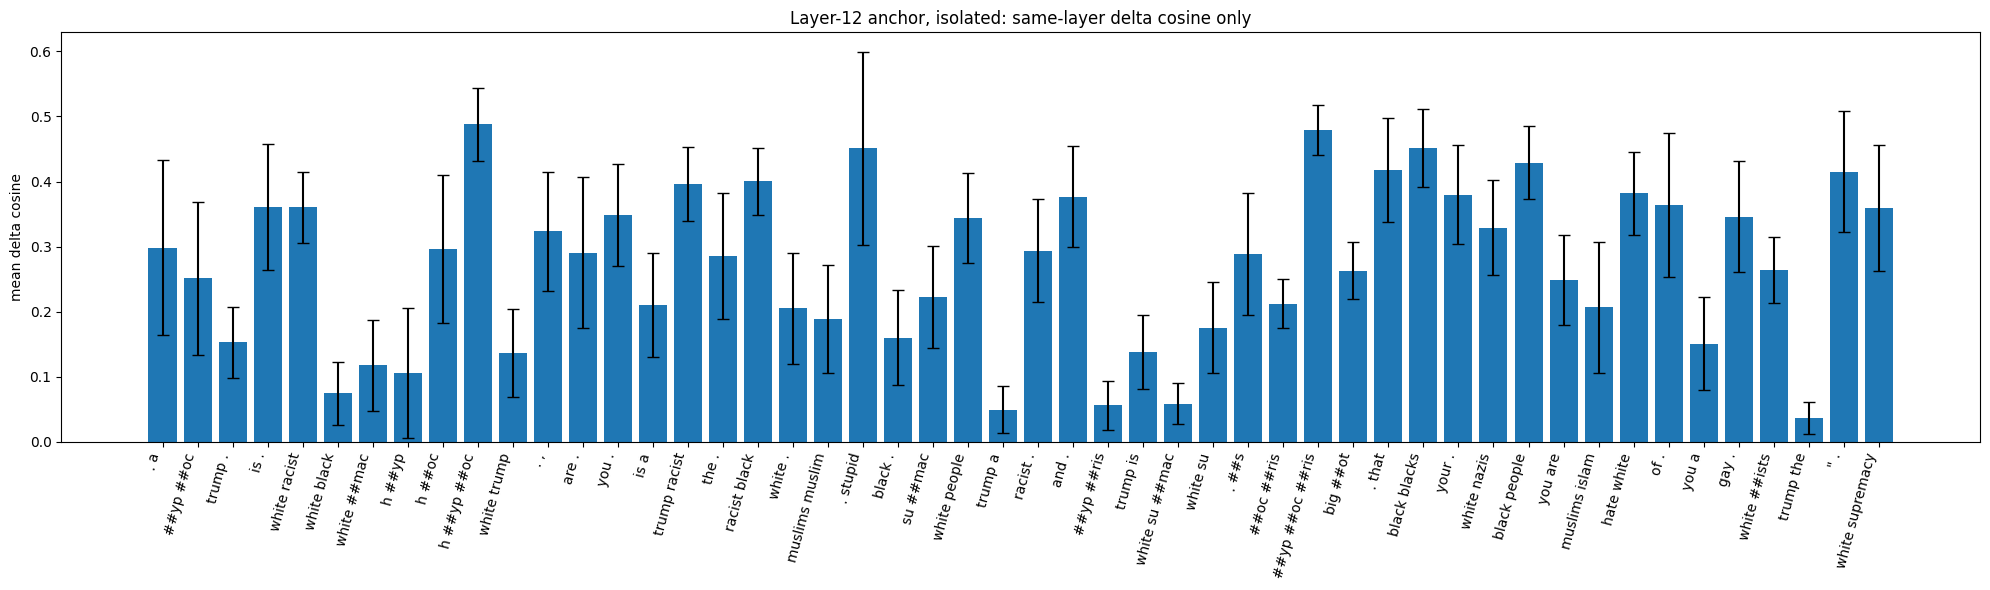

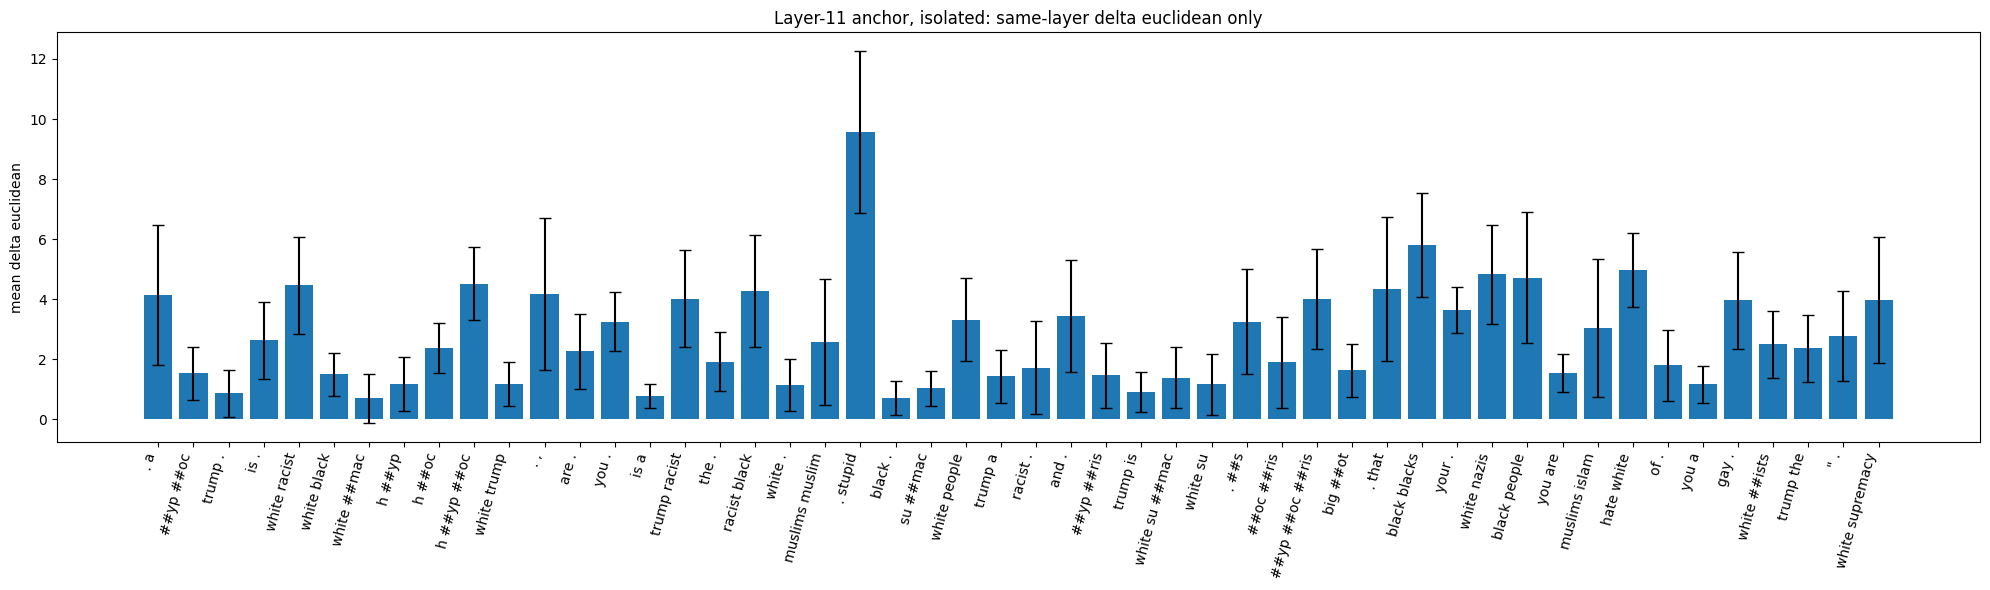

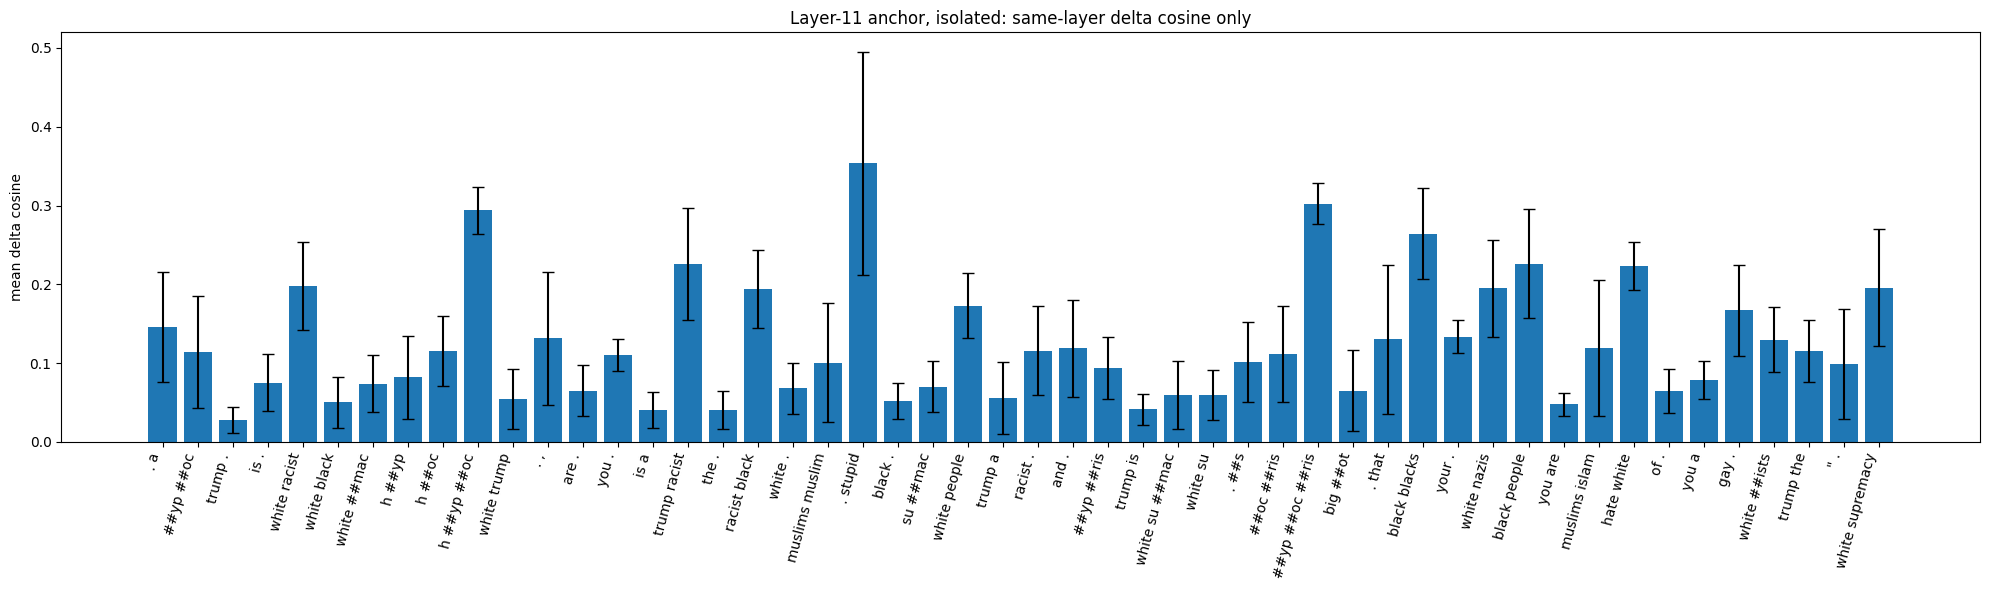

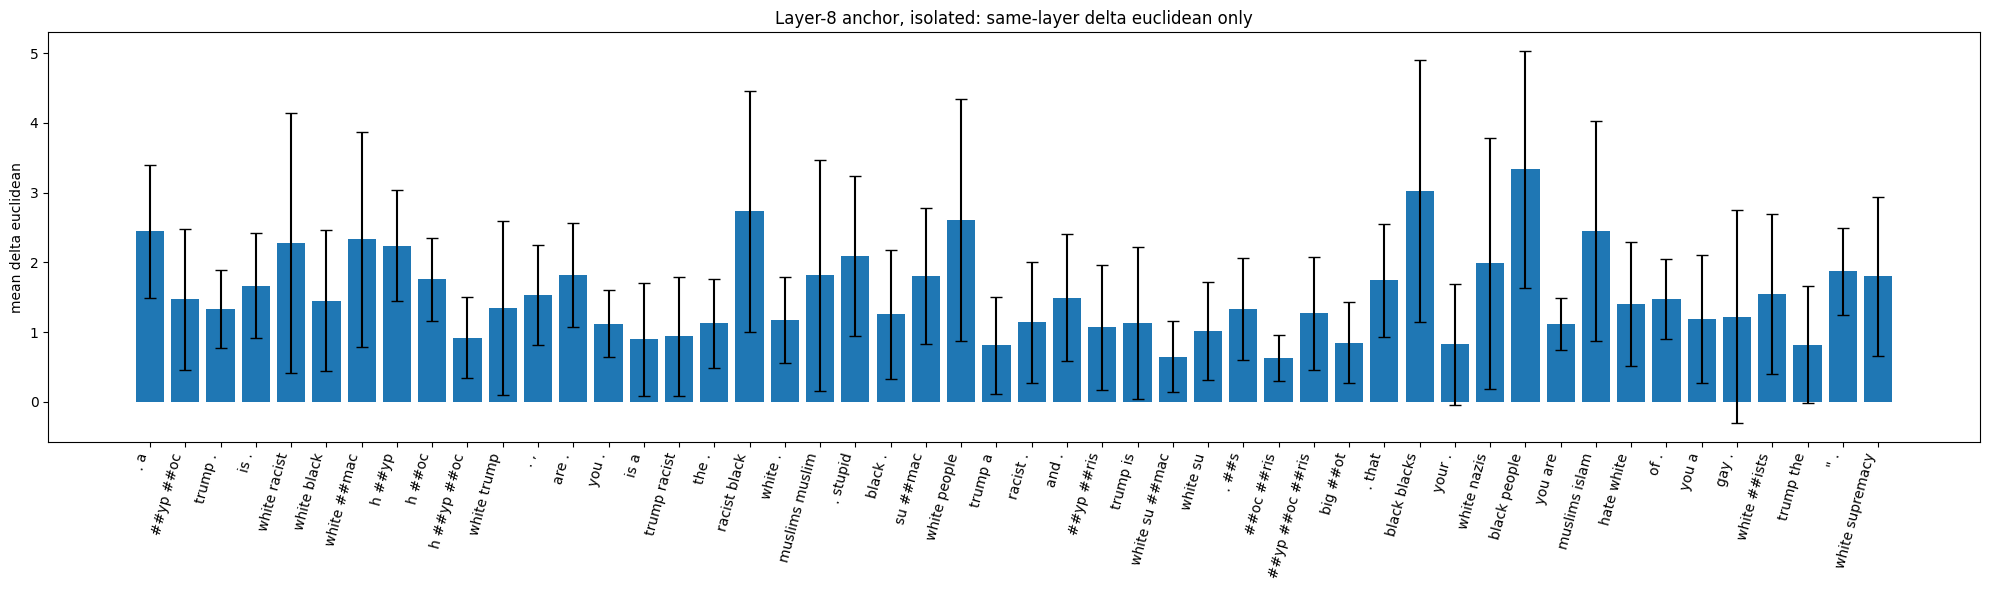

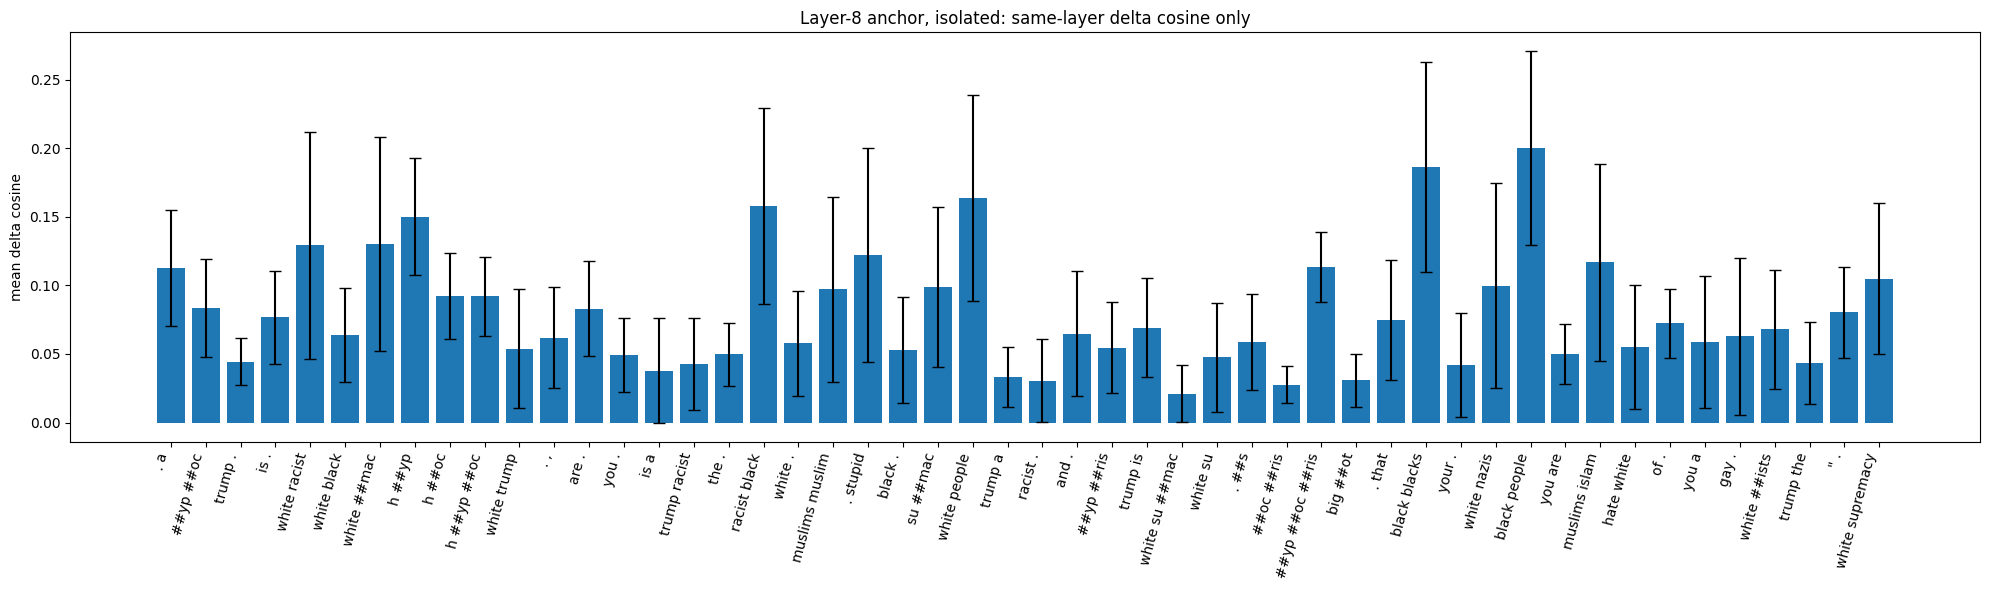

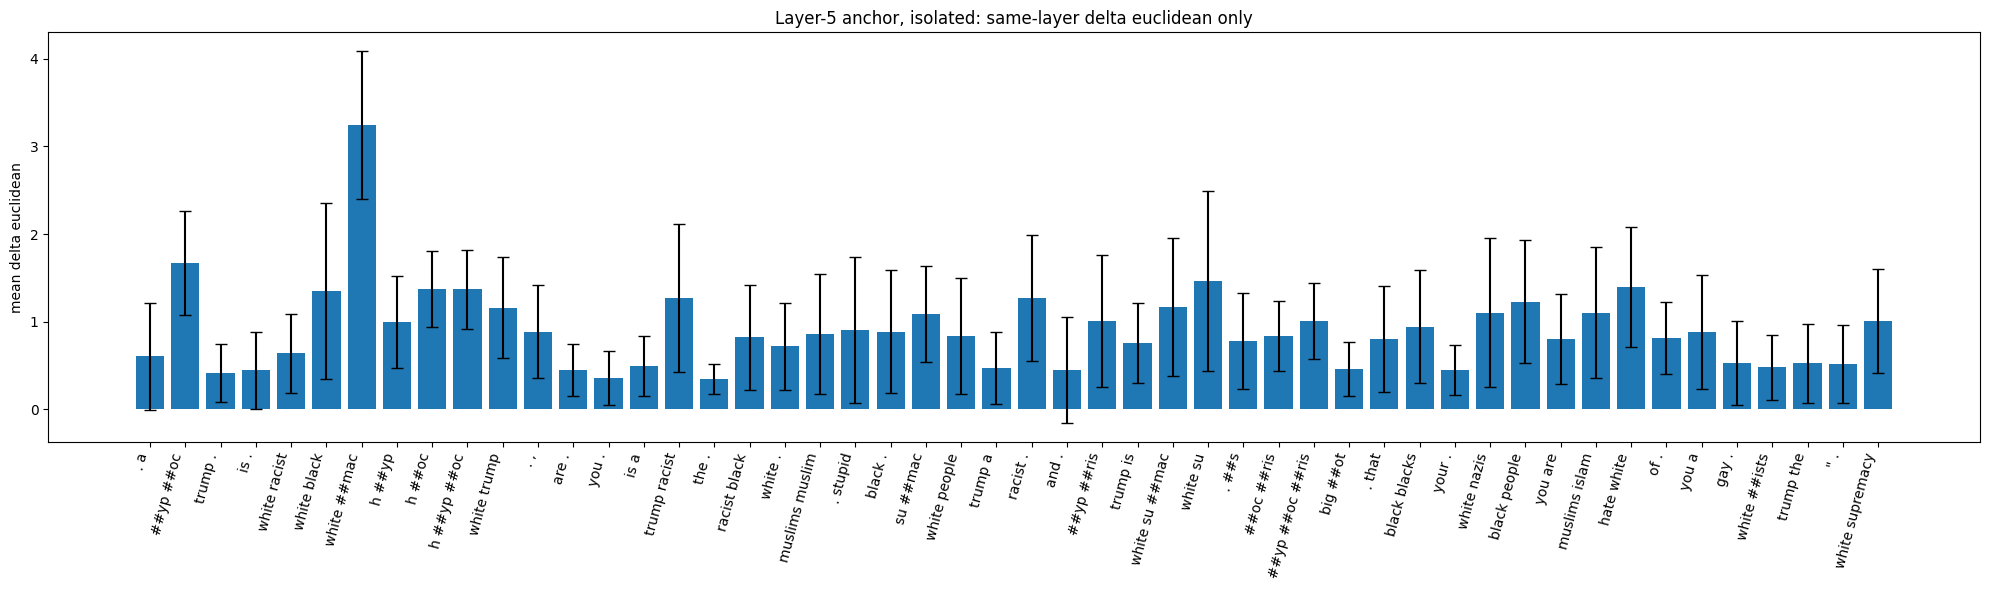

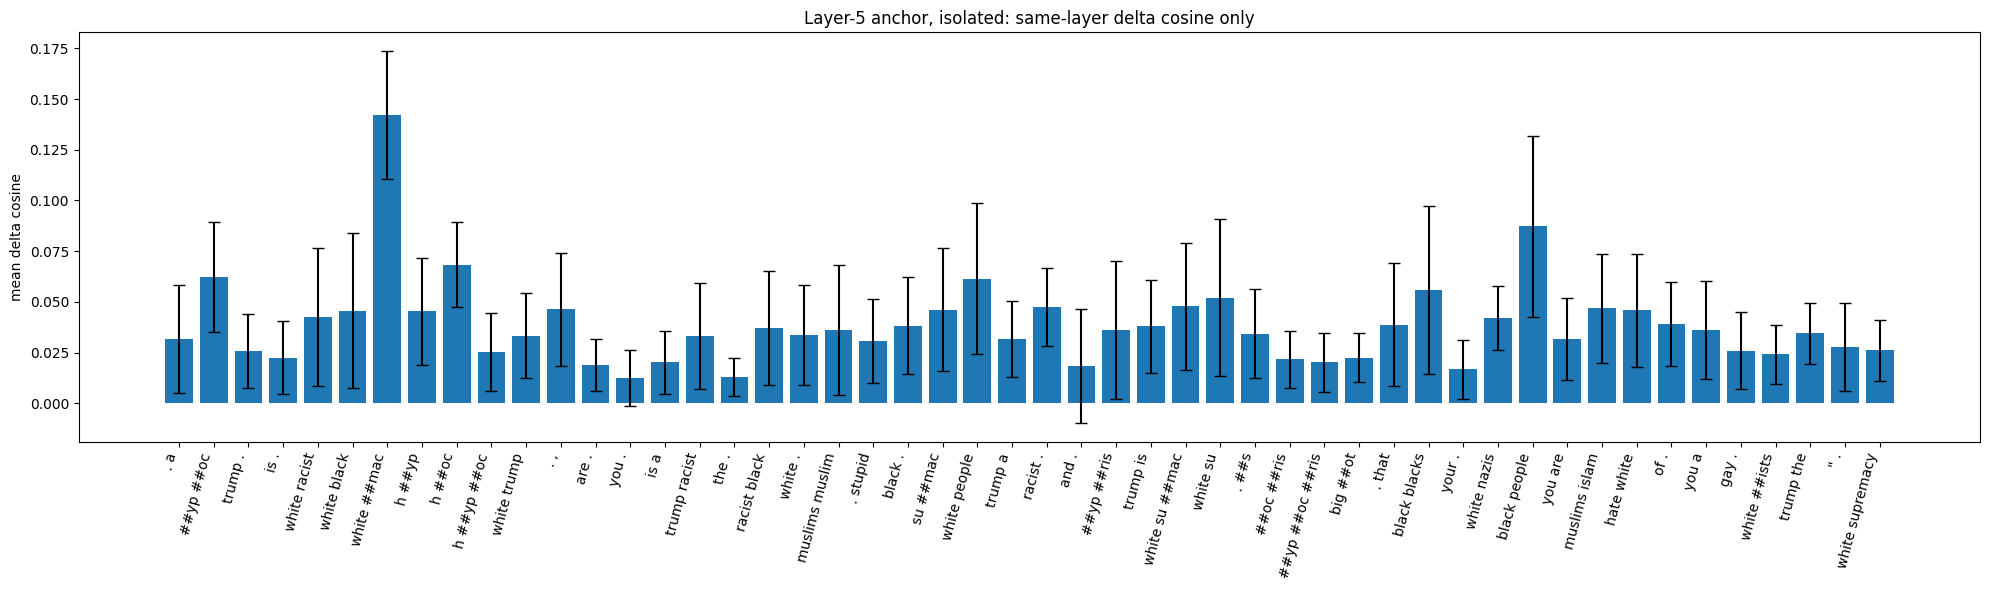

,label,mean_delta_l5_euclidean_l5,std_euclidean,mean_delta_l5_cosine_l5,std_cosine
63,. a,0.603680,0.611560,0.031648,0.026513
59,##yp ##oc,1.668328,0.591538,0.062407,0.027090
52,trump .,0.414032,0.330581,0.025722,0.018125
91,is .,0.446618,0.439353,0.022522,0.018073
50,white racist,0.638152,0.455252,0.042455,0.033986
75,white black,1.354264,1.002831,0.045661,0.038066
62,white ##mac,3.241309,0.846461,0.142107,0.031594
101,h ##yp,0.997539,0.520535,0.045353,0.026259
128,h ##oc,1.374357,0.435955,0.068304,0.020974
109,h ##yp ##oc,1.369691,0.450419,0.025356,0.019043


In [81]:
plot_anchor_same_layer_with_std(df_iso_l12, anchor_layer=12, context="iso")
plot_anchor_same_layer_with_std(df_iso_l11, anchor_layer=11, context="iso")
plot_anchor_same_layer_with_std(df_iso_l8,  anchor_layer=8,  context="iso")
plot_anchor_same_layer_with_std(df_iso_l5,  anchor_layer=5,  context="iso")

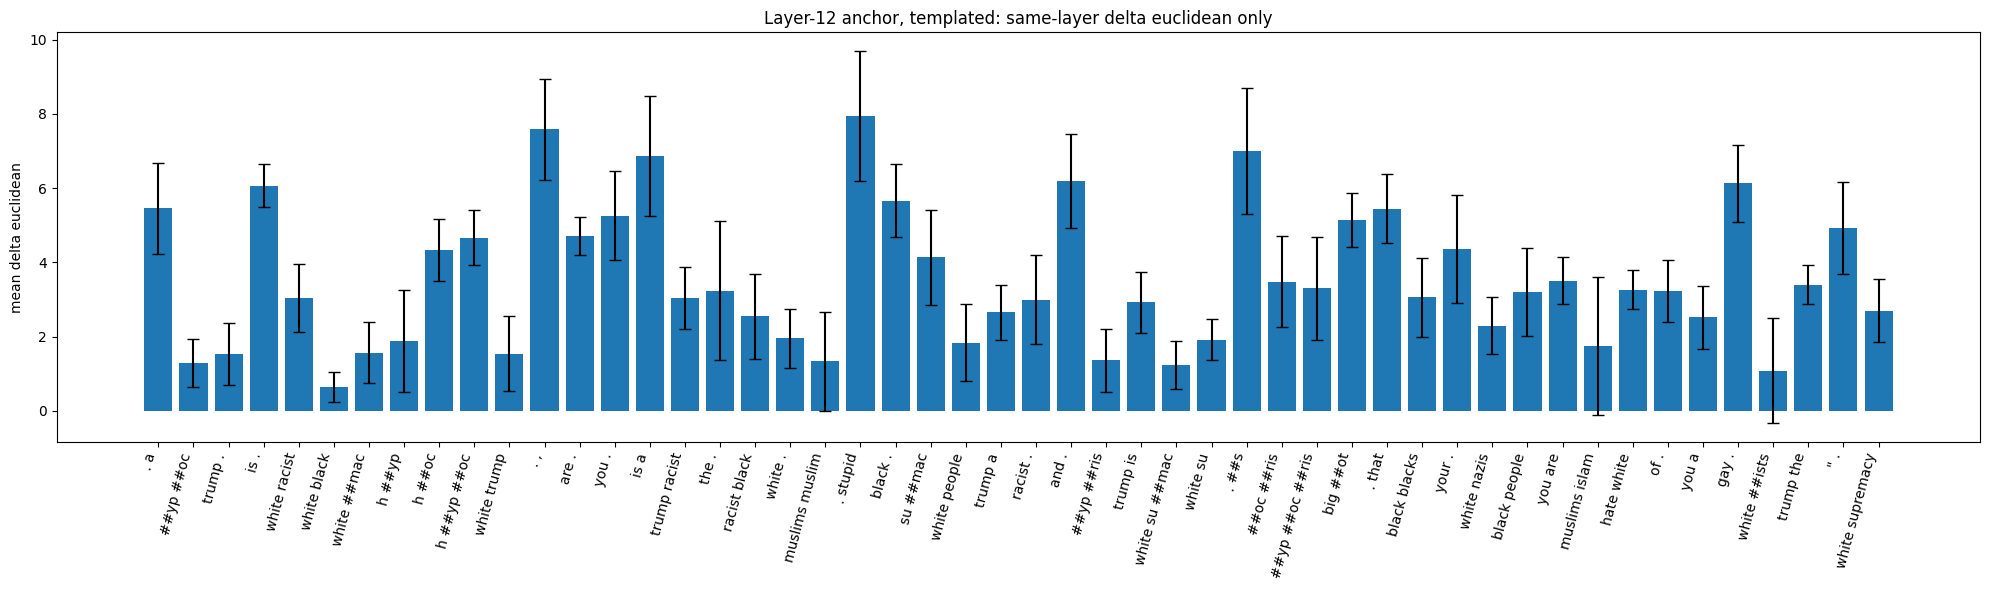

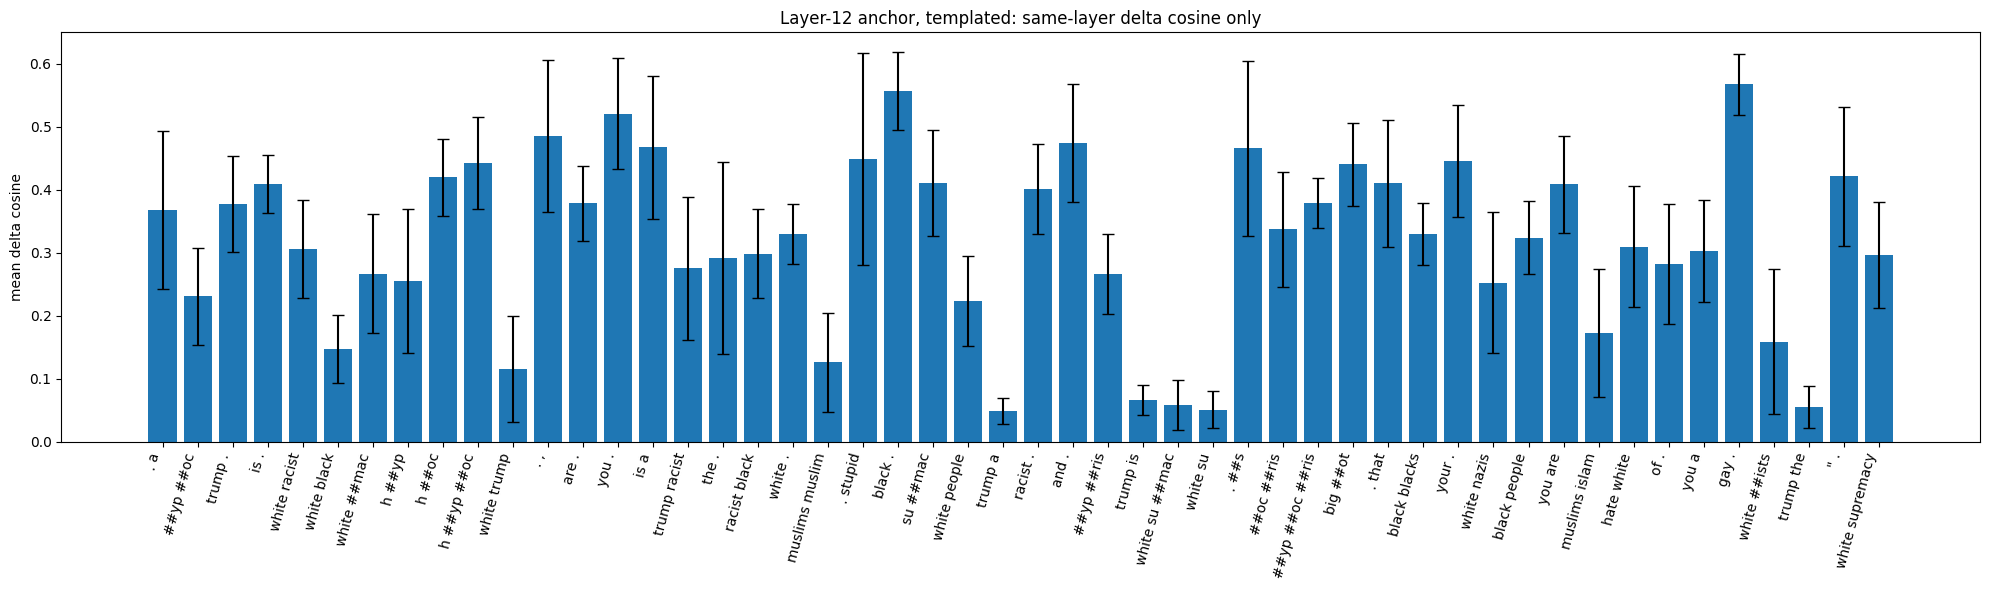

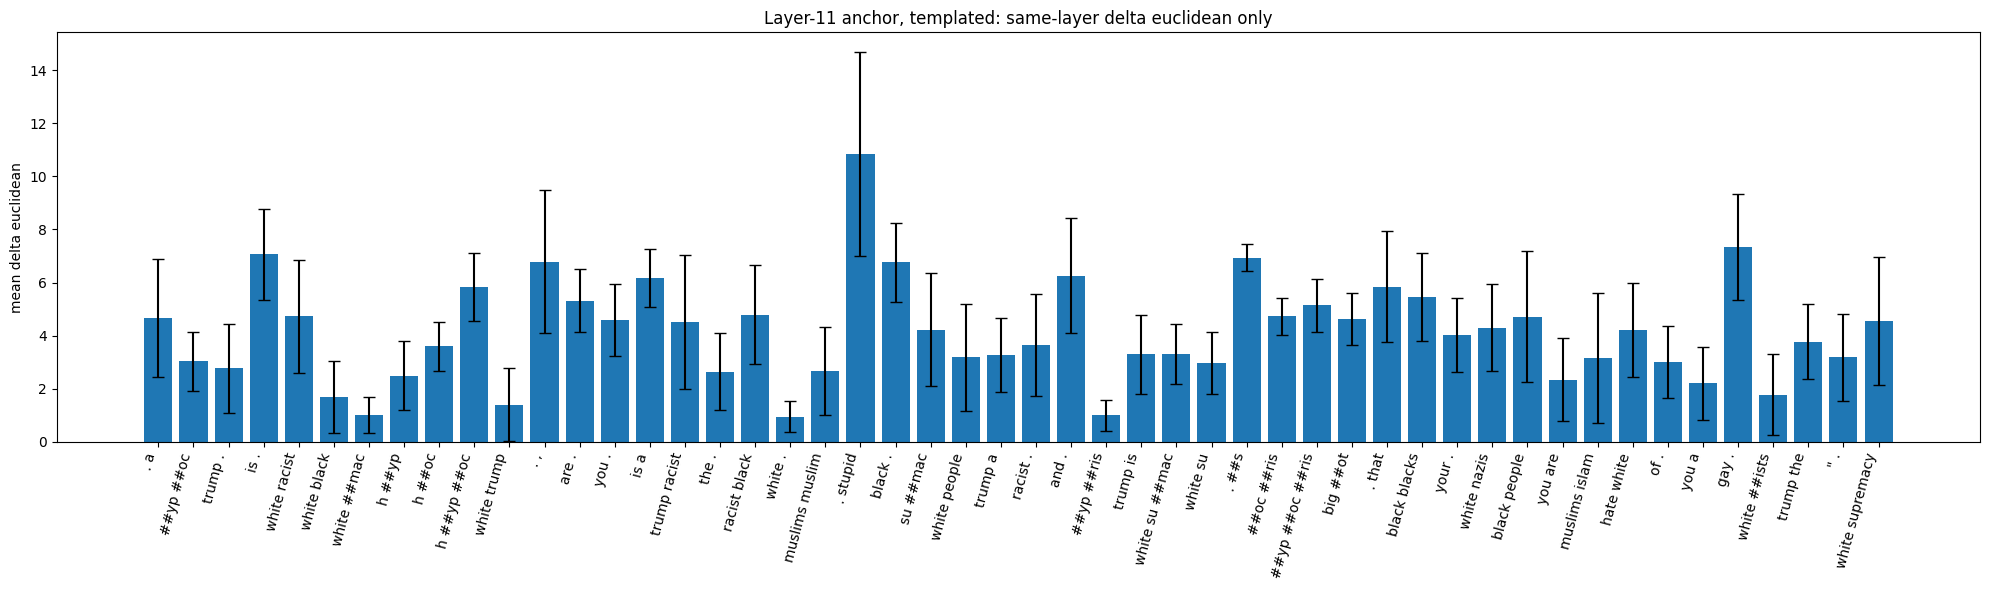

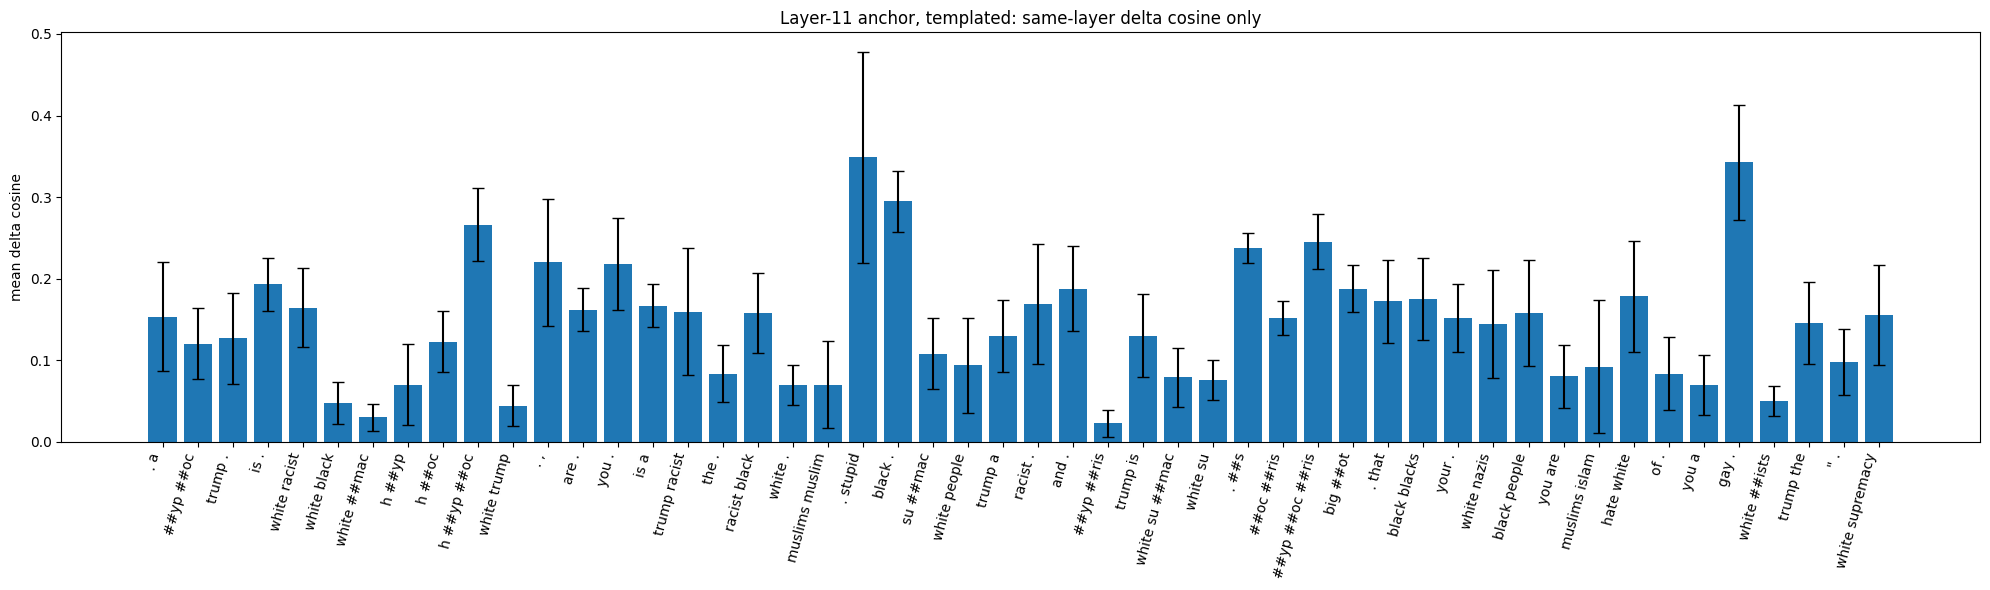

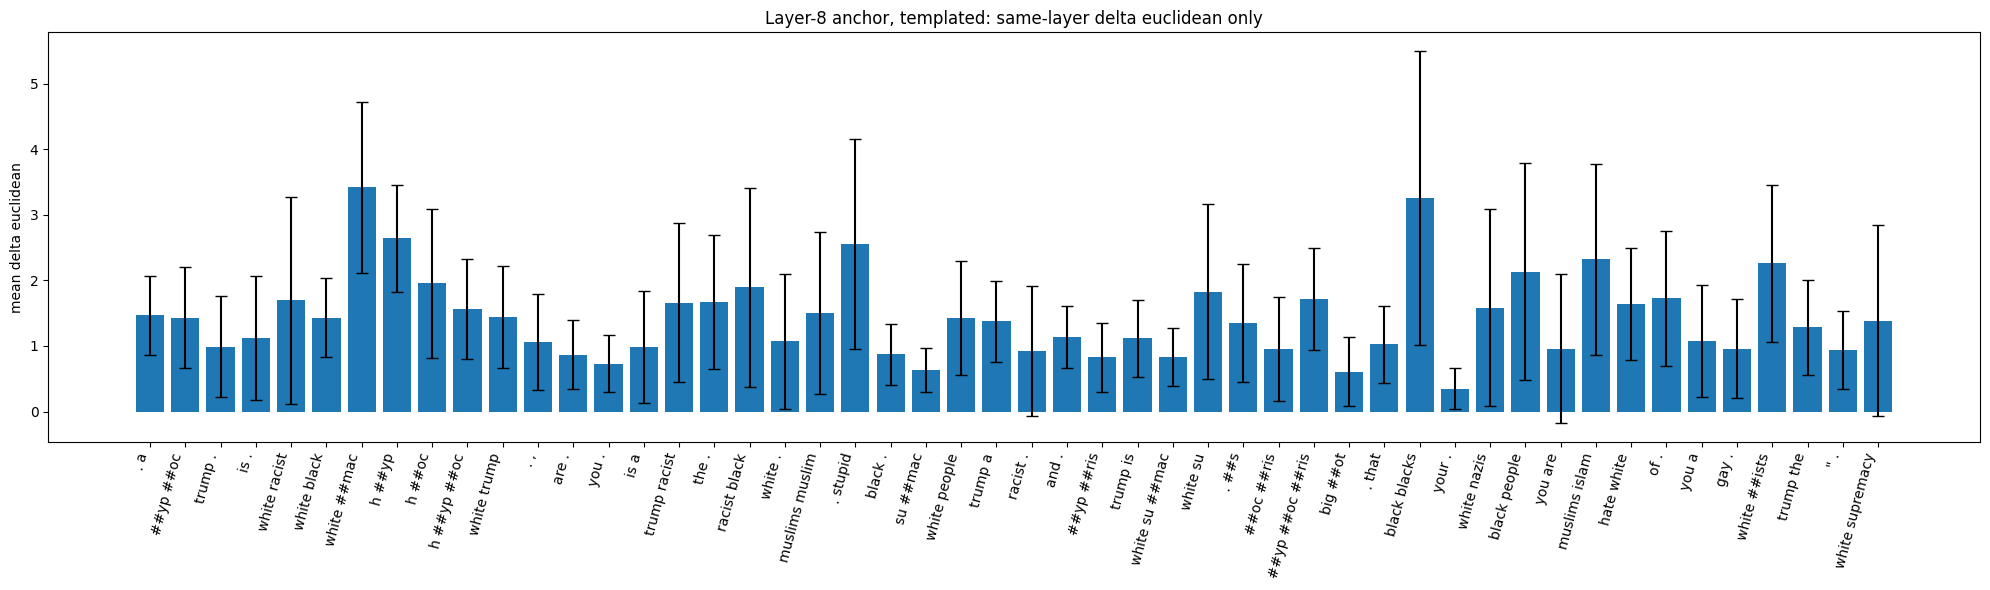

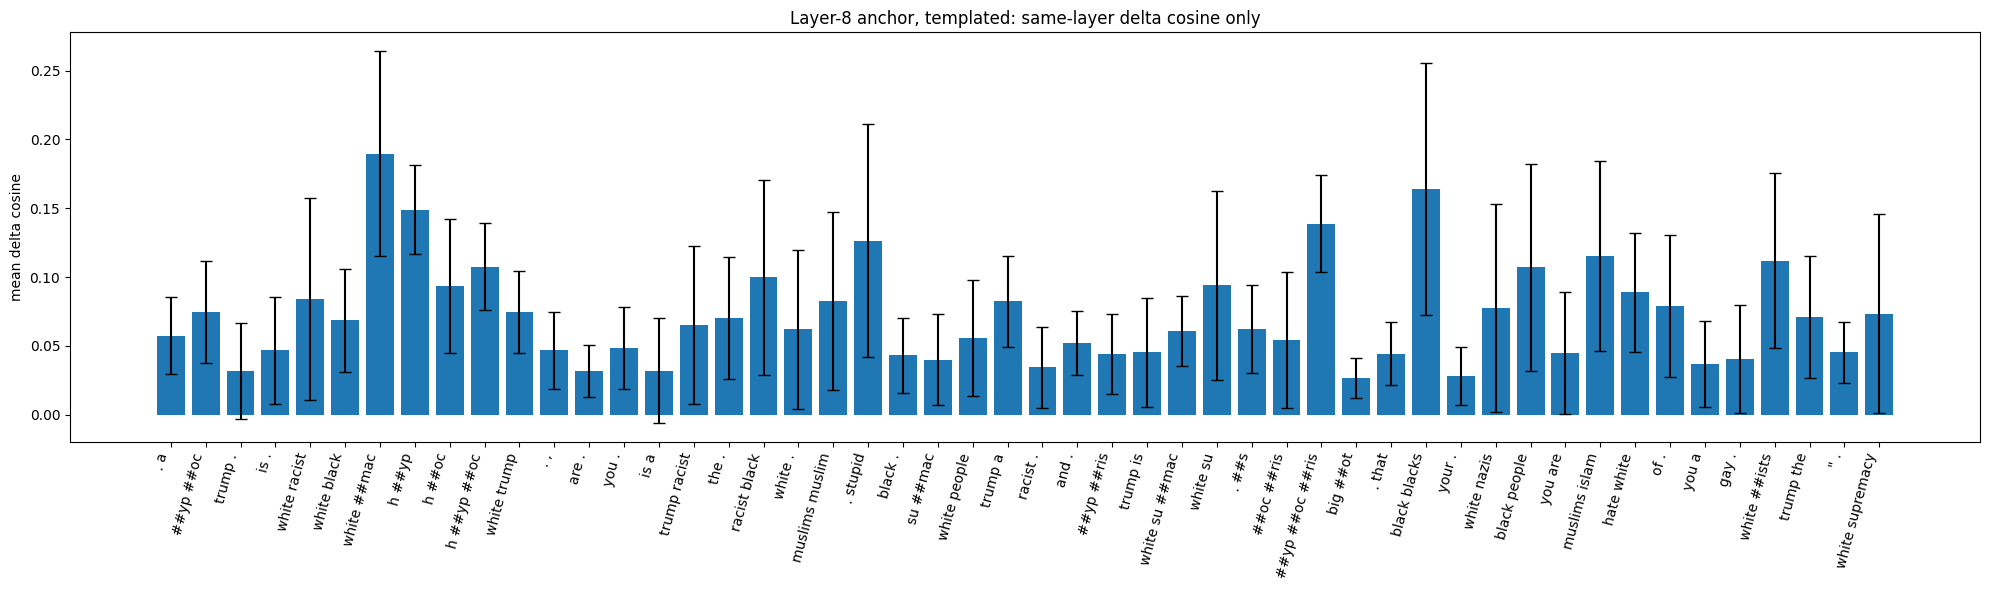

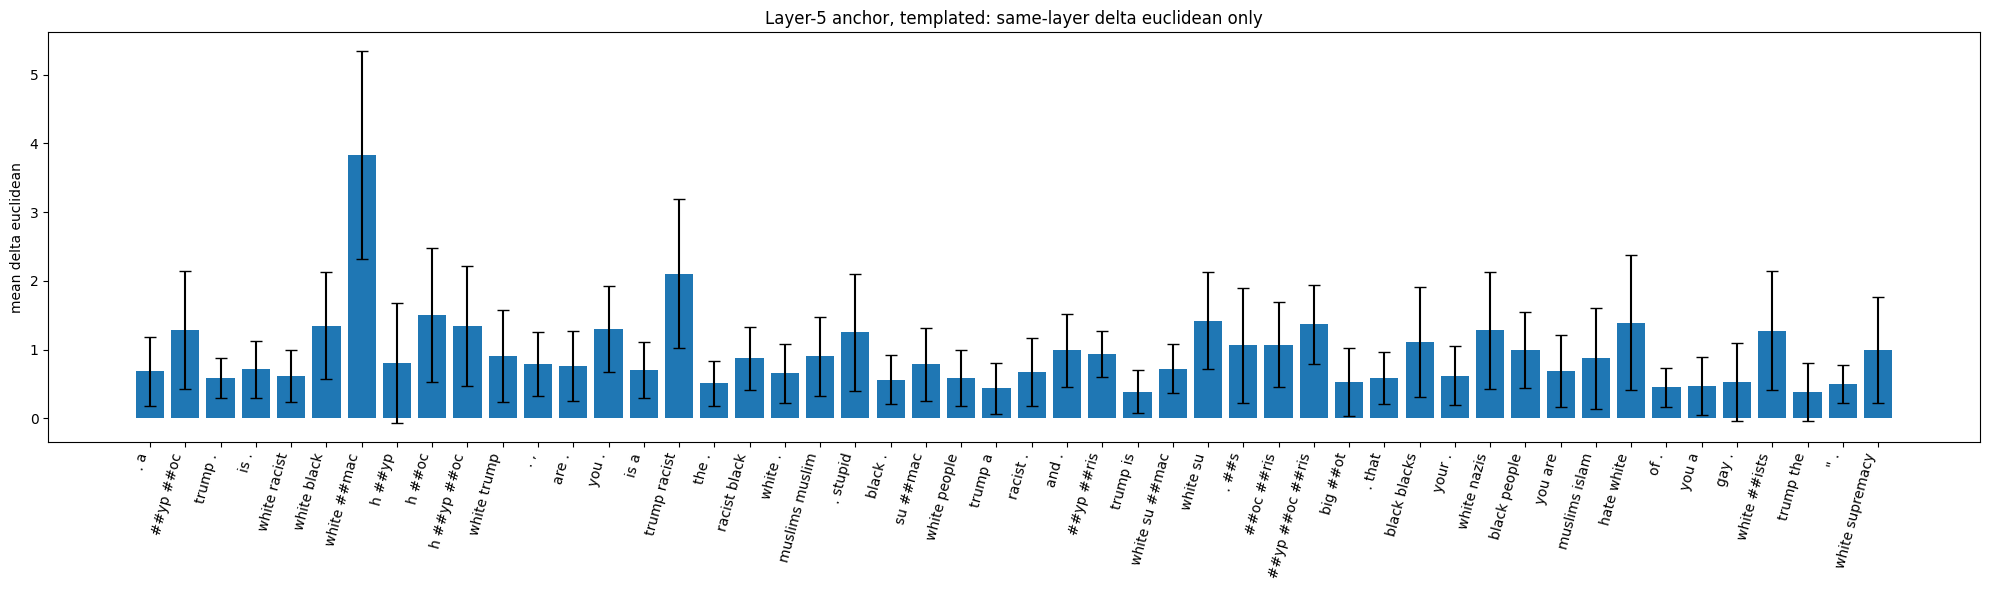

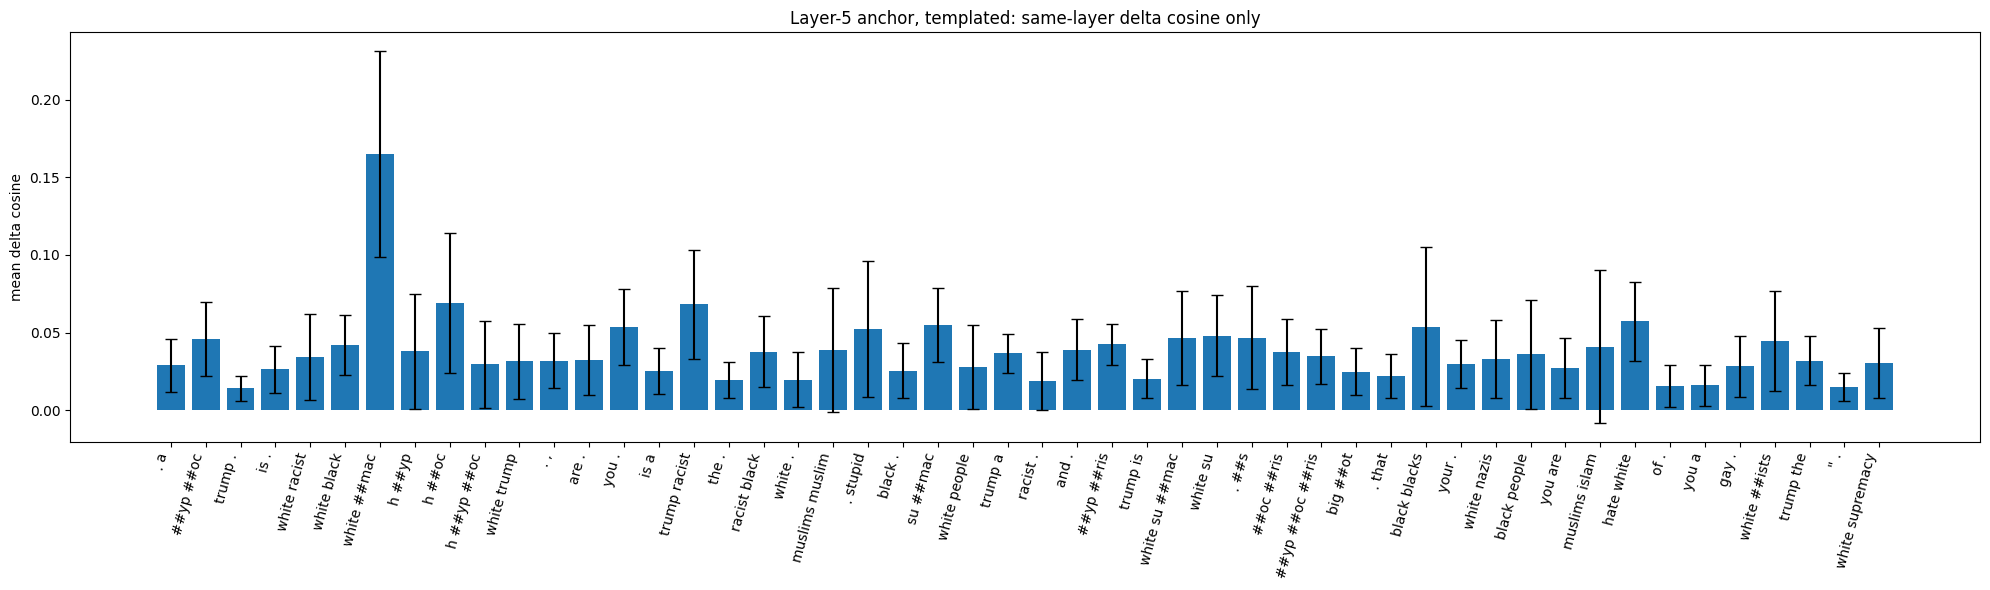

,label,mean_delta_tpl_l5_euclidean_l5,std_euclidean,mean_delta_tpl_l5_cosine_l5,std_cosine
63,. a,0.684110,0.501474,0.028863,0.017231
59,##yp ##oc,1.281934,0.855993,0.046053,0.023832
52,trump .,0.584513,0.291618,0.014157,0.008070
91,is .,0.712559,0.412762,0.026179,0.015408
50,white racist,0.615507,0.379628,0.034187,0.027463
75,white black,1.345023,0.777652,0.041973,0.019357
62,white ##mac,3.829532,1.513167,0.164981,0.066560
101,h ##yp,0.801819,0.872101,0.037787,0.036938
128,h ##oc,1.504039,0.969234,0.069157,0.045304
109,h ##yp ##oc,1.344027,0.871406,0.029603,0.027963


In [82]:
plot_anchor_same_layer_with_std(df_tpl_l12, anchor_layer=12, context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l11, anchor_layer=11, context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l8,  anchor_layer=8,  context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l5,  anchor_layer=5,  context="tpl")

---
## Summarize tables

Matched Anchor to layer: 12 ->12, 11->11, 8->8, 5->5

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANCHOR_LAYERS = (12, 11, 8, 5)

def build_matched_anchor_summary(anchor_dfs, context="iso"):
    """
    anchor_dfs:
        {
            12: df_anchor_12,
            11: df_anchor_11,
             8: df_anchor_8,
             5: df_anchor_5,
        }

    Uses only the diagonal / matched columns:
      anchor 12 -> layer 12
      anchor 11 -> layer 11
      anchor  8 -> layer  8
      anchor  5 -> layer  5
    """
    assert context in {"iso", "tpl"}

    def tokens_to_list(x):
        if isinstance(x, (list, tuple)):
            return [str(t).lower() for t in x]
        return [str(x).lower()]

    rows = []

    for anchor_layer in ANCHOR_LAYERS:
        df_plot = anchor_dfs[anchor_layer].copy()
        df_plot["token_list"] = df_plot["ordered_tokens"].apply(tokens_to_list)

        is_shortcut = df_plot["token_list"].apply(
            lambda toks: any(t in manual_shortcut_tokens for t in toks)
        )

        df_shortcut = df_plot[is_shortcut]
        df_non_shortcut = df_plot[~is_shortcut]

        if context == "iso":
            euc_col = f"mean_delta_l{anchor_layer}_euclidean_l{anchor_layer}"
            cos_col = f"mean_delta_l{anchor_layer}_cosine_l{anchor_layer}"
        else:
            euc_col = f"mean_delta_tpl_l{anchor_layer}_euclidean_l{anchor_layer}"
            cos_col = f"mean_delta_tpl_l{anchor_layer}_cosine_l{anchor_layer}"

        rows.append({
            "group": "shortcut",
            "layer": f"L{anchor_layer}",
            "mean_delta_euclidean": df_shortcut[euc_col].mean(),
            "std_delta_euclidean": df_shortcut[euc_col].std(),
            "mean_delta_cosine": df_shortcut[cos_col].mean(),
            "std_delta_cosine": df_shortcut[cos_col].std(),
        })

        rows.append({
            "group": "non_shortcut",
            "layer": f"L{anchor_layer}",
            "mean_delta_euclidean": df_non_shortcut[euc_col].mean(),
            "std_delta_euclidean": df_non_shortcut[euc_col].std(),
            "mean_delta_cosine": df_non_shortcut[cos_col].mean(),
            "std_delta_cosine": df_non_shortcut[cos_col].std(),
        })

    summary = pd.DataFrame(rows)
    layer_order = [f"L{L}" for L in ANCHOR_LAYERS]
    summary["layer"] = pd.Categorical(summary["layer"], categories=layer_order, ordered=True)
    summary = summary.sort_values(["layer", "group"]).reset_index(drop=True)

    return summary


def plot_matched_anchor_deltas(anchor_dfs, context="iso"):
    """
    Bar plots with std-dev error bars for matched anchor/layer deltas only.
    """
    summary = build_matched_anchor_summary(anchor_dfs, context=context)

    layer_order = [f"L{L}" for L in ANCHOR_LAYERS]
    shortcut = summary[summary["group"] == "shortcut"].set_index("layer").loc[layer_order]
    non_shortcut = summary[summary["group"] == "non_shortcut"].set_index("layer").loc[layer_order]

    x = np.arange(len(layer_order))
    width = 0.35

    if context == "iso":
        title_prefix = "Matched anchor/layer only, isolated"
    else:
        title_prefix = "Matched anchor/layer only, templated"

    # --- Euclidean ---
    plt.figure(figsize=(8, 5))
    plt.bar(
        x - width/2,
        shortcut["mean_delta_euclidean"].values,
        width,
        yerr=shortcut["std_delta_euclidean"].values,
        label="shortcut",
        capsize=4
    )
    plt.bar(
        x + width/2,
        non_shortcut["mean_delta_euclidean"].values,
        width,
        yerr=non_shortcut["std_delta_euclidean"].values,
        label="non_shortcut",
        capsize=4
    )
    plt.xticks(x, layer_order)
    plt.ylabel("average mean delta euclidean")
    plt.title(f"{title_prefix}: shortcut vs non-shortcut")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --- Cosine ---
    plt.figure(figsize=(8, 5))
    plt.bar(
        x - width/2,
        shortcut["mean_delta_cosine"].values,
        width,
        yerr=shortcut["std_delta_cosine"].values,
        label="shortcut",
        capsize=4
    )
    plt.bar(
        x + width/2,
        non_shortcut["mean_delta_cosine"].values,
        width,
        yerr=non_shortcut["std_delta_cosine"].values,
        label="non_shortcut",
        capsize=4
    )
    plt.xticks(x, layer_order)
    plt.ylabel("average mean delta cosine")
    plt.title(f"{title_prefix}: shortcut vs non-shortcut")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return summary

Df_Mean

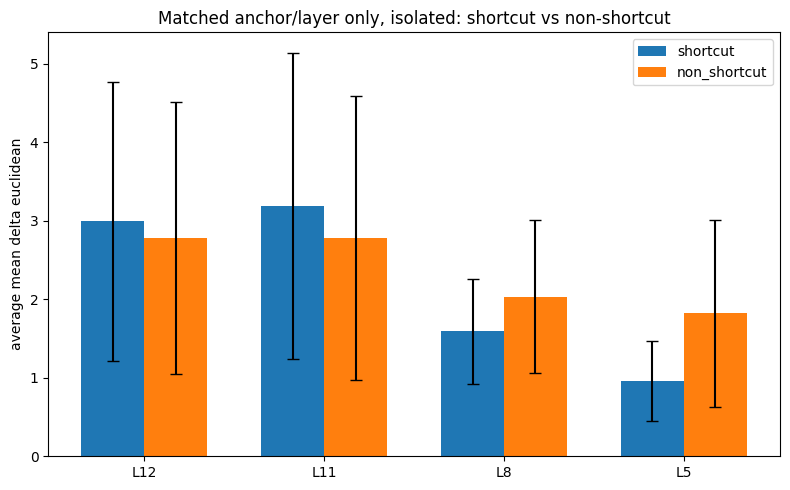

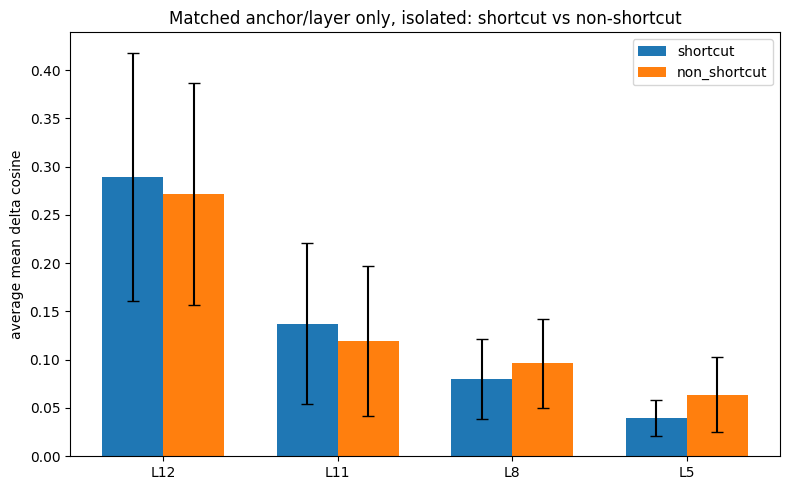

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_shortcut,L12,2.781166,1.738939,0.271876,0.115121
1,shortcut,L12,2.992237,1.779884,0.289628,0.128504
2,non_shortcut,L11,2.778144,1.808840,0.118942,0.077641
3,shortcut,L11,3.195112,1.950059,0.137391,0.083025
4,non_shortcut,L8,2.033634,0.975120,0.096103,0.046346
5,shortcut,L8,1.593703,0.670600,0.079742,0.041348
6,non_shortcut,L5,1.820844,1.192014,0.063856,0.038710
7,shortcut,L5,0.961510,0.506574,0.039742,0.018940


In [84]:
iso_anchor_dfs = {
    12: df_iso_l12,
    11: df_iso_l11,
     8: df_iso_l8,
     5: df_iso_l5,
}

summary_iso_matched = plot_matched_anchor_deltas(iso_anchor_dfs, context="iso")
summary_iso_matched

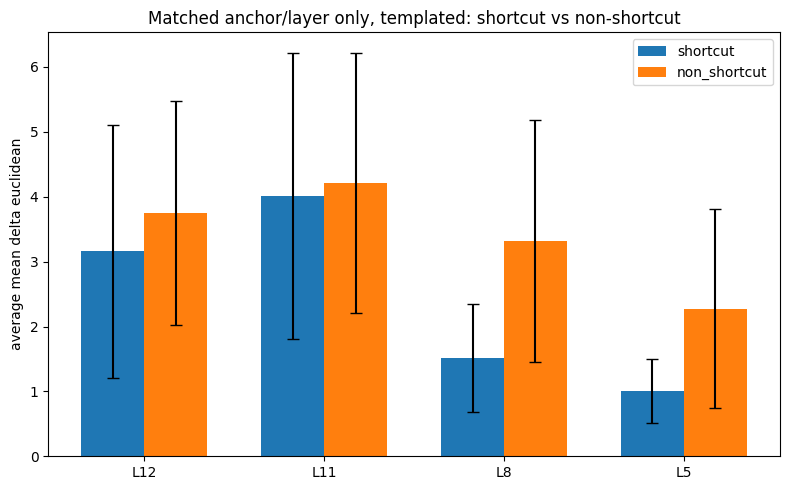

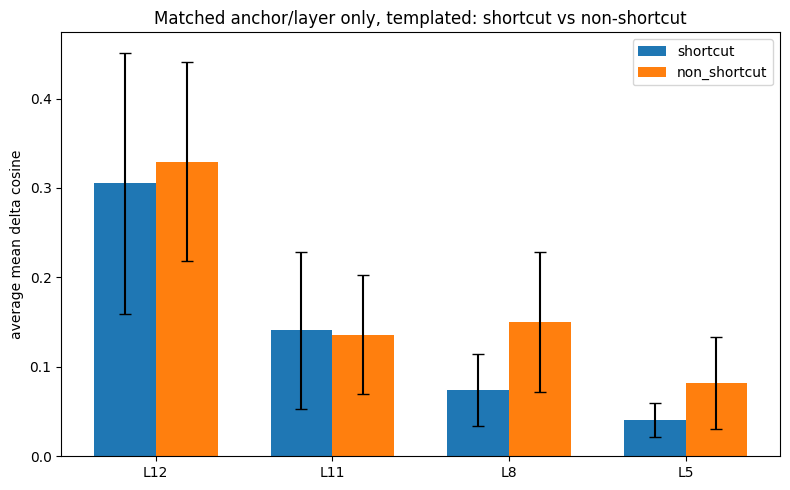

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_shortcut,L12,3.752921,1.723809,0.329251,0.111432
1,shortcut,L12,3.156277,1.951296,0.305098,0.146392
2,non_shortcut,L11,4.215557,2.006937,0.135748,0.066405
3,shortcut,L11,4.015427,2.203424,0.140670,0.087768
4,non_shortcut,L8,3.315793,1.866648,0.150014,0.078452
5,shortcut,L8,1.513715,0.834844,0.074456,0.040051
6,non_shortcut,L5,2.273456,1.530571,0.081963,0.051111
7,shortcut,L5,1.009120,0.494137,0.040693,0.018913


In [85]:
tpl_anchor_dfs = {
    12: df_tpl_l12,
    11: df_tpl_l11,
     8: df_tpl_l8,
     5: df_tpl_l5,
}

summary_tpl_matched = plot_matched_anchor_deltas(tpl_anchor_dfs, context="tpl")
summary_tpl_matched

DF_First

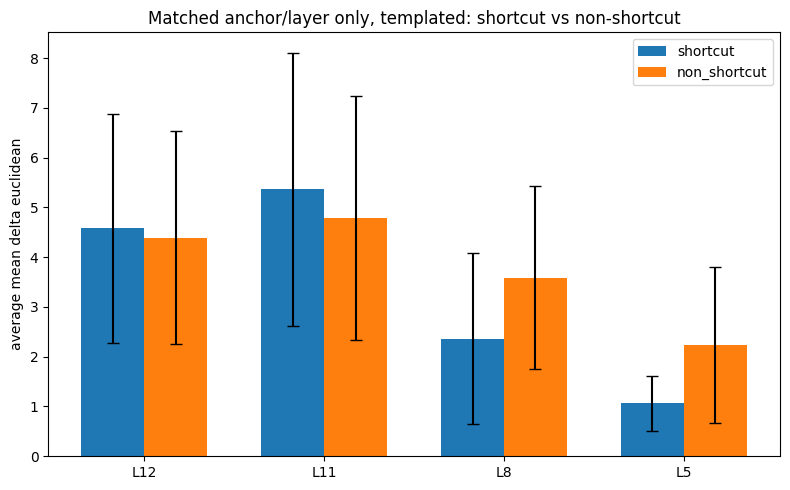

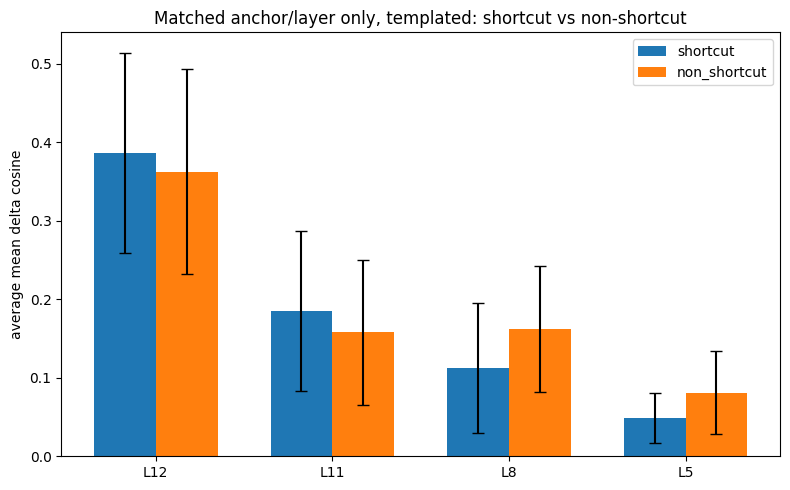

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_shortcut,L12,4.394006,2.143335,0.362932,0.130292
1,shortcut,L12,4.582685,2.297179,0.386890,0.127727
2,non_shortcut,L11,4.788016,2.446713,0.157838,0.092458
3,shortcut,L11,5.365793,2.745226,0.185708,0.101973
4,non_shortcut,L8,3.589518,1.845287,0.161951,0.080524
5,shortcut,L8,2.364434,1.717294,0.112805,0.082507
6,non_shortcut,L5,2.234725,1.558640,0.081125,0.052645
7,shortcut,L5,1.069347,0.553033,0.048789,0.031449


In [86]:
df_tpl_first_l12 = run_anchor_analysis(df_first_token, token_df, anchor_layer=12, context="tpl")
df_tpl_first_l11 = run_anchor_analysis(df_first_token, token_df, anchor_layer=11, context="tpl")
df_tpl_first_l8  = run_anchor_analysis(df_first_token, token_df, anchor_layer=8,  context="tpl")
df_tpl_first_l5  = run_anchor_analysis(df_first_token, token_df, anchor_layer=5,  context="tpl")

tpl_first_anchor_dfs = {
    12: df_tpl_first_l12,
    11: df_tpl_first_l11,
     8: df_tpl_first_l8,
     5: df_tpl_first_l5,
}

summary_tpl_first_matched = plot_matched_anchor_deltas(tpl_first_anchor_dfs, context="tpl")
summary_tpl_first_matched

DF_Sum

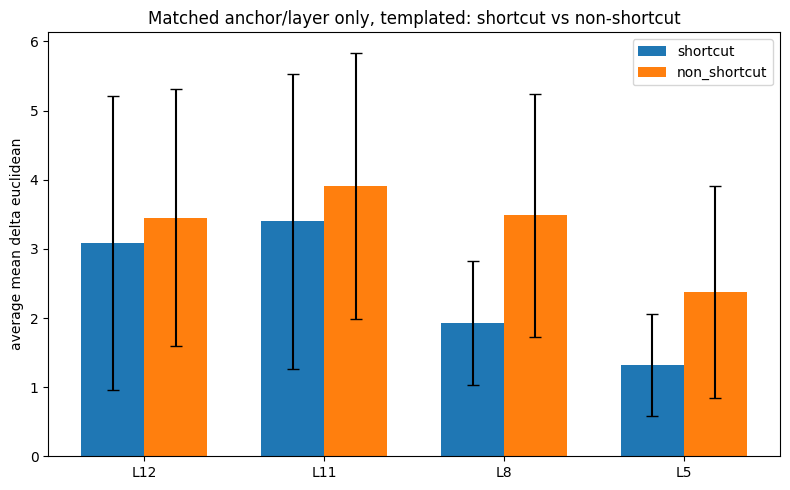

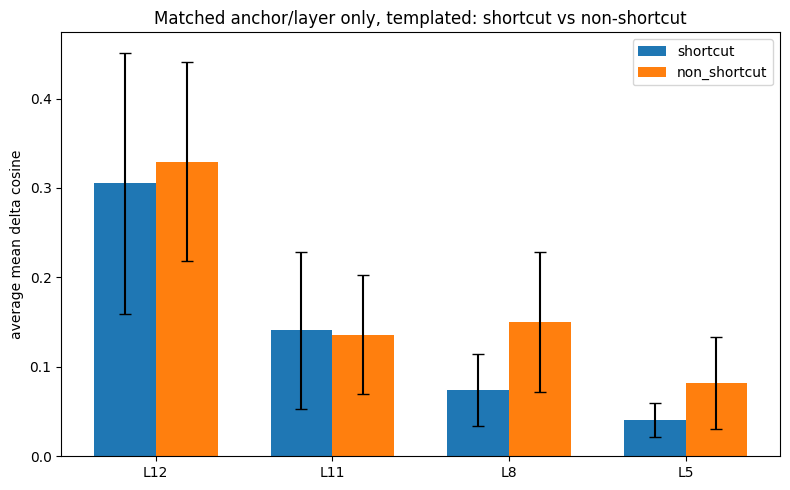

,group,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_shortcut,L12,3.449590,1.858012,0.329251,0.111432
1,shortcut,L12,3.087731,2.129425,0.305098,0.146392
2,non_shortcut,L11,3.915050,1.925108,0.135748,0.066405
3,shortcut,L11,3.398555,2.134578,0.140670,0.087768
4,non_shortcut,L8,3.483121,1.757381,0.150014,0.078452
5,shortcut,L8,1.926334,0.900736,0.074456,0.040051
6,non_shortcut,L5,2.379739,1.531293,0.081963,0.051111
7,shortcut,L5,1.324251,0.735005,0.040693,0.018913


In [87]:
df_tpl_sum_l12 = run_anchor_analysis(df_sum, token_df, anchor_layer=12, context="tpl")
df_tpl_sum_l11 = run_anchor_analysis(df_sum, token_df, anchor_layer=11, context="tpl")
df_tpl_sum_l8  = run_anchor_analysis(df_sum, token_df, anchor_layer=8,  context="tpl")
df_tpl_sum_l5  = run_anchor_analysis(df_sum, token_df, anchor_layer=5,  context="tpl")

tpl_sum_anchor_dfs = {
    12: df_tpl_sum_l12,
    11: df_tpl_sum_l11,
     8: df_tpl_sum_l8,
     5: df_tpl_sum_l5,
}

summary_tpl_sum_matched = plot_matched_anchor_deltas(tpl_sum_anchor_dfs, context="tpl")
summary_tpl_sum_matched